## Right now our agent can imagine futures, but it has no value signal to rank them — **so planning is blind.**
We now add `value`, not more imagination.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class MazeEnv:
    def __init__(self, maze):
        self.maze = maze
        self.height, self.width = maze.shape
        self.start_pos = tuple(np.argwhere(maze == 2)[0])
        self.goal_pos = tuple(np.argwhere(maze == 3)[0])
        self.reset()

    def reset(self):
        self.agent_pos = self.start_pos
        return self.agent_pos

    def step(self, action):
        moves = {
            0: (-1, 0),  # up
            1: (1, 0),   # down
            2: (0, -1),  # left
            3: (0, 1)    # right
        }

        dx, dy = moves[action]
        x, y = self.agent_pos
        nx, ny = x + dx, y + dy

        # Check boundaries and walls
        if 0 <= nx < self.height and 0 <= ny < self.width:
            if self.maze[nx, ny] != 1:
                self.agent_pos = (nx, ny)

        reward = 1 if self.agent_pos == self.goal_pos else 0
        done = self.agent_pos == self.goal_pos

        return self.agent_pos, reward, done


def render(
    env,
    imagined_paths=None,
    chosen_path=None,
    title="Maze Environment"
):
    """
    imagined_paths: list of lists of (x, y) tuples
    chosen_path: list of (x, y) tuples
    """

    fig, ax = plt.subplots(figsize=(5, 5))

    # --- Draw maze background ---
    for x in range(env.height):
        for y in range(env.width):
            if env.maze[x, y] == 1:      # wall
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="black"))
            else:                        # free space
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="white"))

    # --- Draw start & goal ---
    sx, sy = env.start_pos
    gx, gy = env.goal_pos

    ax.text(sy + 0.5, sx + 0.5, "S", ha="center", va="center", fontsize=12)
    ax.text(gy + 0.5, gx + 0.5, "G", ha="center", va="center", fontsize=12)

    # --- Draw imagined trajectories (future use) ---
    if imagined_paths is not None:
        for path in imagined_paths:
            xs = [y + 0.5 for x, y in path]
            ys = [x + 0.5 for x, y in path]
            ax.plot(xs, ys, linestyle="dotted", alpha=0.4, color="blue")

    # --- Draw chosen path (future use) ---
    if chosen_path is not None:
        xs = [y + 0.5 for x, y in chosen_path]
        ys = [x + 0.5 for x, y in chosen_path]
        ax.plot(xs, ys, linewidth=2.5, color="red")

    # --- Draw agent ---
    ax.scatter(
        env.agent_pos[1] + 0.5,
        env.agent_pos[0] + 0.5,
        s=200,
        color="orange",
        zorder=5
    )

    # --- Formatting ---
    ax.set_xlim(0, env.width)
    ax.set_ylim(env.height, 0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.set_aspect("equal")

    plt.show()


def render(
    env,
    imagined_paths=None,
    chosen_path=None,
    title="Maze Environment"
):
    """
    imagined_paths: list of lists of (x, y) tuples
    chosen_path: list of (x, y) tuples
    """

    fig, ax = plt.subplots(figsize=(5, 5))

    # --- Draw maze background ---
    for x in range(env.height):
        for y in range(env.width):
            if env.maze[x, y] == 1:      # wall
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="black"))
            else:                        # free space
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="white"))

    # --- Draw start & goal ---
    sx, sy = env.start_pos
    gx, gy = env.goal_pos

    ax.text(sy + 0.5, sx + 0.5, "S", ha="center", va="center", fontsize=12)
    ax.text(gy + 0.5, gx + 0.5, "G", ha="center", va="center", fontsize=12)

    # --- Draw imagined trajectories (future use) ---
    if imagined_paths is not None:
        for path in imagined_paths:
            xs = [y + 0.5 for x, y in path]
            ys = [x + 0.5 for x, y in path]
            ax.plot(xs, ys, linestyle="dotted", alpha=0.4, color="blue")

    # --- Draw chosen path (future use) ---
    if chosen_path is not None:
        xs = [y + 0.5 for x, y in chosen_path]
        ys = [x + 0.5 for x, y in chosen_path]
        ax.plot(xs, ys, linewidth=2.5, color="red")

    # --- Draw agent ---
    ax.scatter(
        env.agent_pos[1] + 0.5,
        env.agent_pos[0] + 0.5,
        s=200,
        color="orange",
        zorder=5
    )

    # --- Formatting ---
    ax.set_xlim(0, env.width)
    ax.set_ylim(env.height, 0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.set_aspect("equal")

    plt.show()


import numpy as np
maze = np.array([
    [2, 0, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 3]
])
HEIGHT, WIDTH = maze.shape

env = MazeEnv(maze)


In [2]:
class WorldModel:
    def __init__(self):
        # (state, action) -> next_state
        self.transitions = {}

        # (state, action) -> reward
        self.rewards = {}

    def update(self, state, action, next_state, reward):
        self.transitions[(state, action)] = next_state
        self.rewards[(state, action)] = reward

    def predict_next_state(self, state, action):
        return self.transitions.get((state, action), None)

    def predict_reward(self, state, action):
        return self.rewards.get((state, action), 0)


In [3]:
def run_agent_episode(env, agent, max_steps=50, delay=0.4):
    state = env.reset()
    render(env, title="Agent Starting")

    for step in range(max_steps):

        action, imagined_paths, chosen_path = agent.plan_and_act(state)

        # 🧠 visualize imagination BEFORE acting
        if imagined_paths is not None:
            render(
                env,
                imagined_paths=imagined_paths,
                chosen_path=chosen_path,
                title=f"Thinking (Step {step+1})"
            )

        next_state, reward, done = env.step(action)

        # 🧠 learn from real experience
        agent.learn_model(state, action, next_state, reward)

        state = next_state

        render(env, title=f"Acting (Step {step+1})")

        if done:
            print(f"🎯 Reached goal in {step+1} steps")
            return

    print("❌ Episode ended without reaching goal")


In [4]:
# Agent
import random
from collections import defaultdict

class Agent:
    def __init__(
        self,
        action_space=4,
        epsilon=0.1,
        imagination_horizon=6,
        imagination_rollouts=10,
        alpha=0.1,
        gamma=0.95
    ):
        self.action_space = action_space
        self.epsilon = epsilon

        self.imagination_horizon = imagination_horizon
        self.imagination_rollouts = imagination_rollouts

        self.alpha = alpha
        self.gamma = gamma

        self.world_model = WorldModel()

        # 🧠 VALUE FUNCTION
        self.Q = defaultdict(float)
    def learn_model(self, state, action, next_state, reward):
        # update world model
        self.world_model.update(state, action, next_state, reward)
    
        # 🔑 Q-learning update
        best_next = max(
            self.Q[(next_state, a)] for a in range(self.action_space)
        )
        self.Q[(state, action)] += self.alpha * (
            reward + self.gamma * best_next - self.Q[(state, action)]
        )

    def is_confident(self, state, threshold=0.5):
        q_vals = [self.Q[(state, a)] for a in range(self.action_space)]
        return max(q_vals) - min(q_vals) > threshold


    def plan_and_act(self, state):
        # exploration always allowed
        if random.random() < self.epsilon:
            return random.randint(0, self.action_space - 1), None, None
    
        # 🔒 confidence gate
        if not self.is_confident(state):
            # model-free greedy fallback
            best_a = max(
                range(self.action_space),
                key=lambda a: self.Q[(state, a)]
            )
            return best_a, None, None
    
        # ✅ planning allowed only if confident
        imagined_paths = []
        action_values = {}
    
        for action in range(self.action_space):
            values = []
            paths = []
    
            for _ in range(self.imagination_rollouts):
                path, val = imagine_rollout(
                    self.world_model,
                    self.Q,
                    state,
                    action,
                    self.imagination_horizon,
                    self.action_space
                )
                if len(path) > 1:
                    values.append(val)
                    paths.append(path)
    
            if values:
                action_values[action] = sum(values) / len(values)
                imagined_paths.extend(paths)
    
        if not action_values:
            return random.randint(0, self.action_space - 1), None, None
    
        best_action = max(action_values, key=action_values.get)
        best_path, _ = imagine_rollout(
            self.world_model,
            self.Q,
            state,
            best_action,
            self.imagination_horizon,
            self.action_space
        )
    
        return best_action, imagined_paths, best_path



In [5]:
def imagine_rollout(world_model, Q, start_state, first_action, horizon, action_space):
    state = start_state
    path = [state]

    # take first action explicitly
    action = first_action

    for _ in range(horizon):
        next_state = world_model.predict_next_state(state, action)
        if next_state is None:
            break

        path.append(next_state)

        # greedy imagined action (planning)
        action = max(
            range(action_space),
            key=lambda a: Q[(next_state, a)]
        )

        state = next_state

    # 🔑 value of trajectory = value of final imagined state
    value = max(Q[(state, a)] for a in range(action_space))
    return path, value


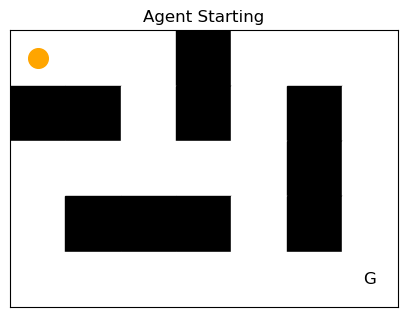

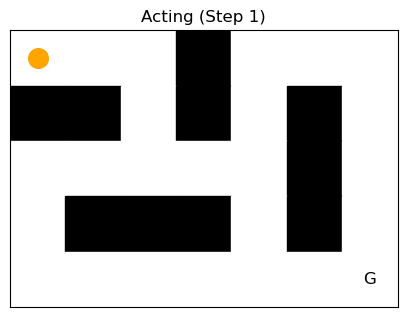

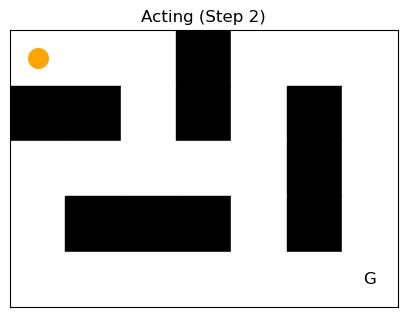

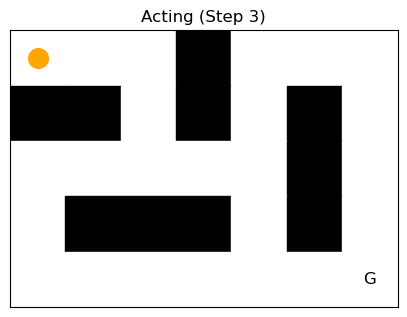

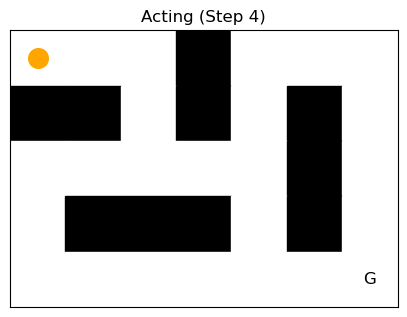

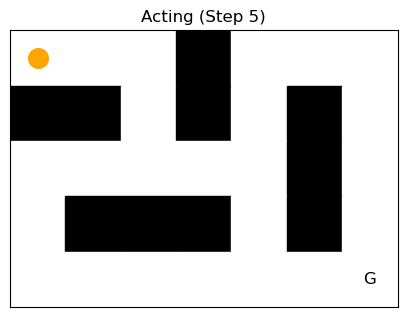

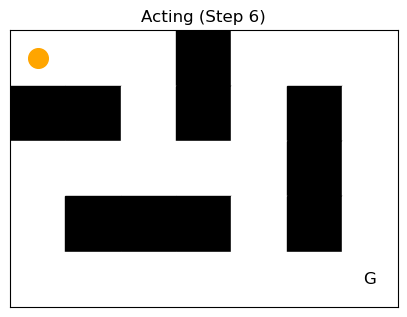

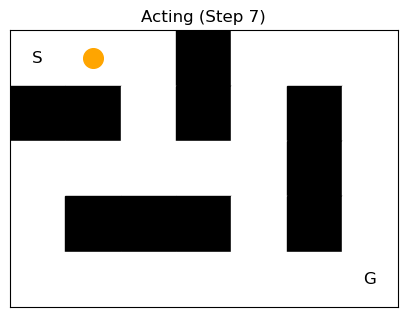

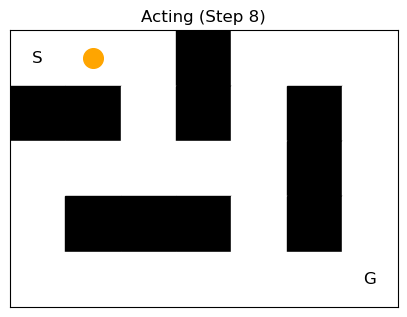

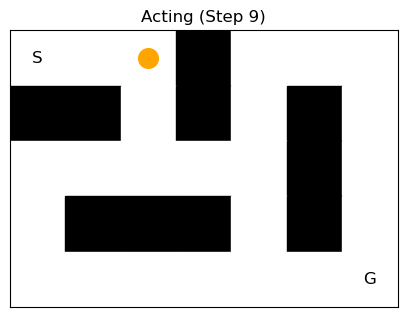

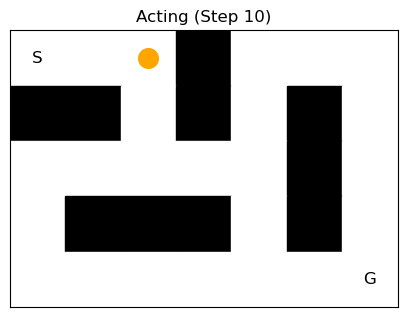

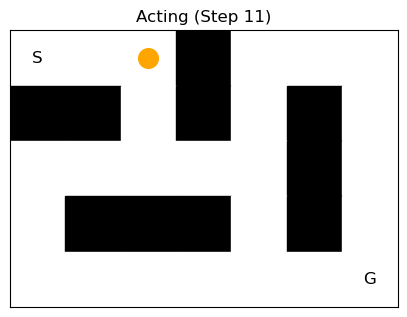

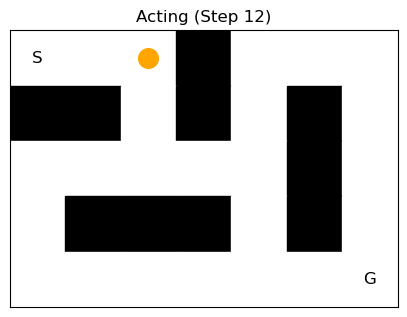

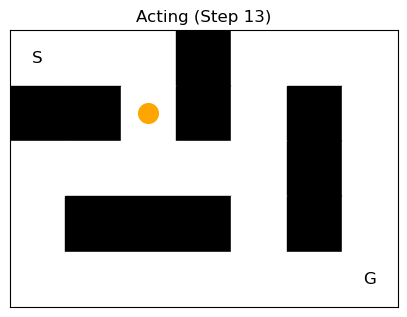

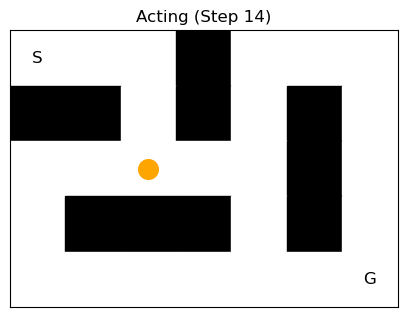

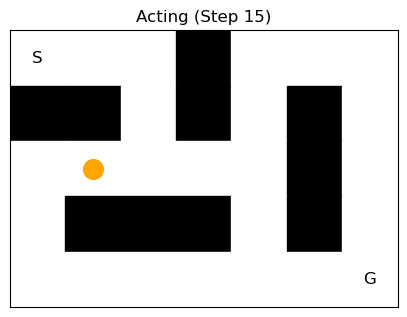

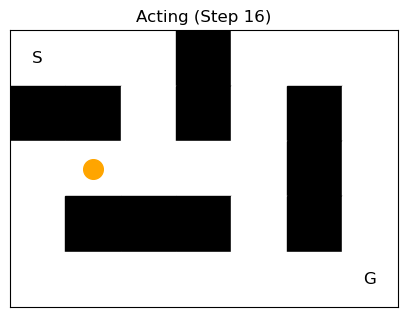

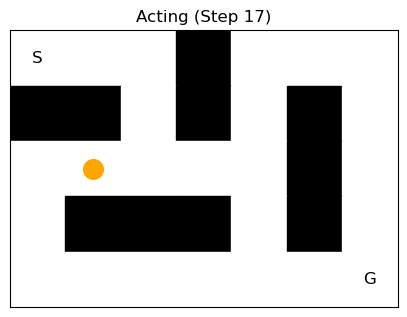

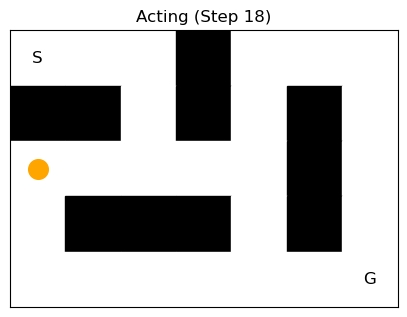

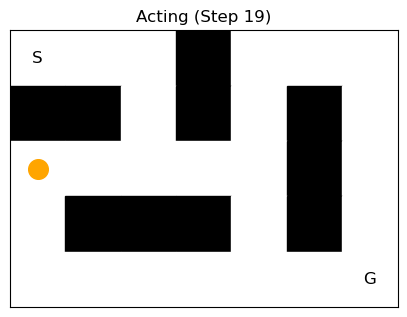

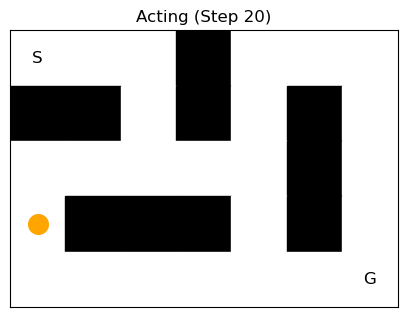

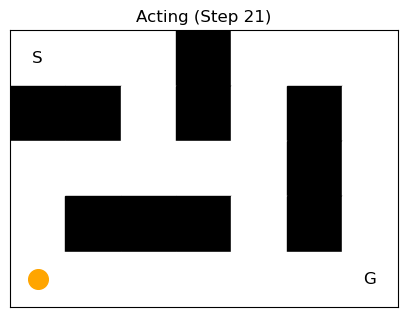

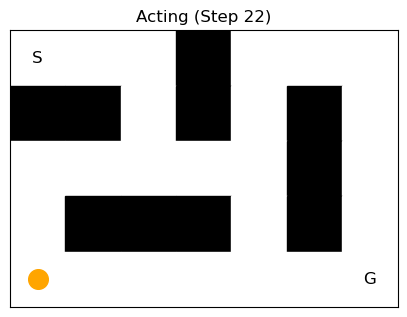

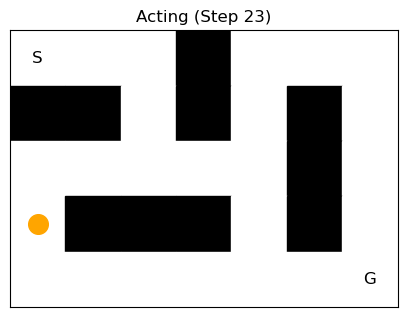

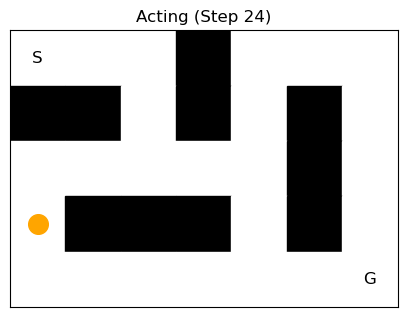

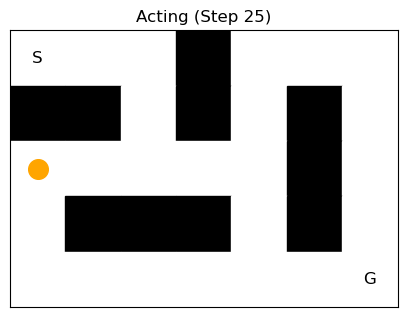

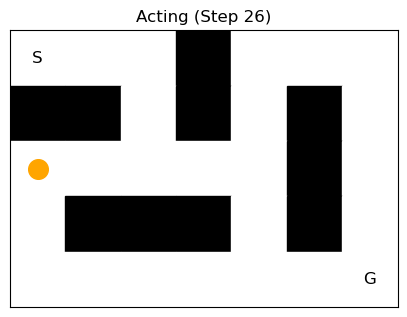

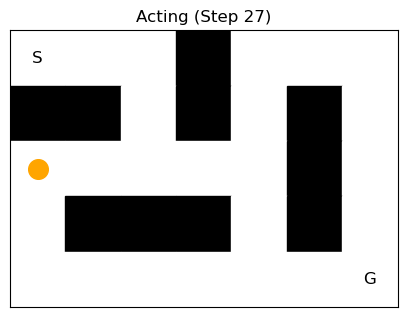

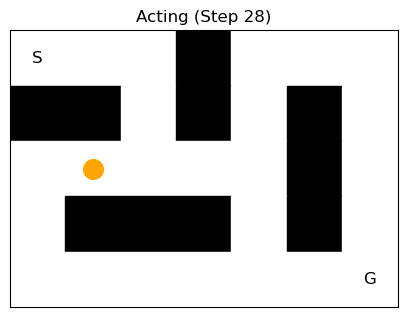

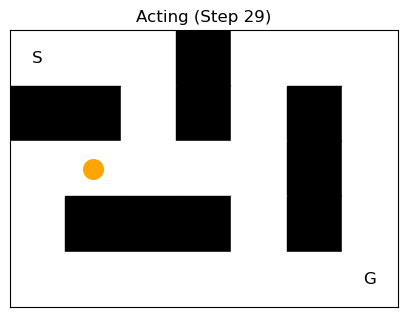

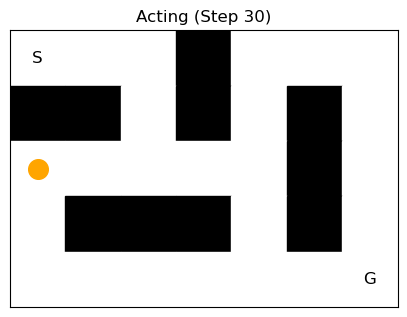

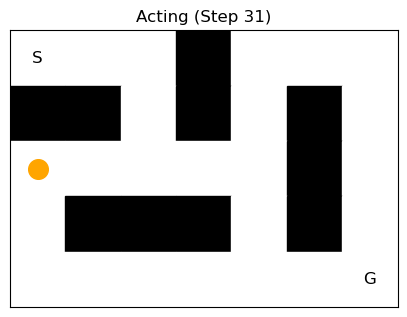

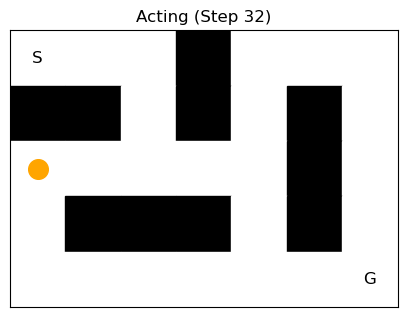

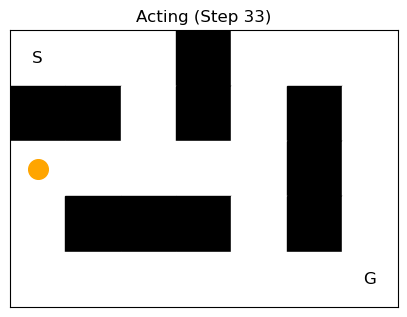

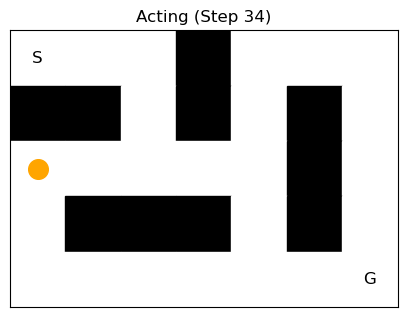

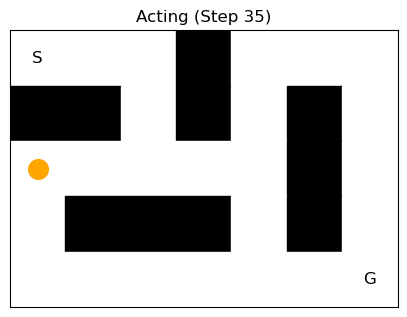

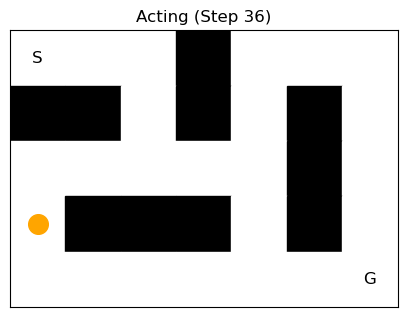

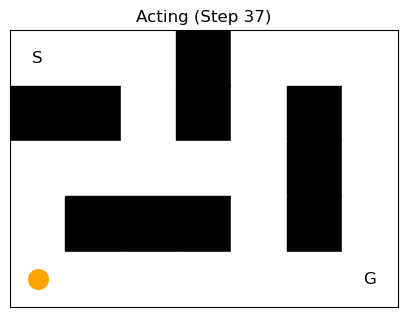

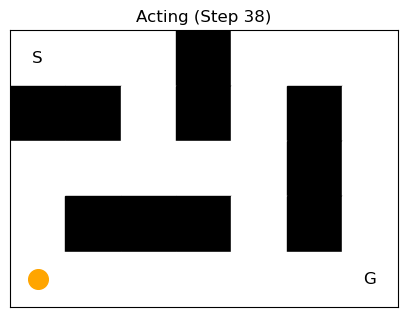

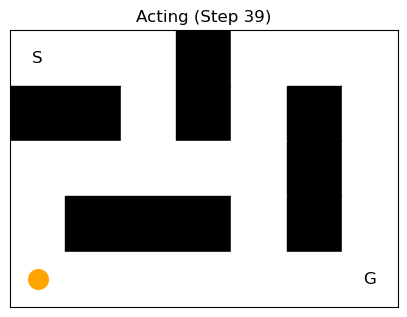

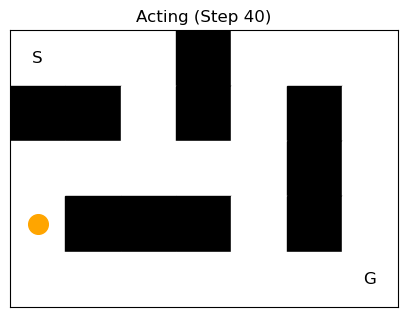

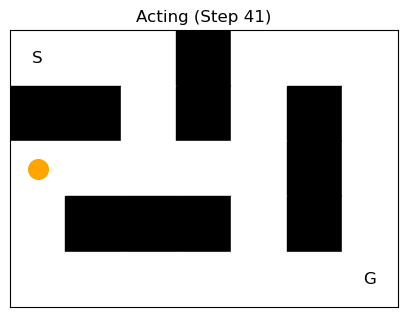

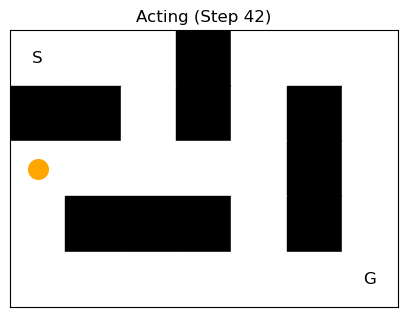

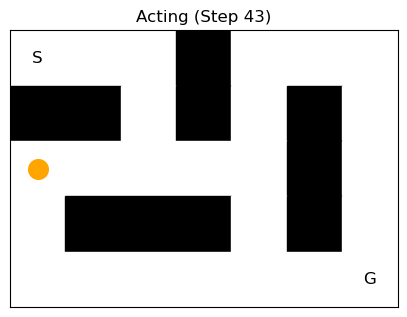

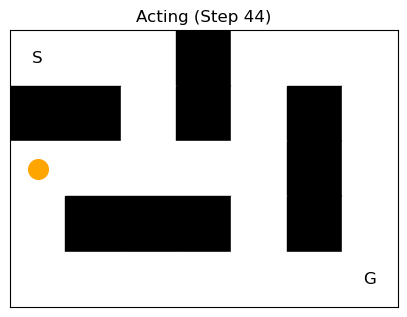

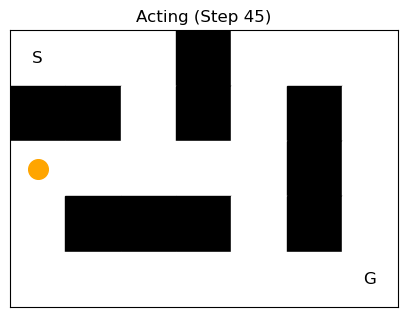

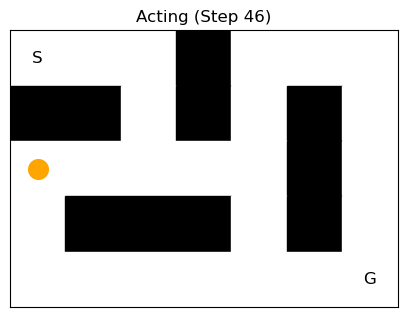

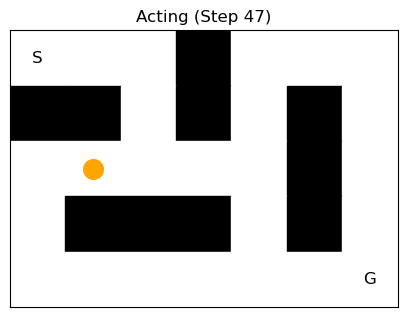

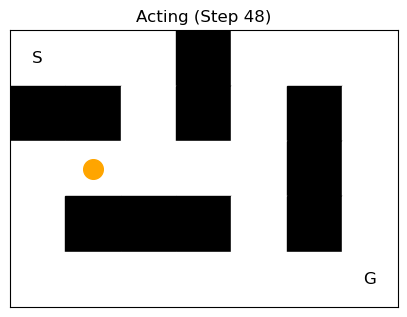

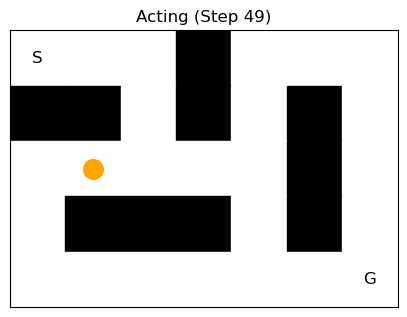

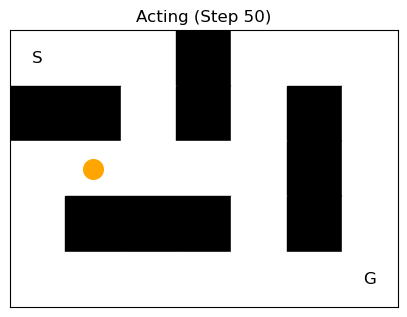

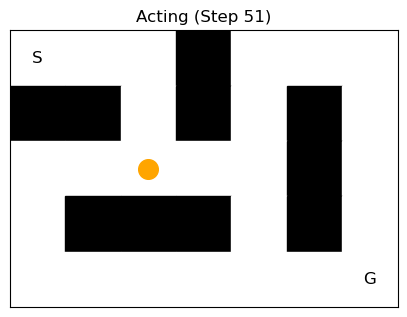

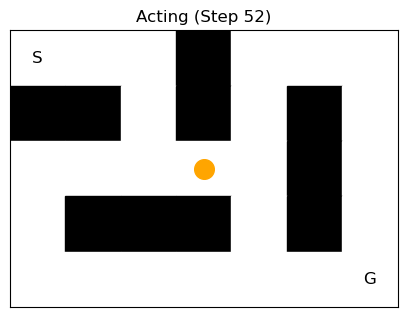

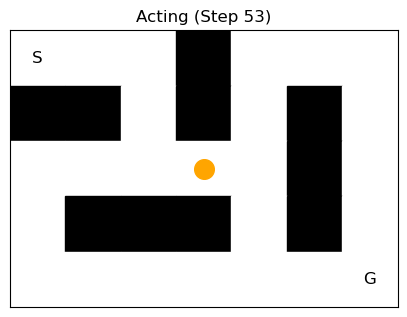

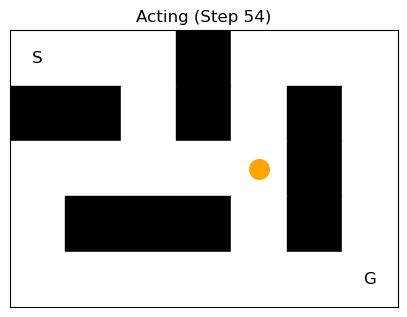

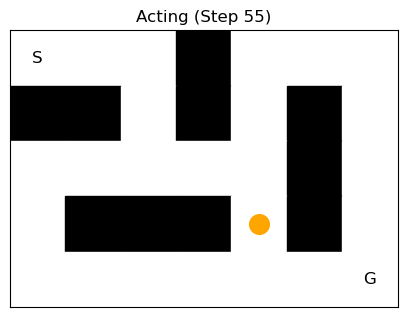

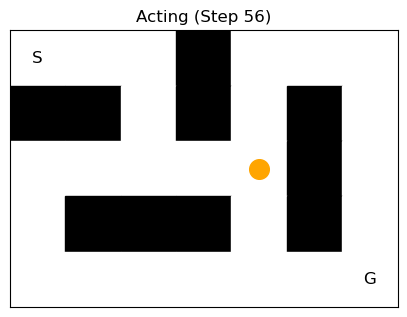

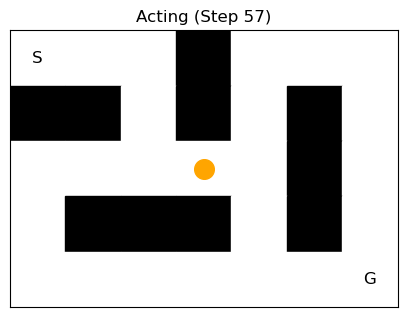

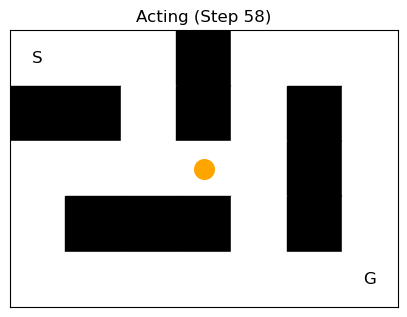

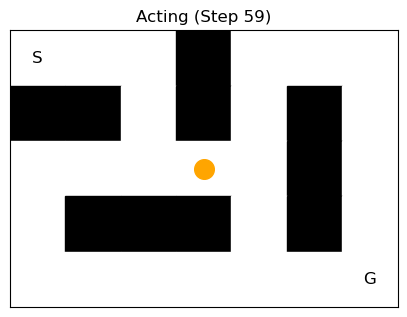

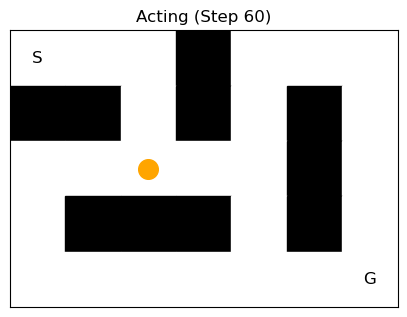

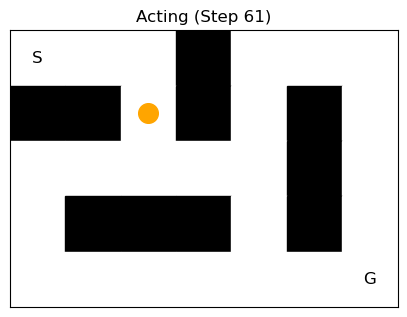

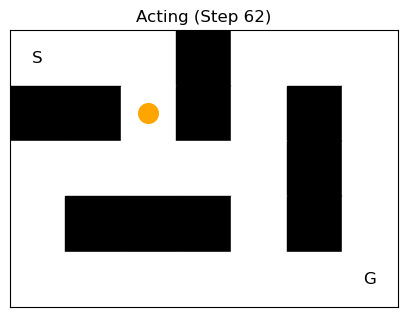

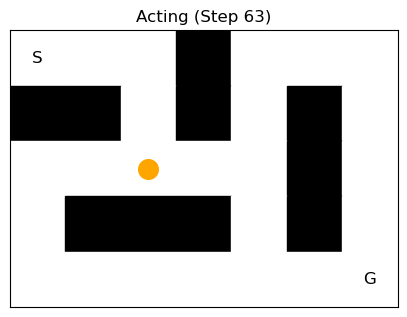

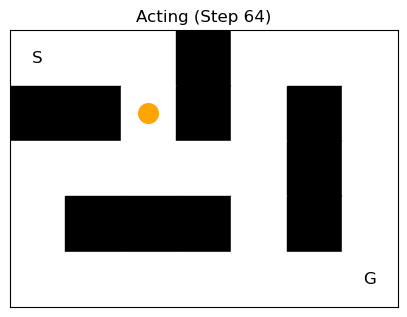

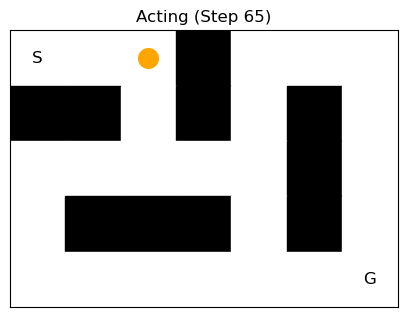

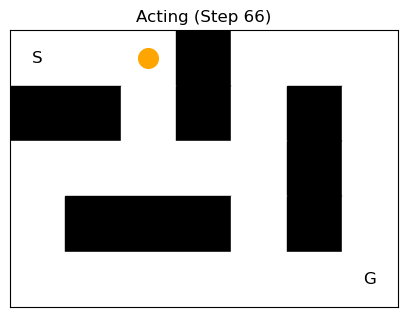

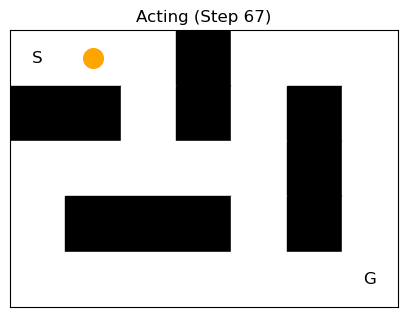

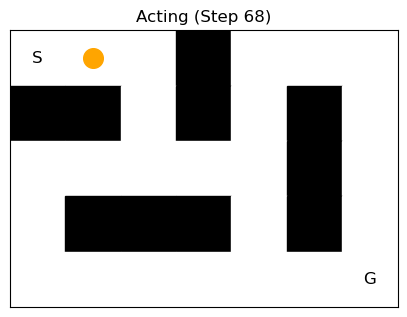

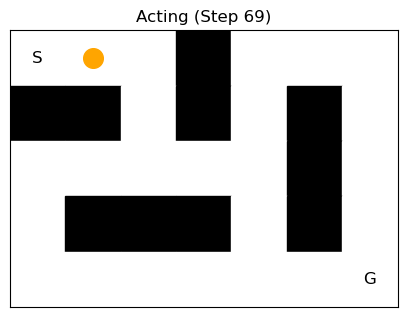

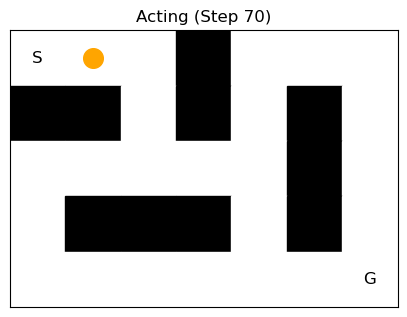

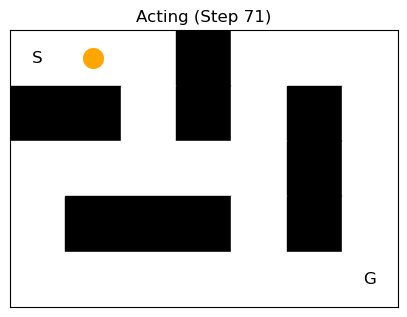

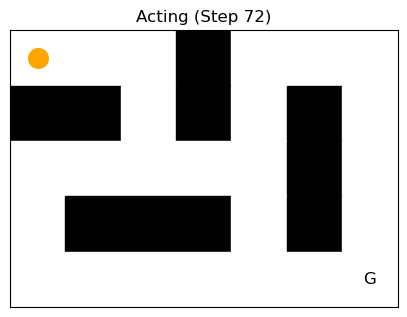

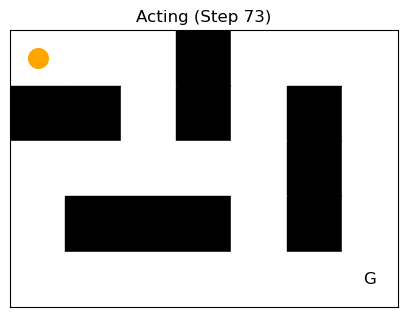

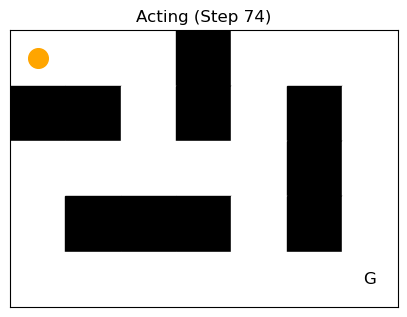

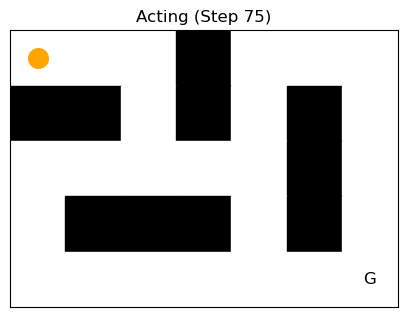

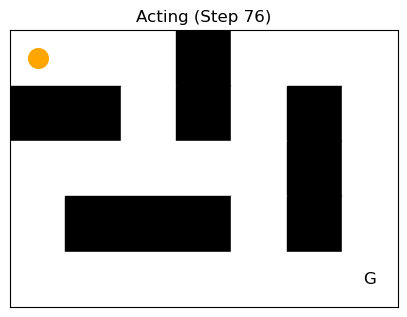

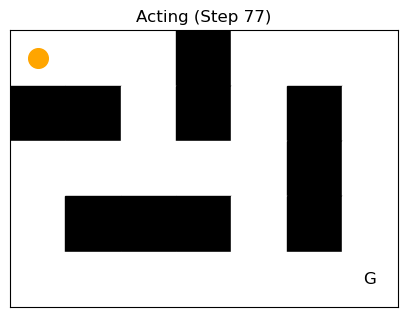

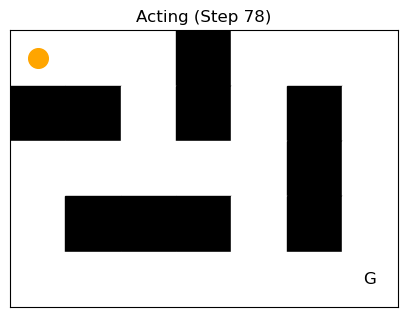

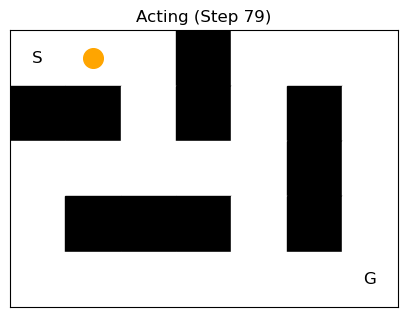

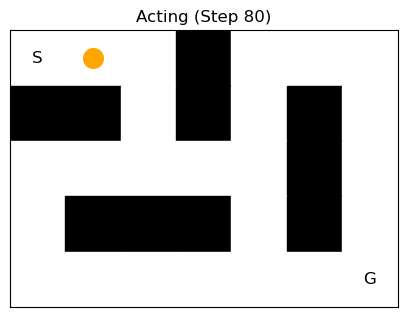

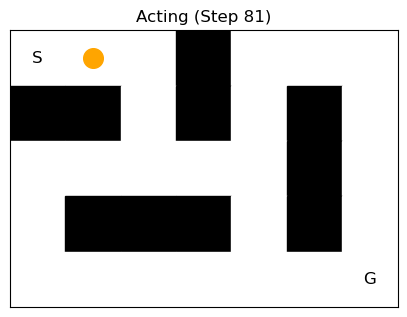

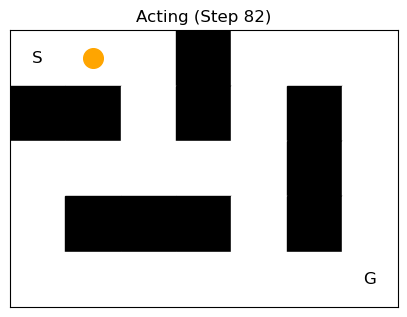

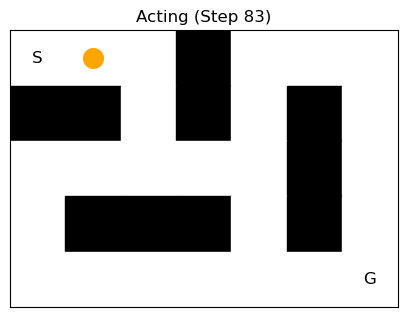

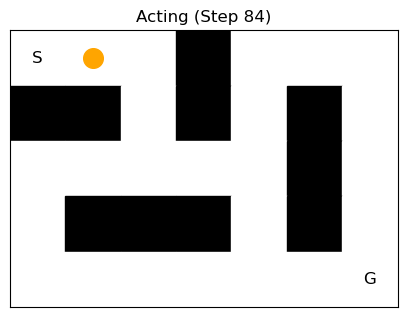

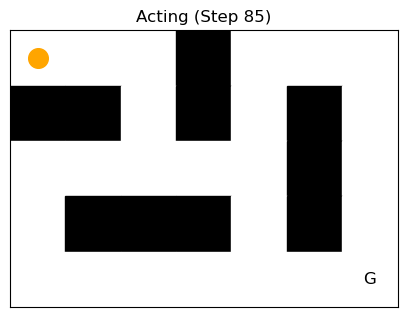

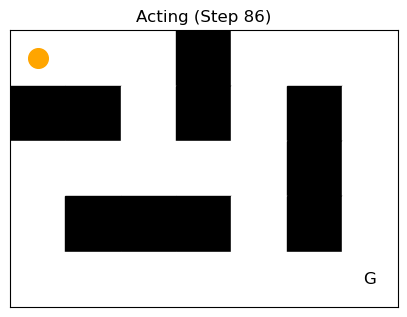

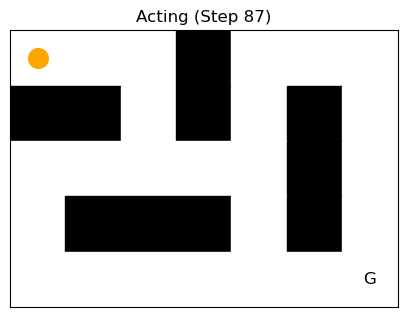

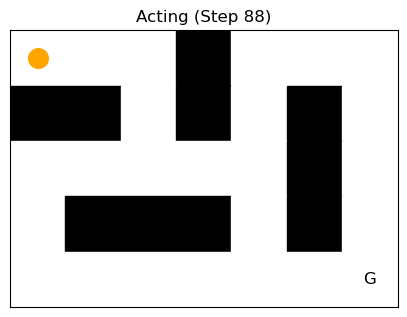

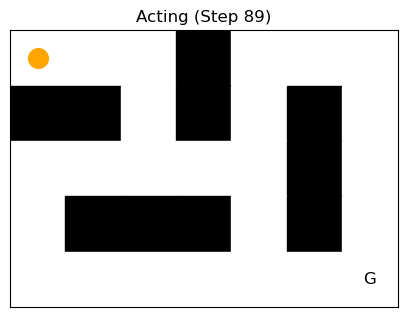

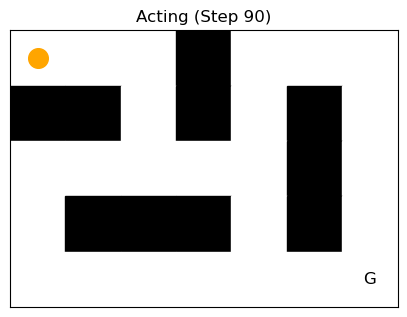

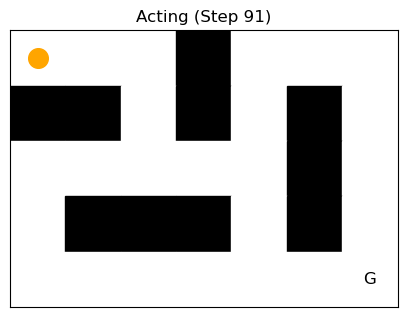

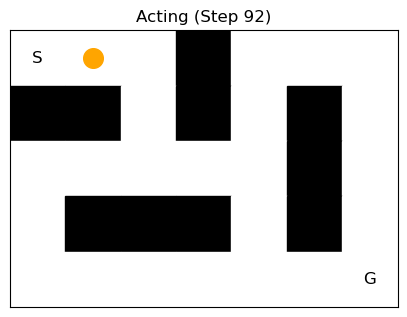

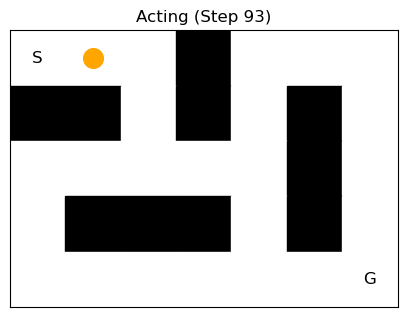

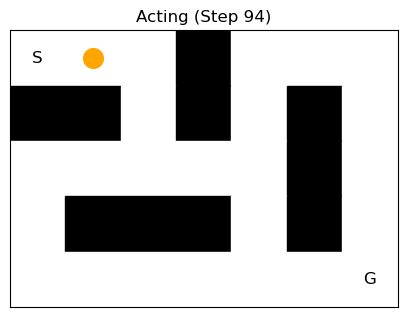

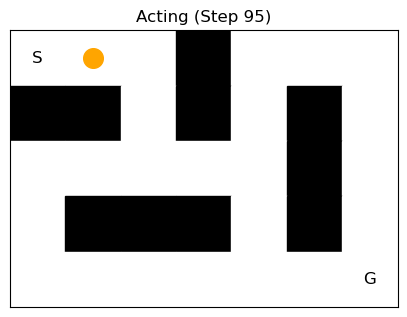

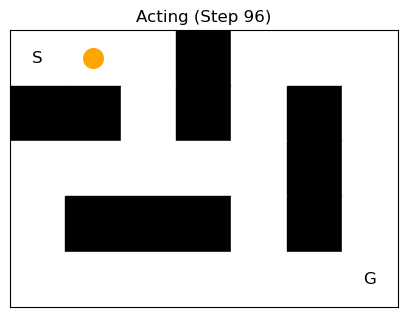

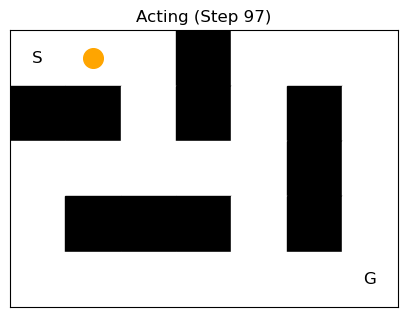

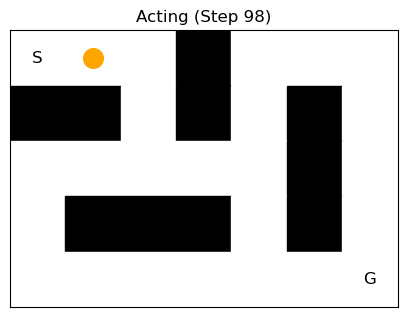

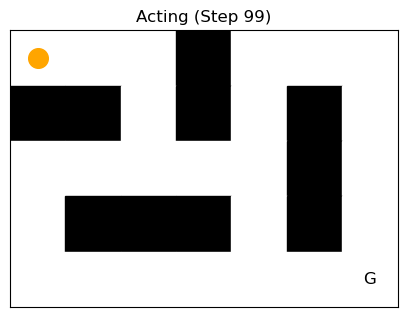

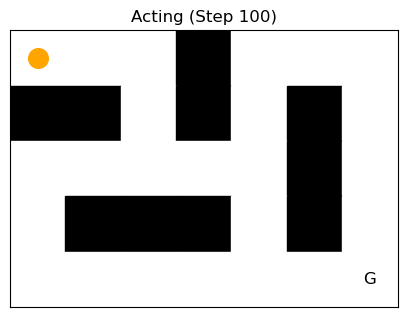

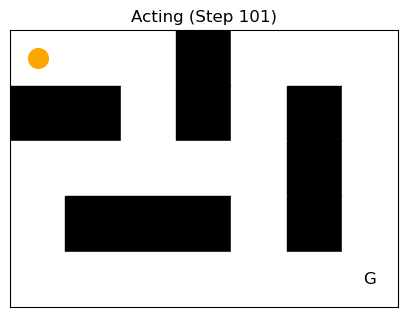

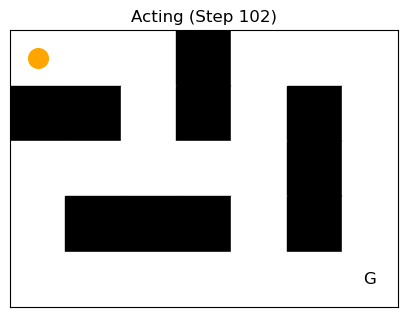

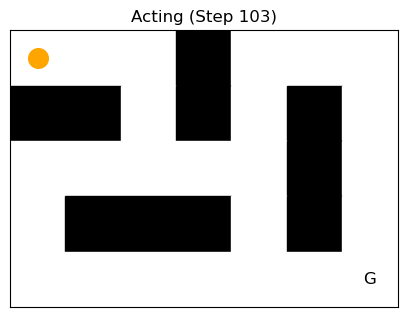

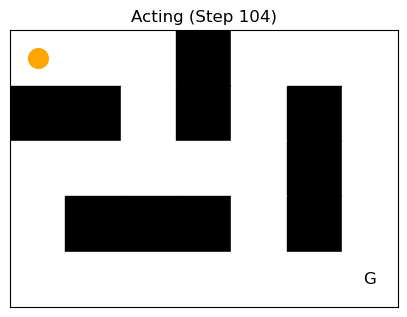

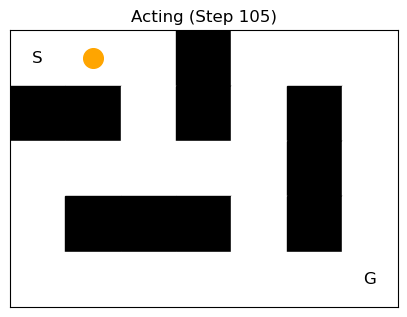

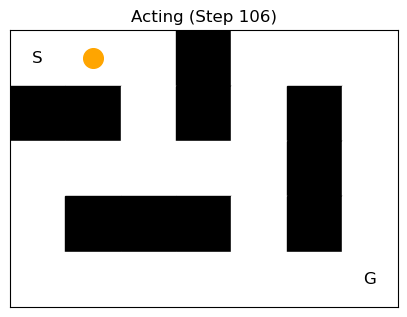

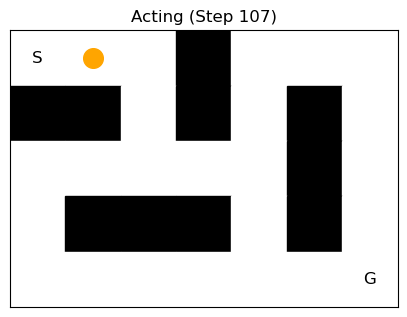

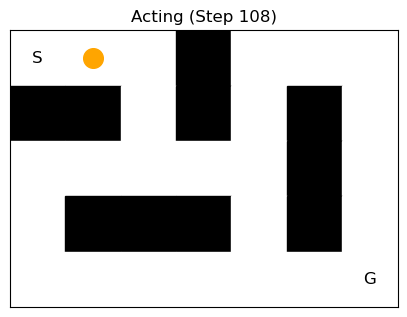

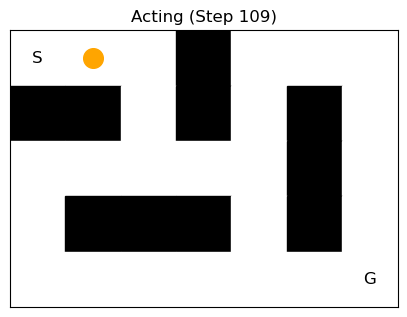

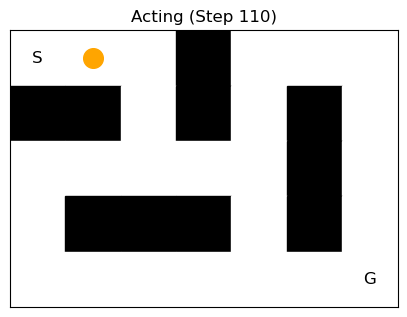

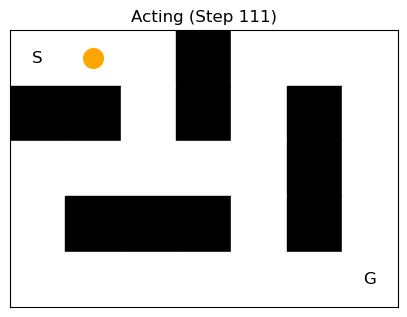

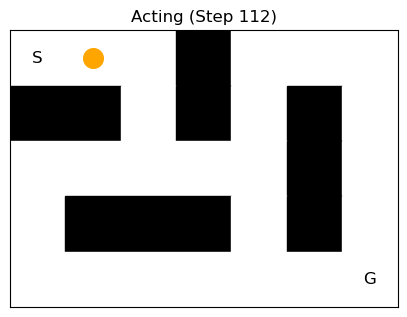

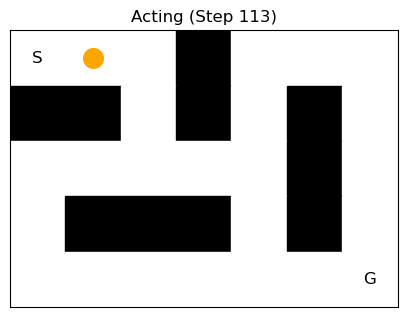

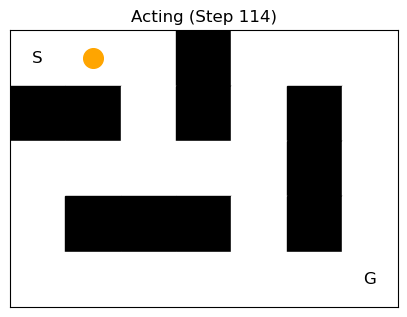

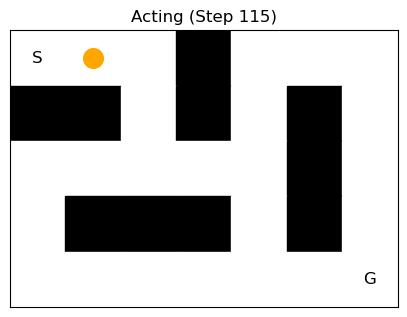

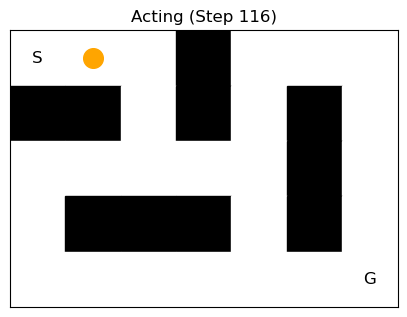

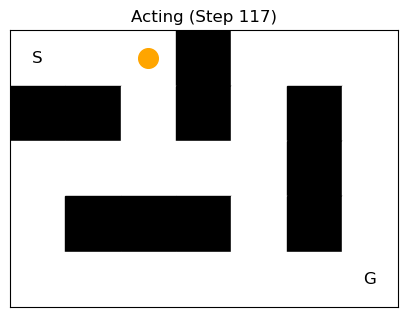

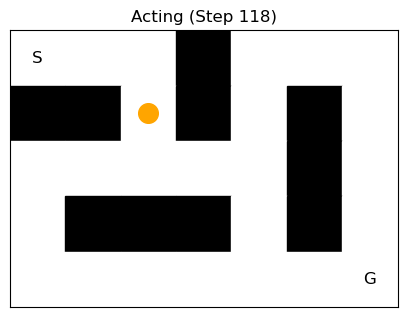

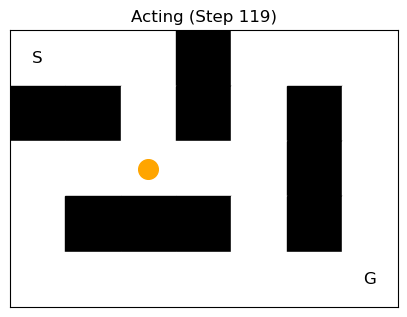

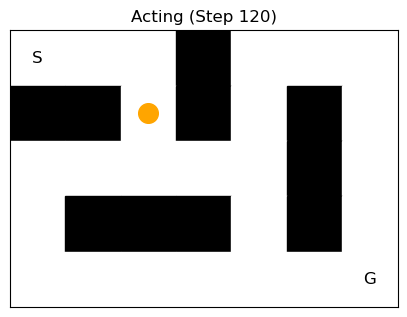

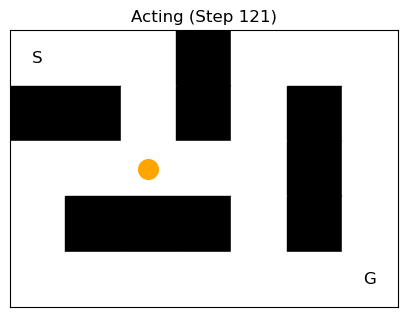

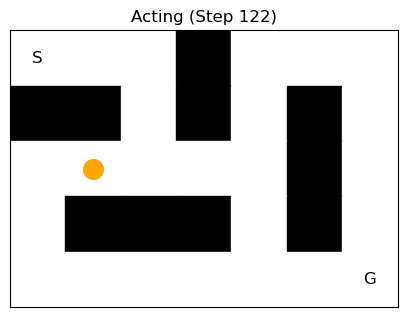

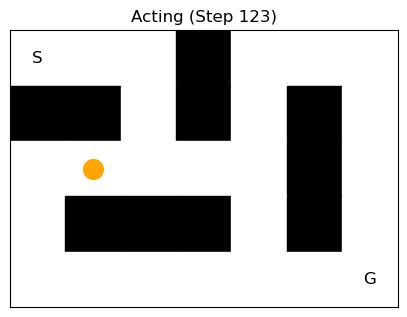

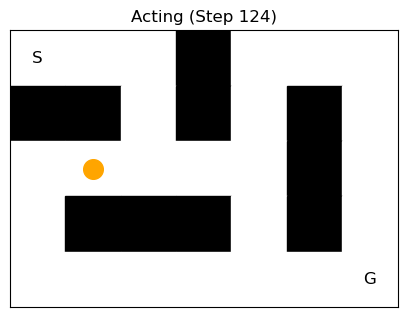

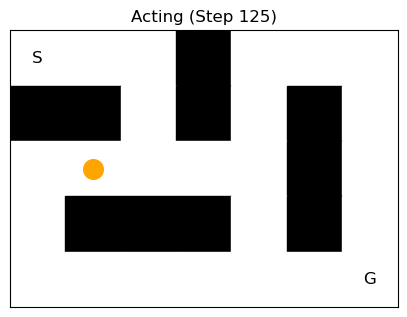

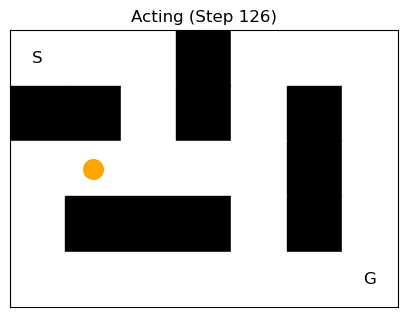

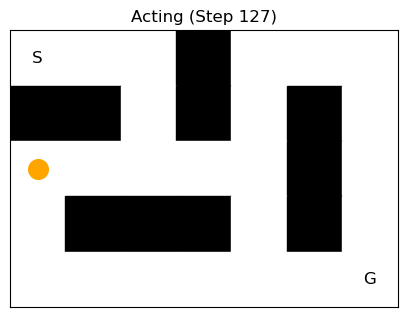

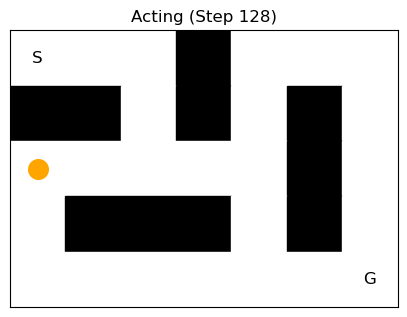

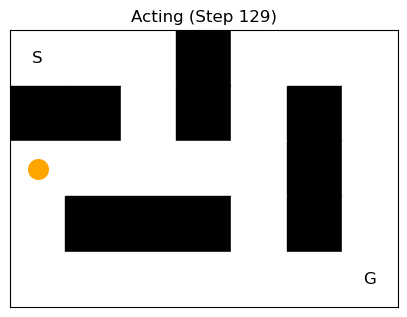

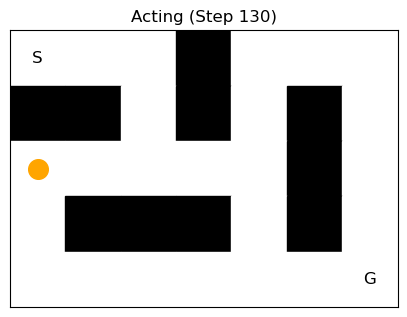

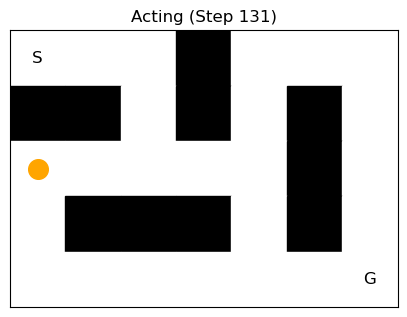

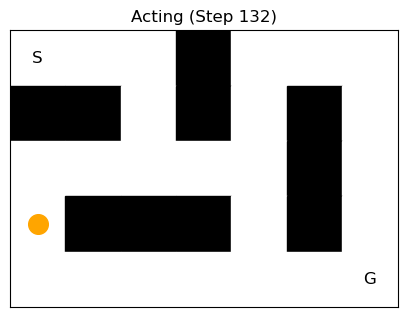

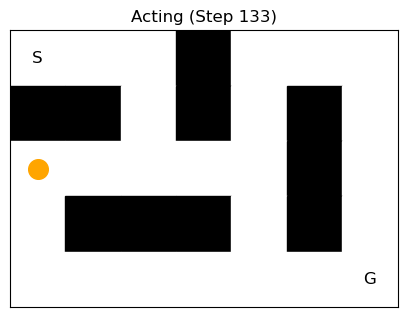

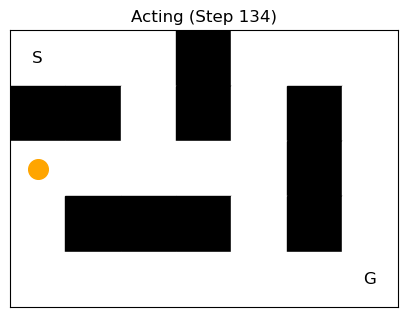

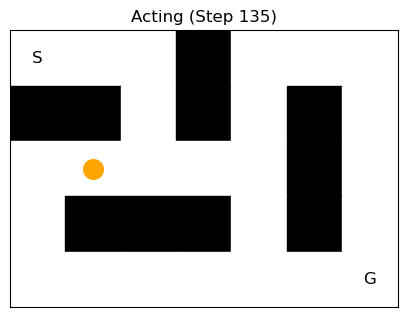

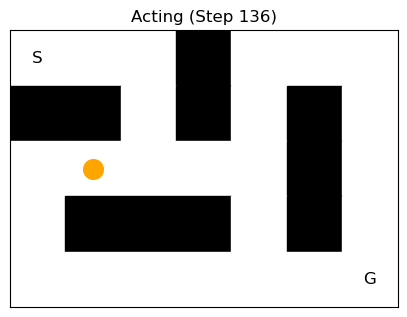

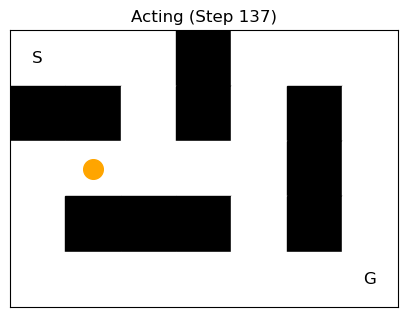

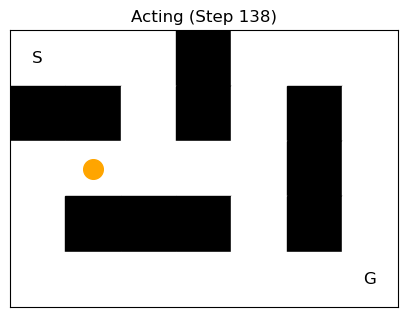

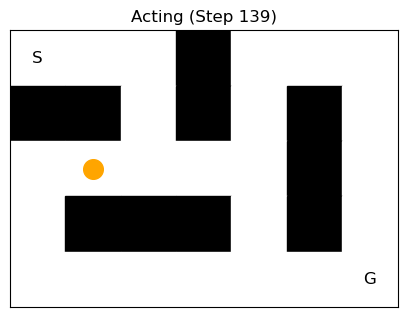

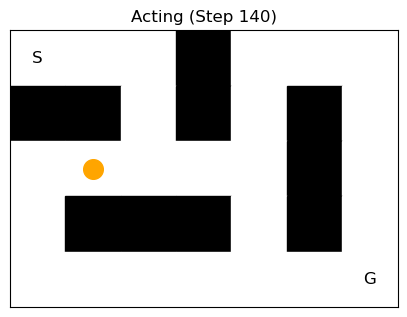

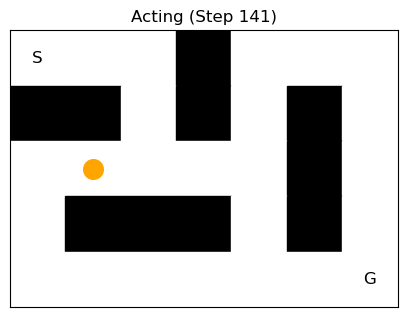

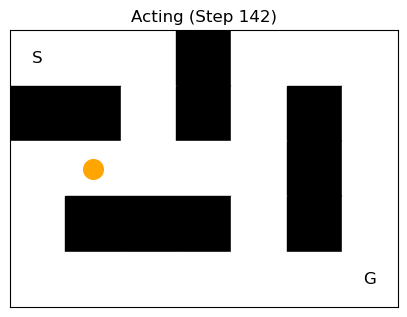

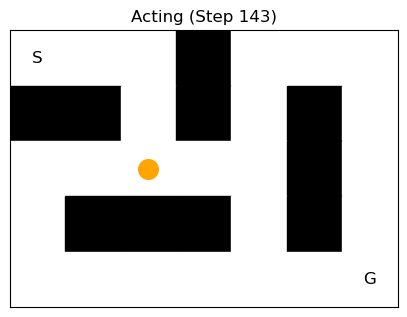

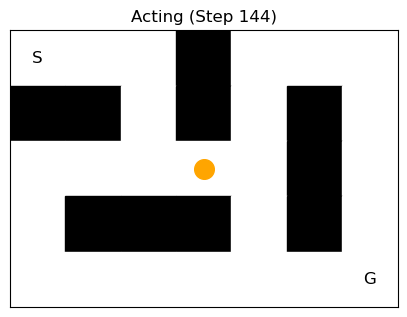

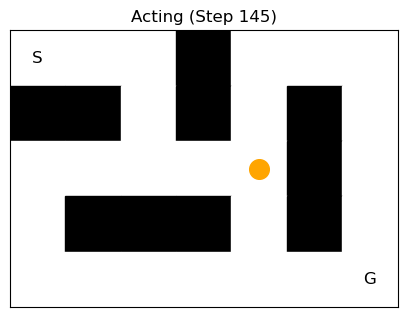

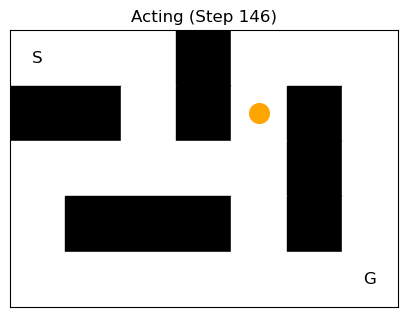

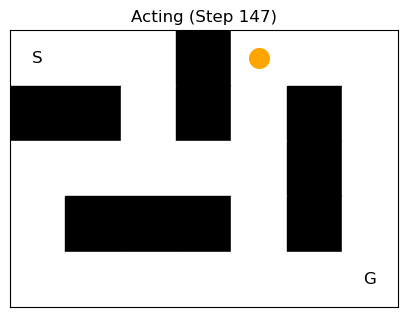

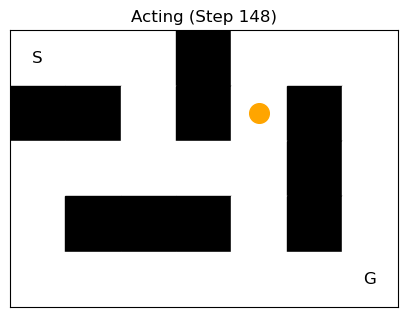

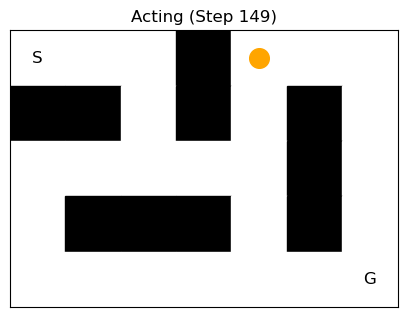

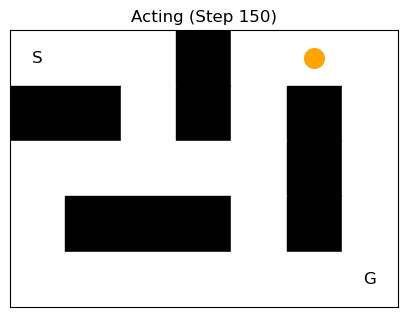

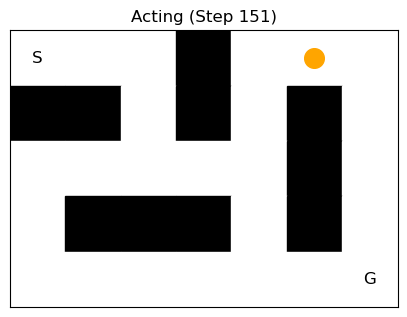

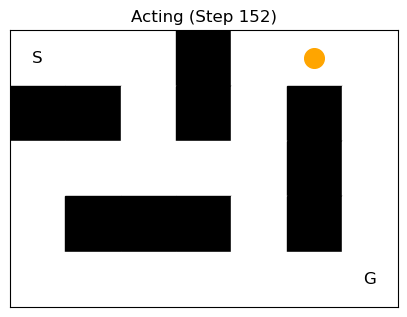

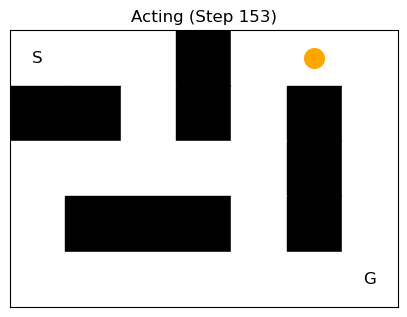

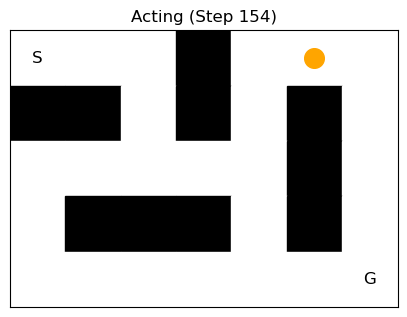

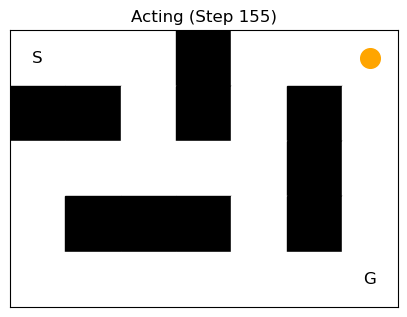

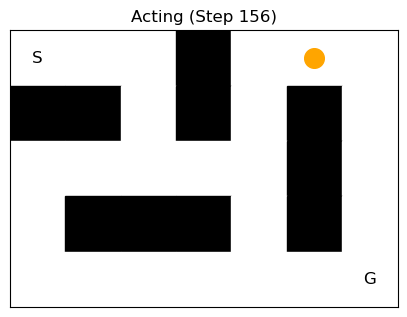

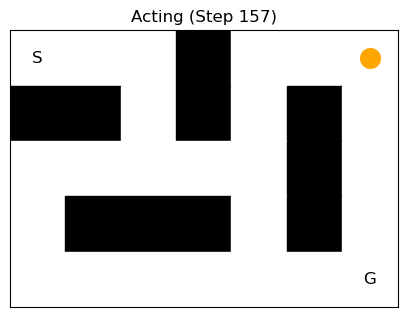

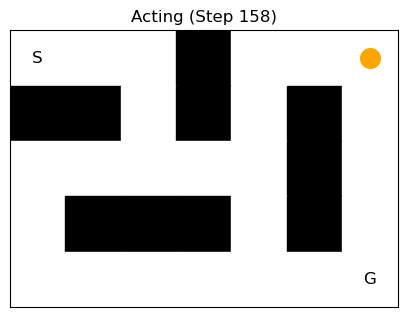

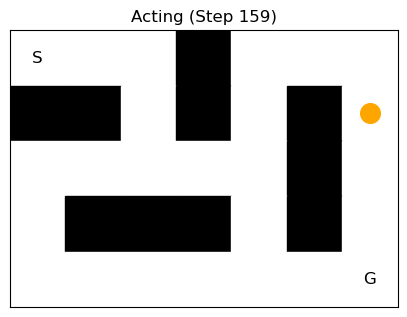

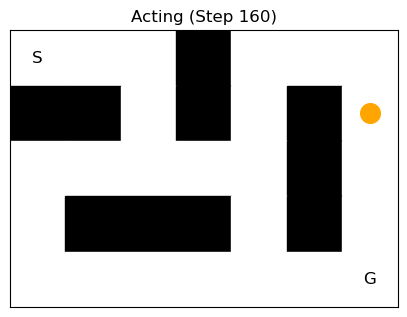

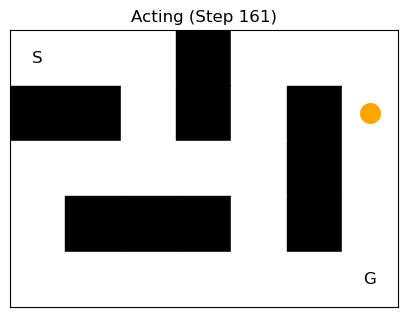

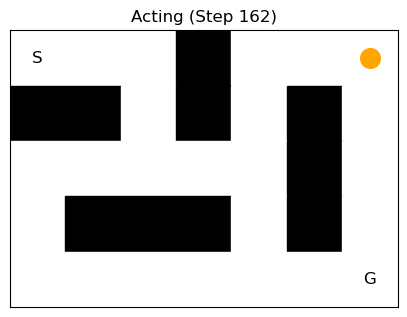

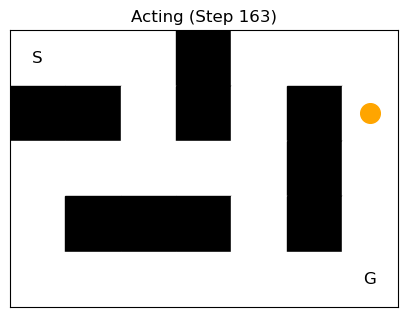

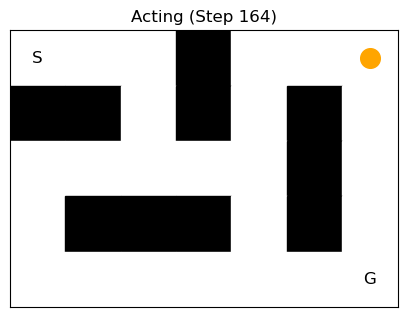

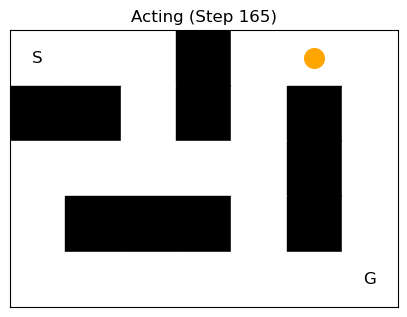

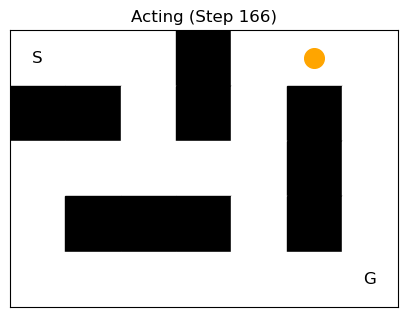

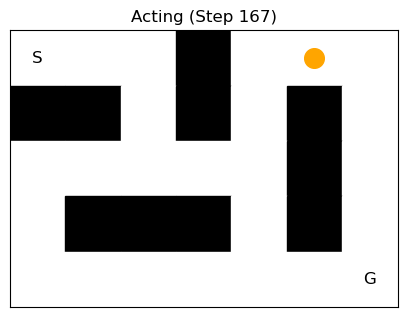

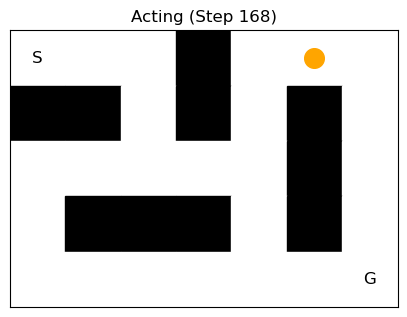

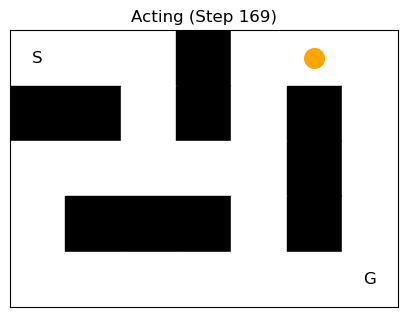

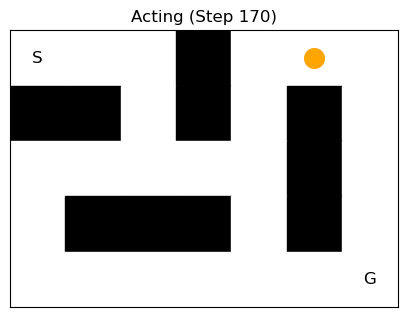

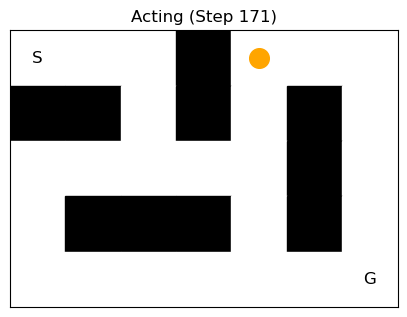

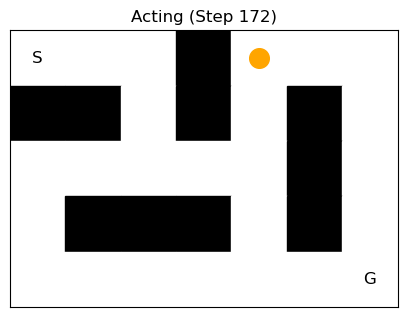

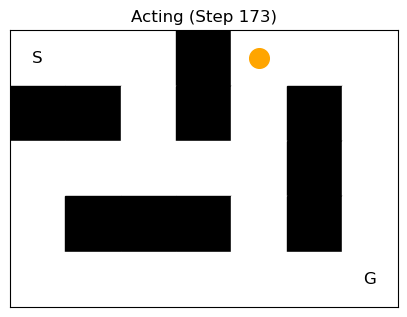

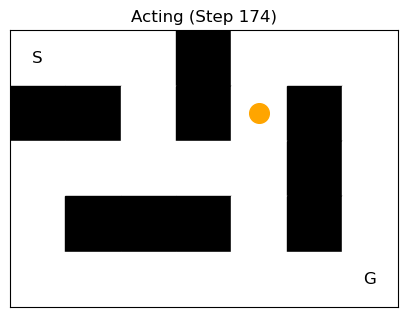

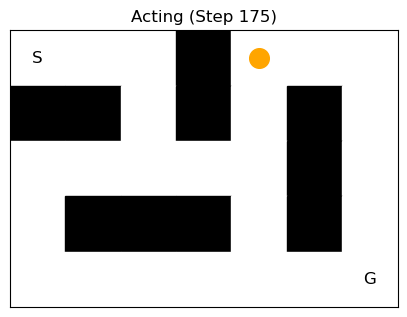

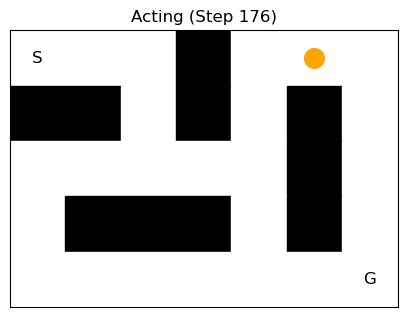

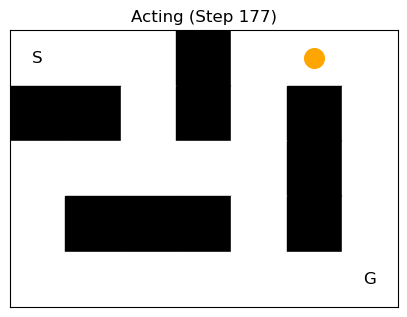

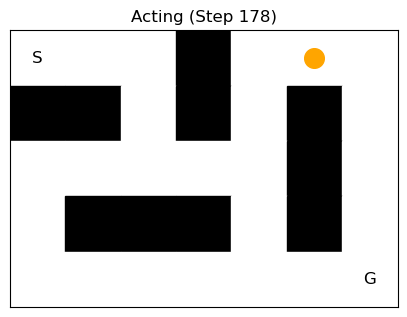

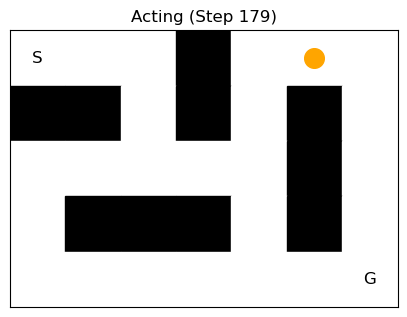

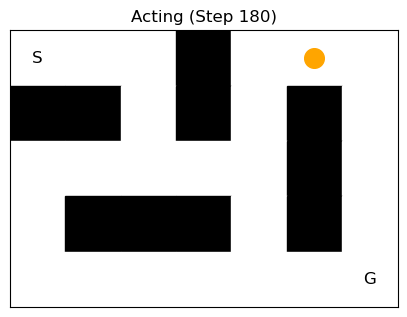

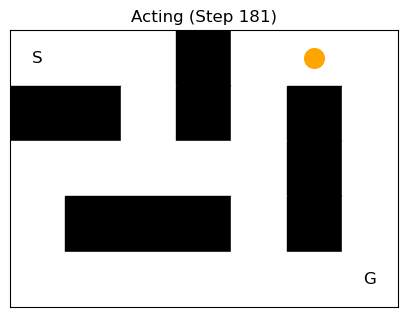

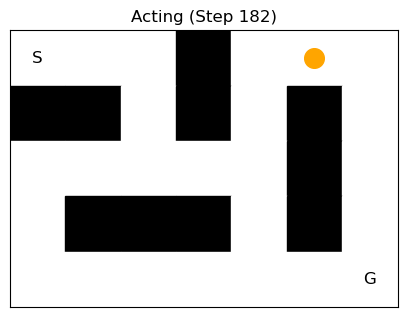

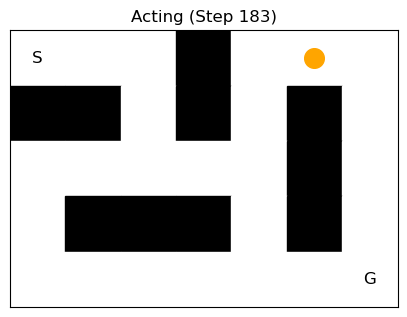

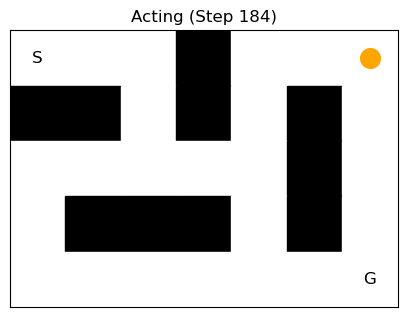

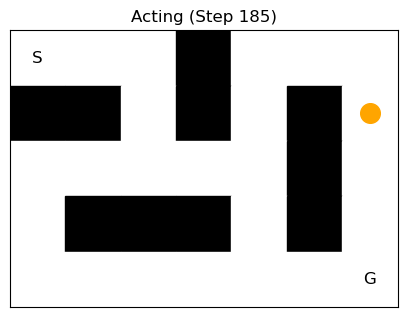

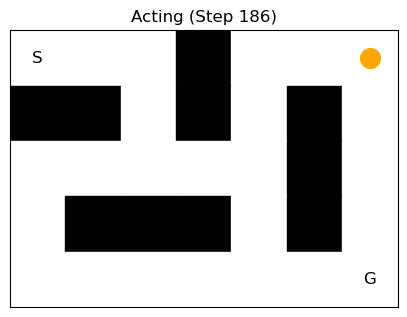

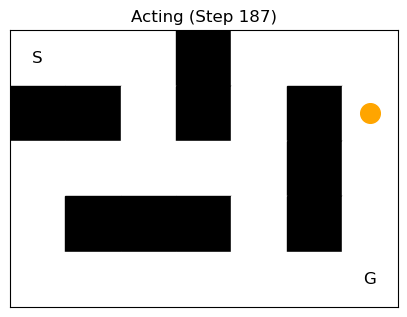

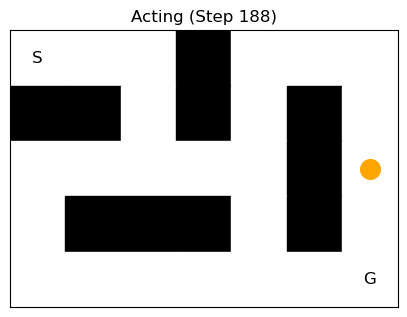

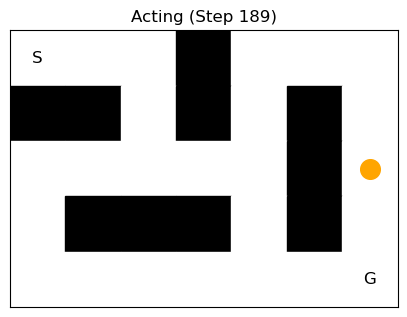

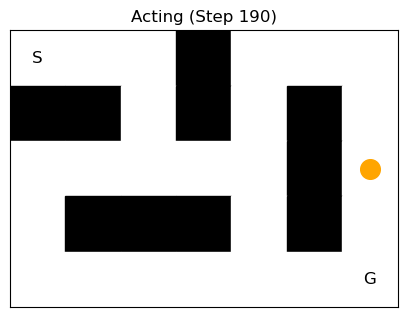

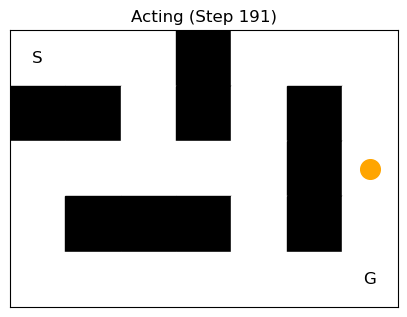

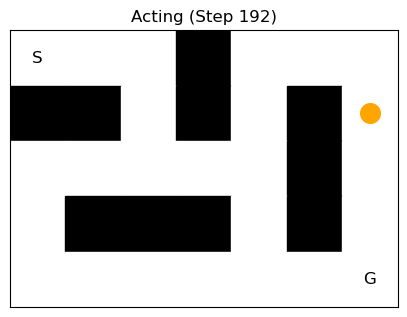

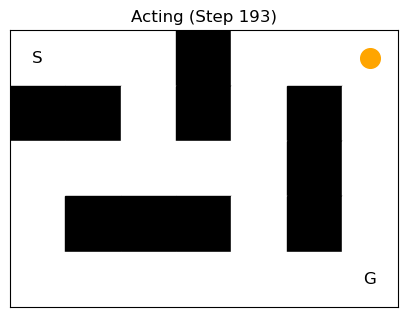

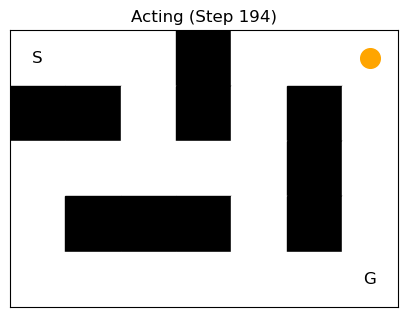

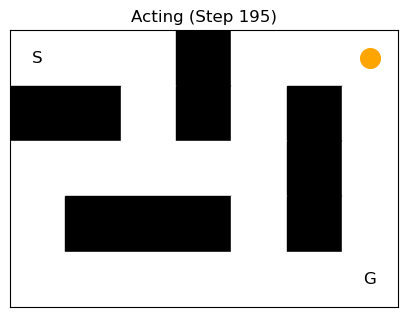

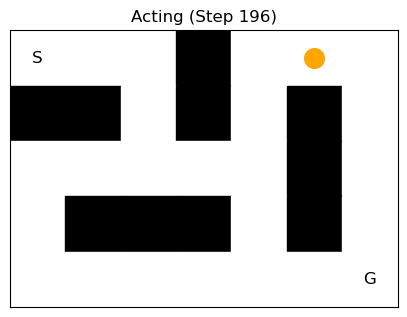

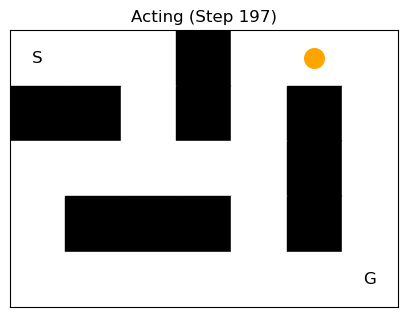

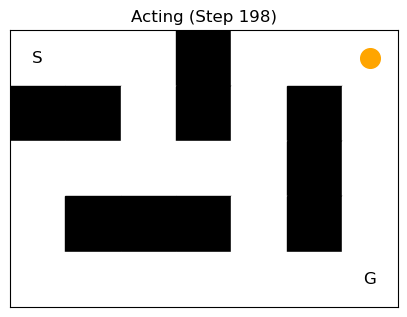

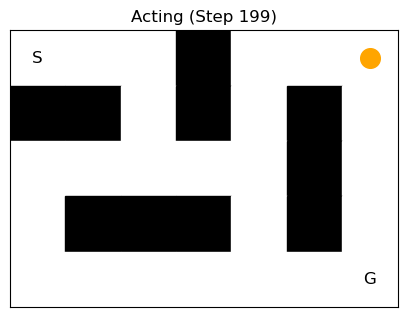

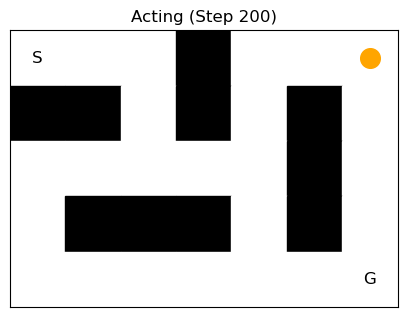

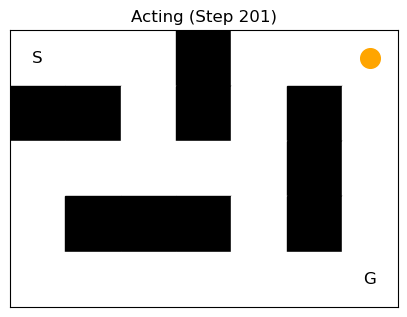

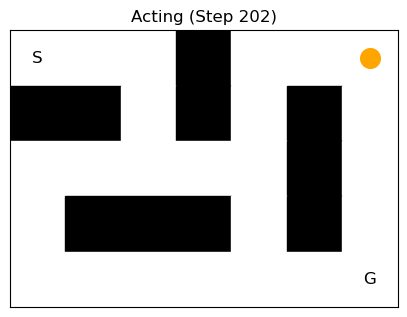

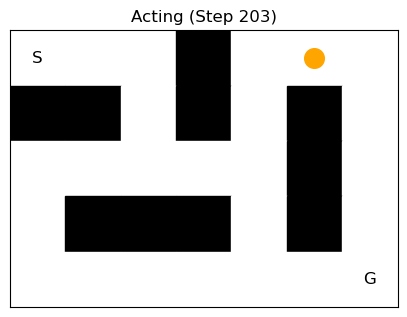

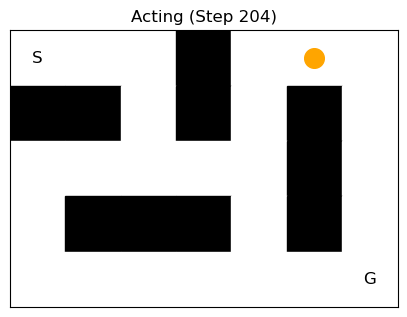

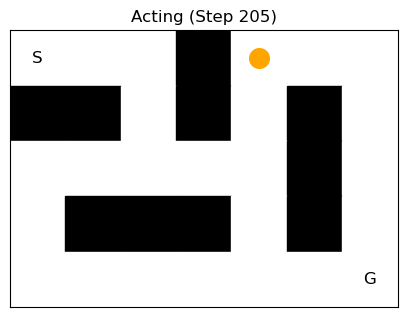

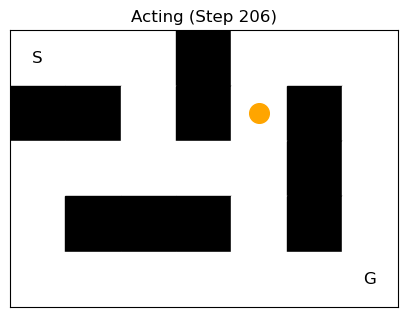

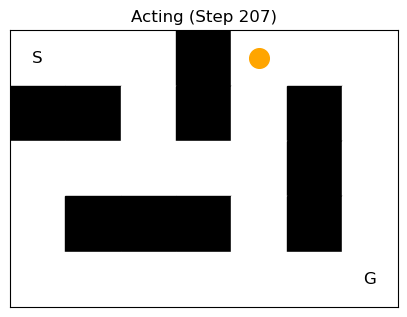

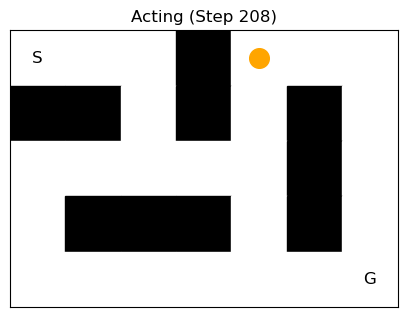

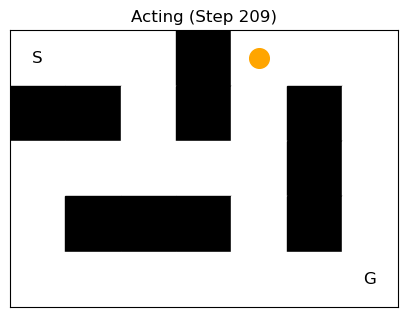

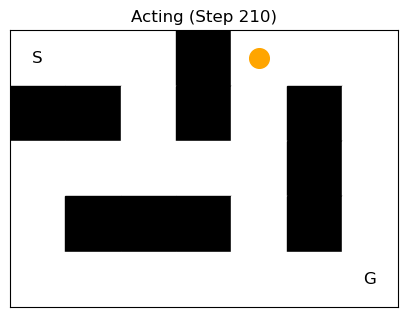

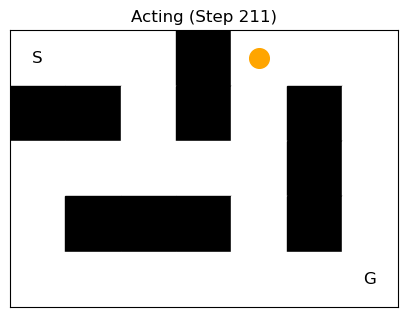

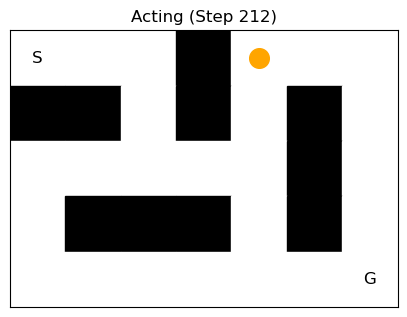

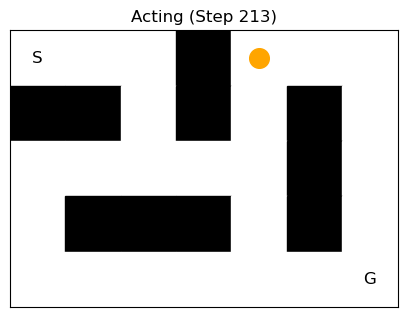

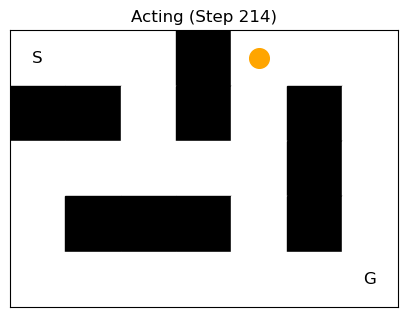

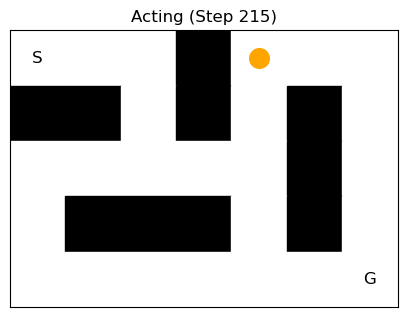

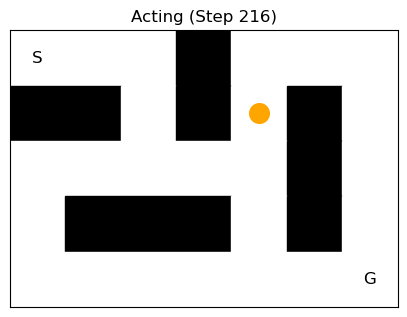

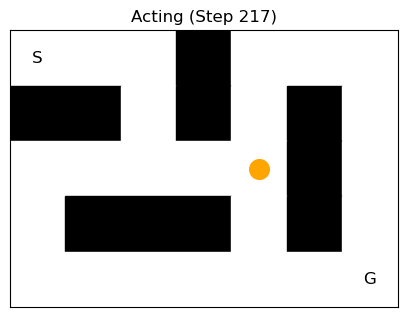

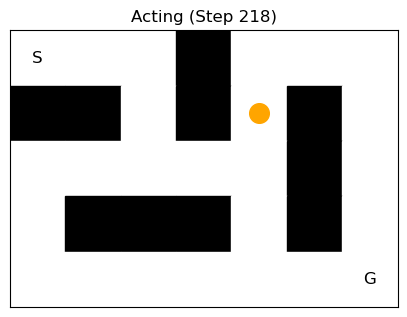

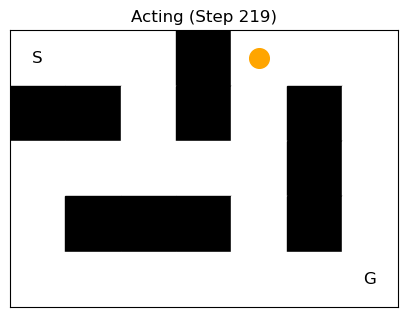

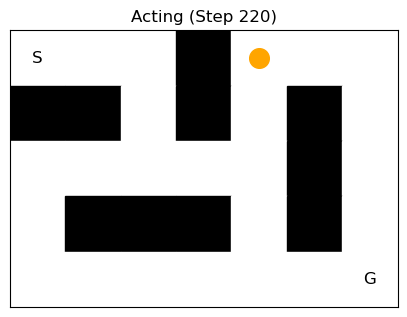

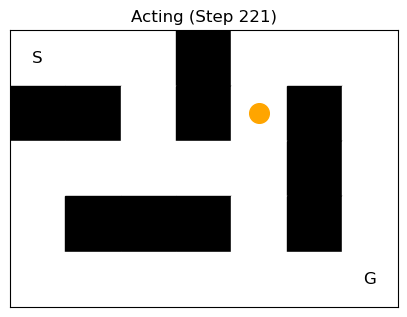

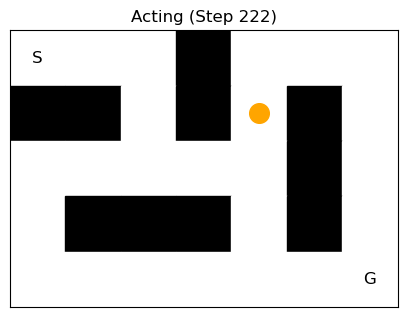

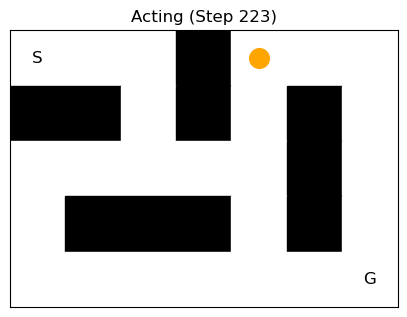

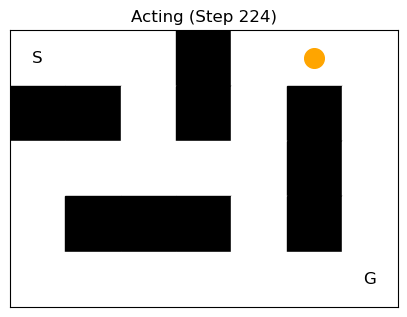

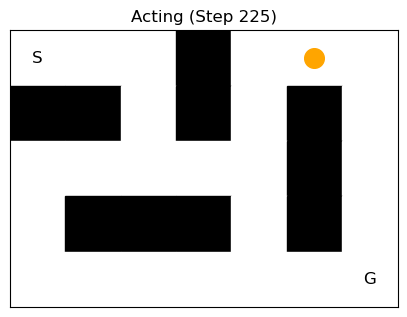

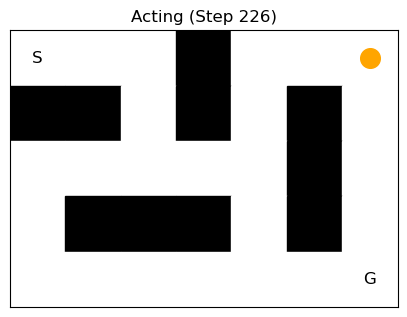

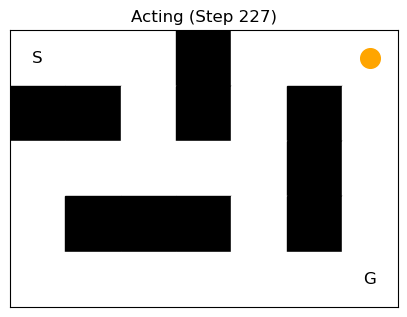

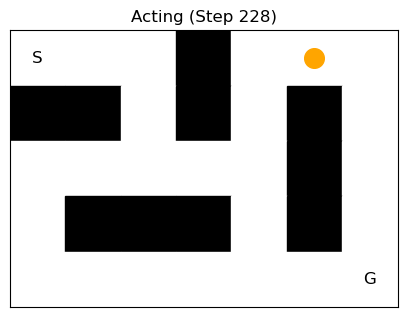

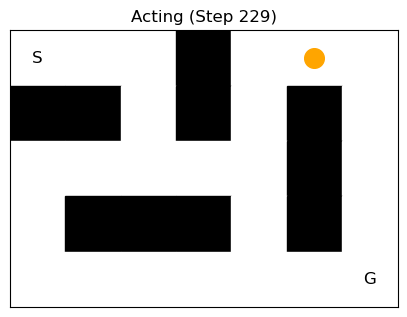

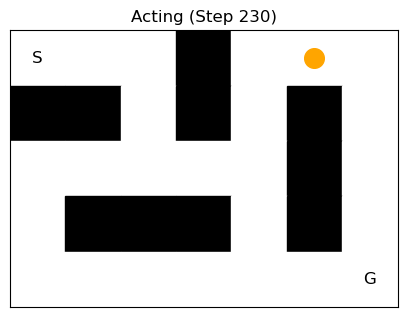

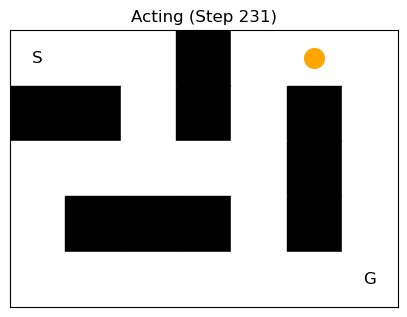

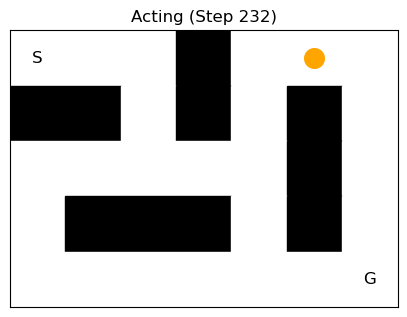

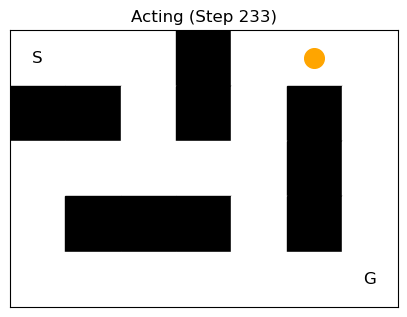

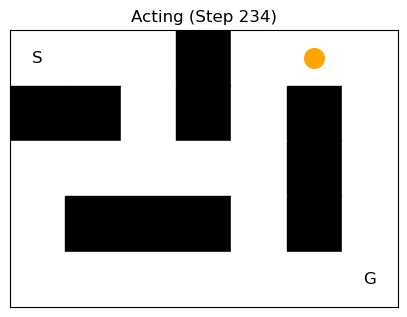

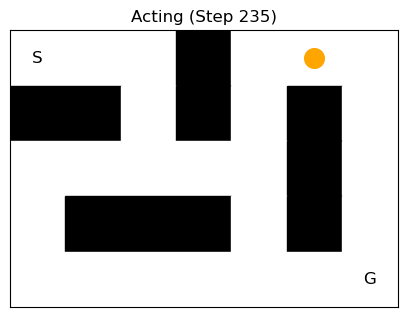

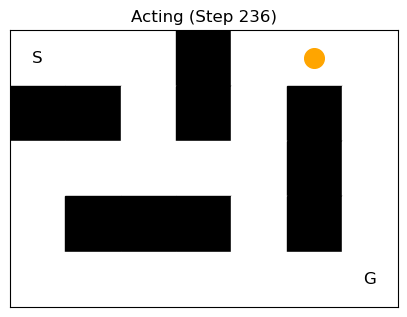

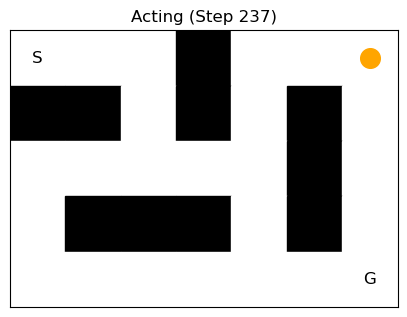

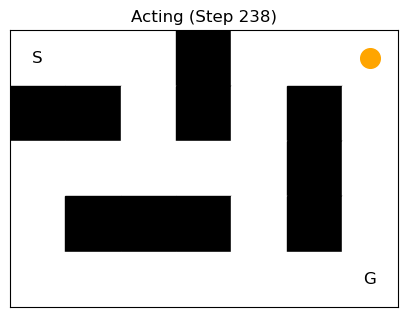

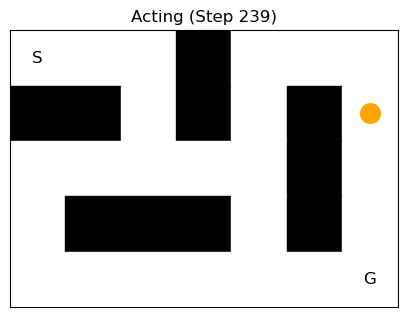

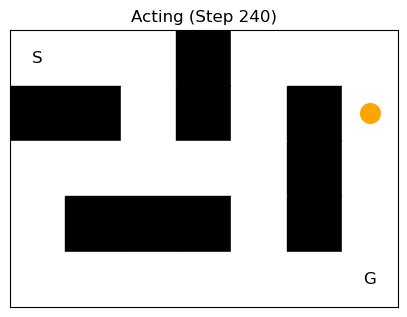

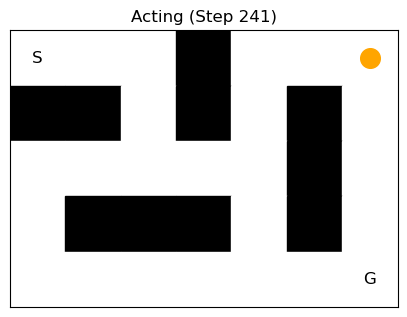

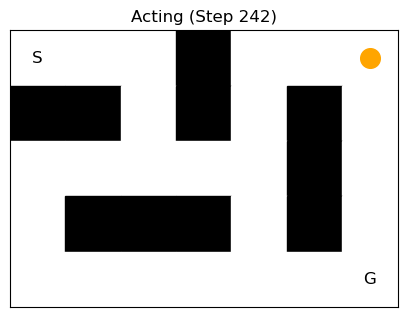

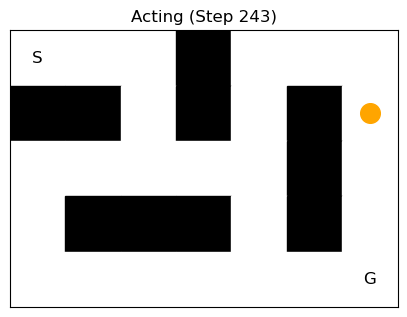

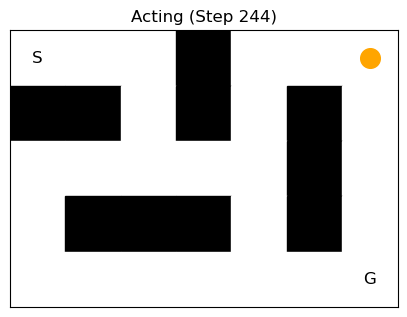

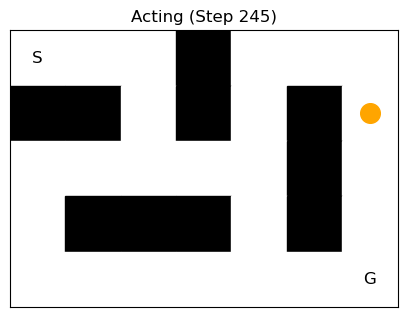

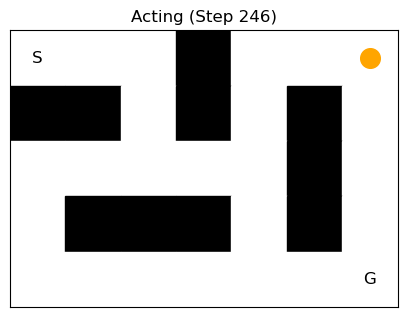

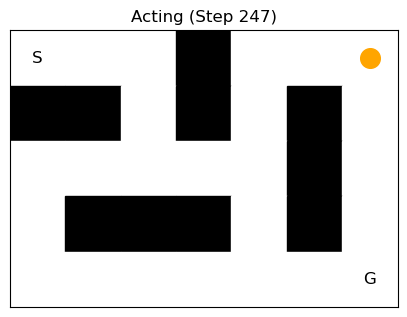

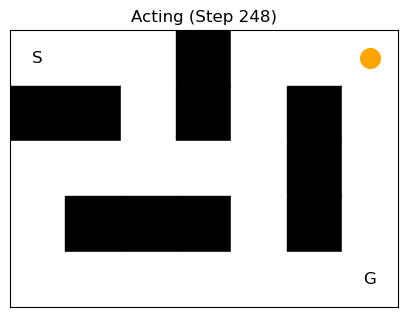

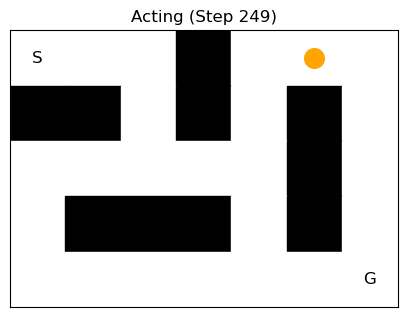

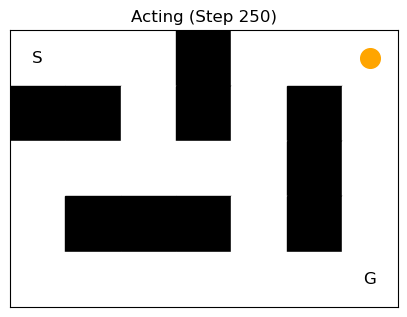

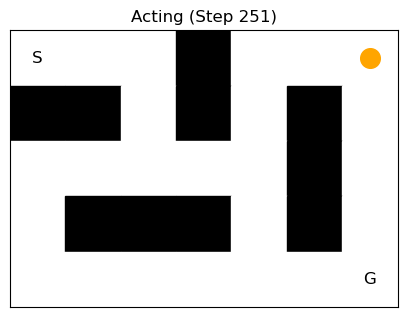

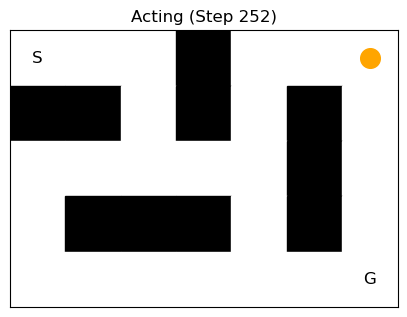

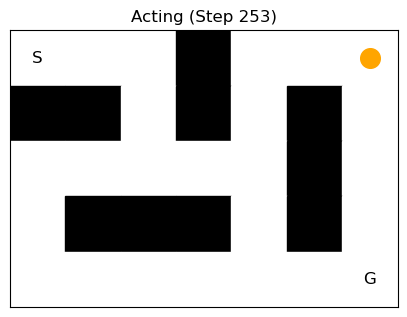

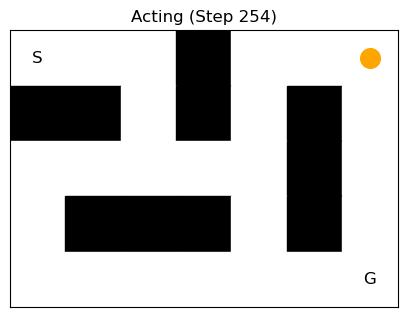

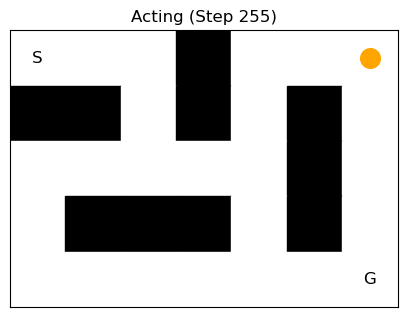

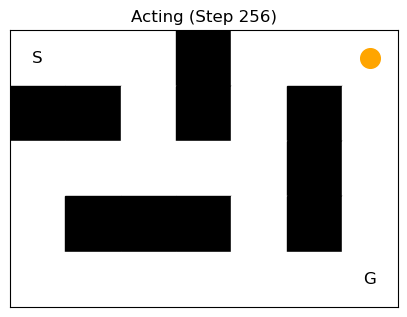

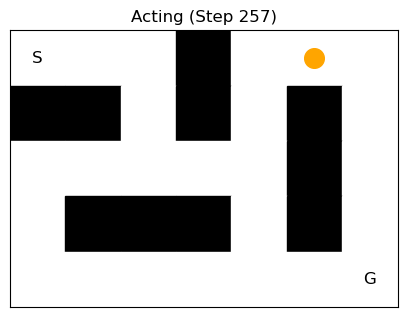

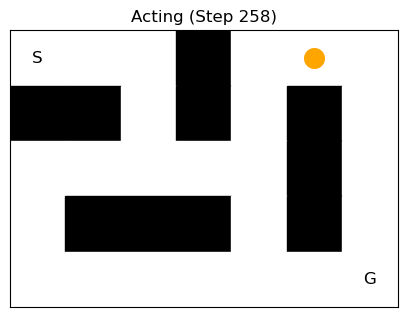

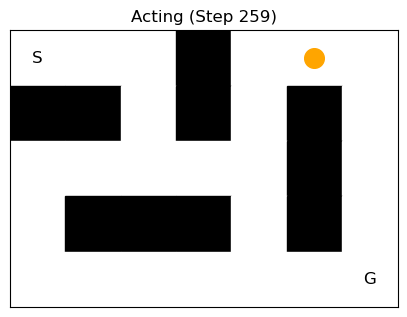

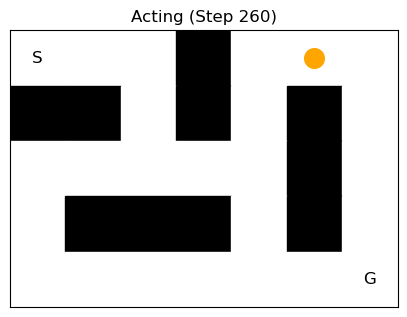

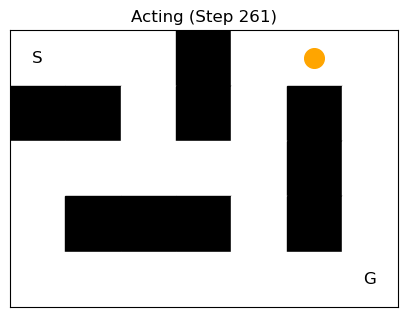

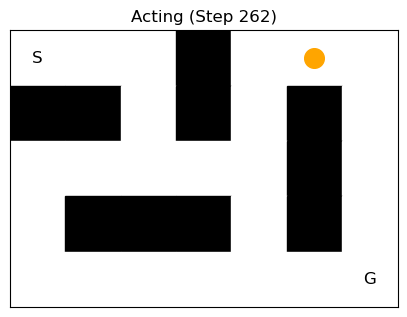

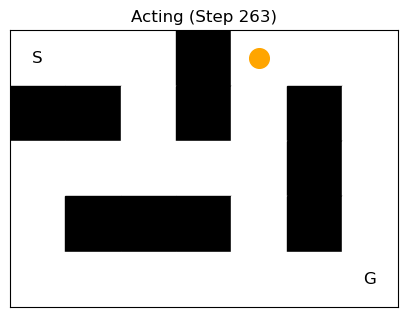

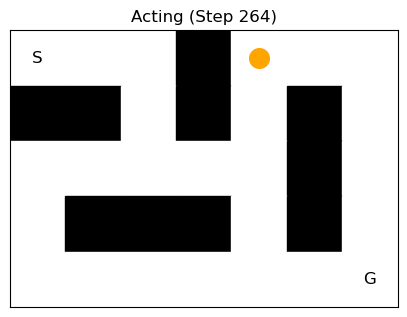

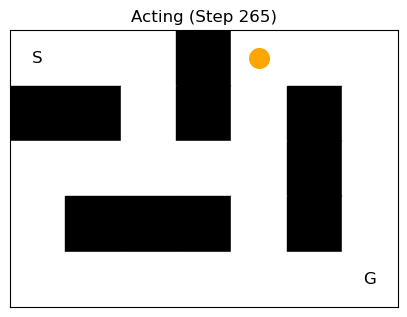

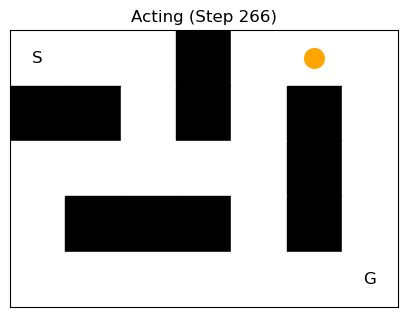

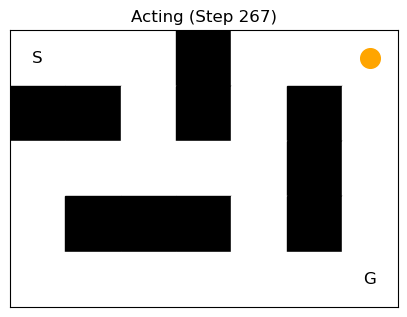

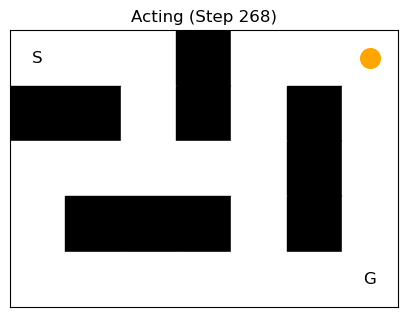

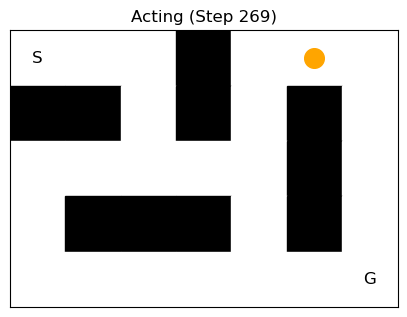

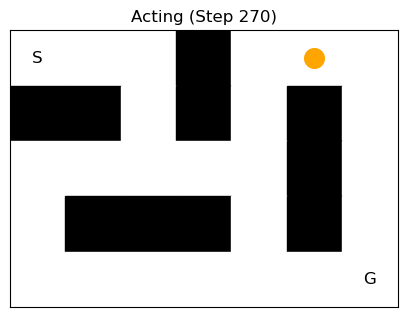

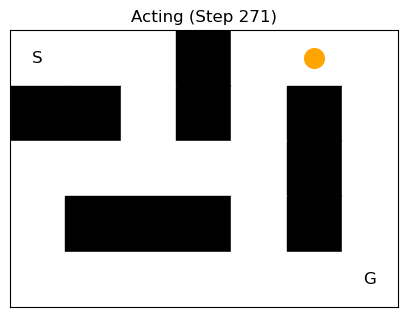

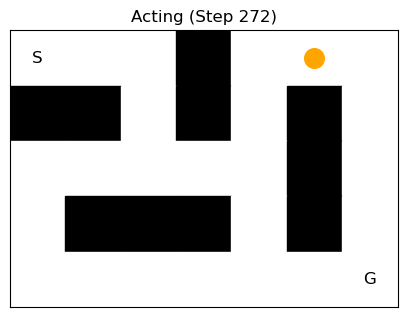

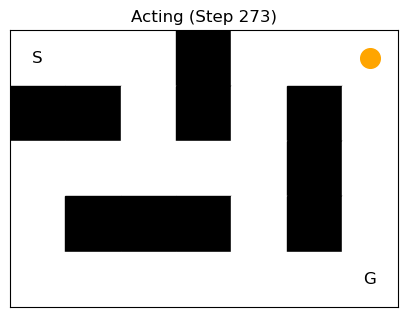

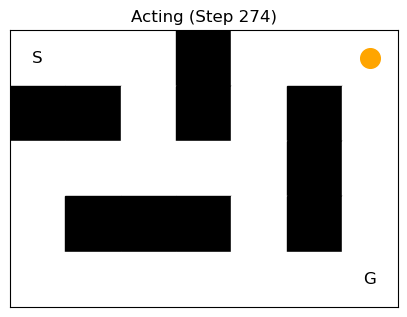

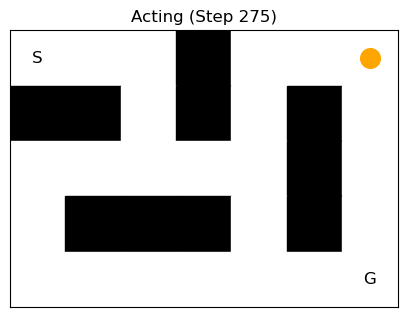

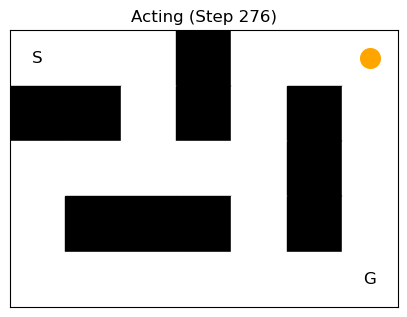

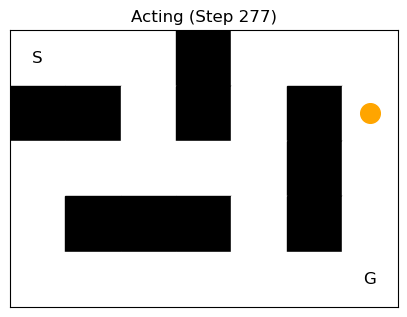

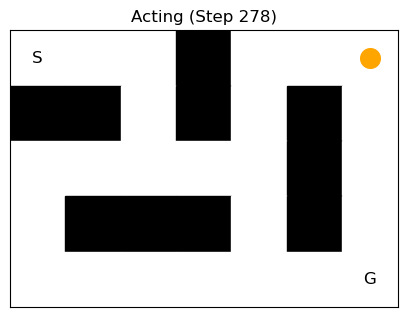

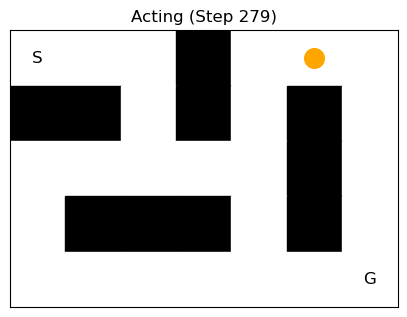

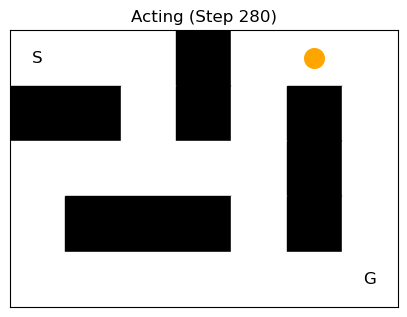

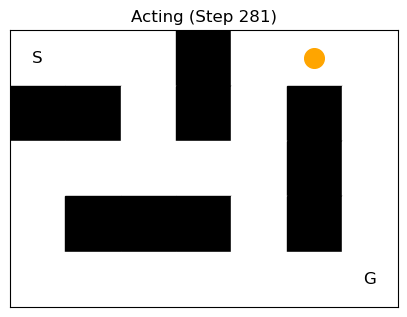

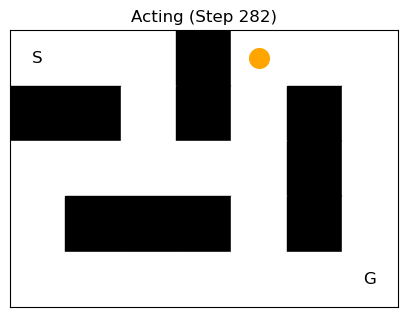

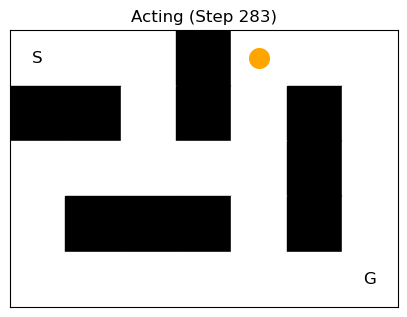

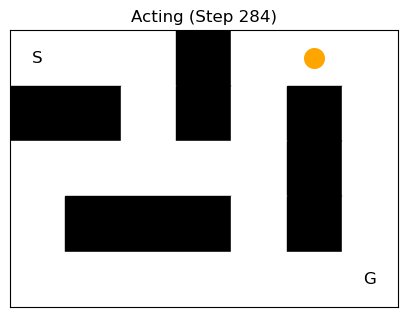

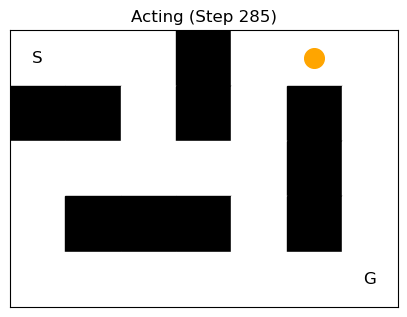

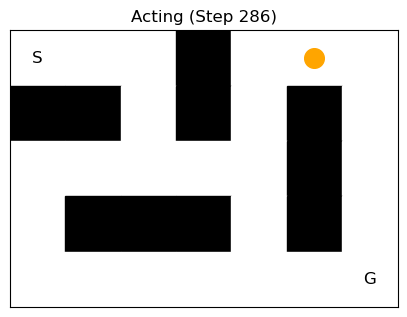

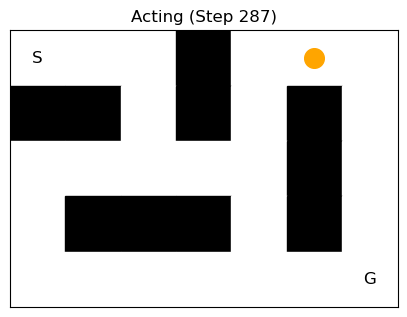

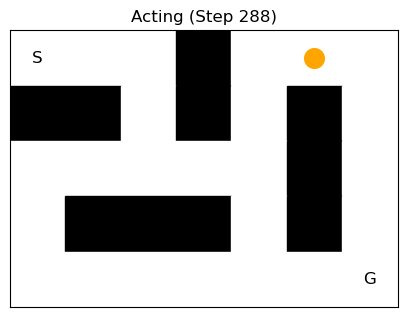

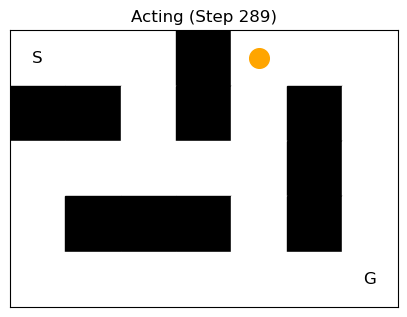

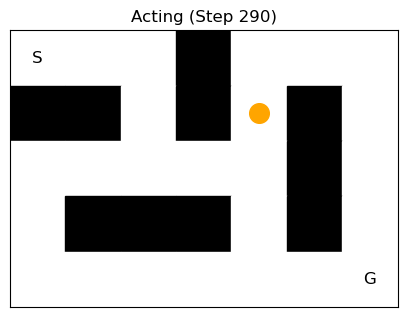

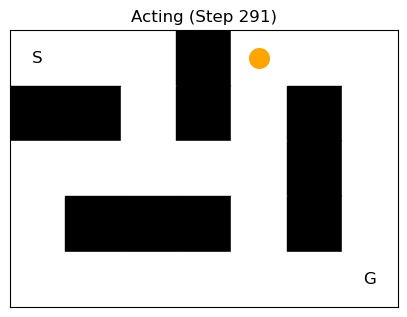

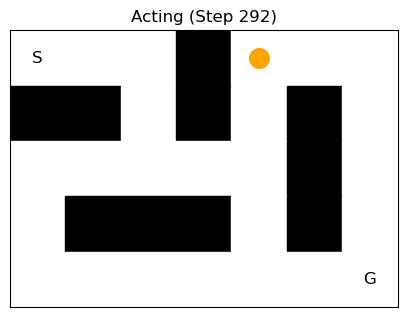

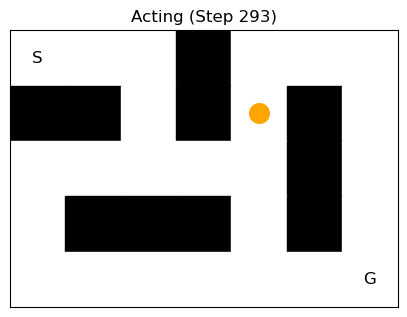

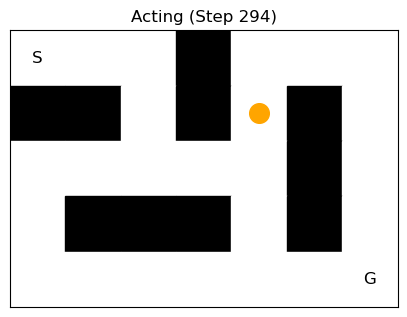

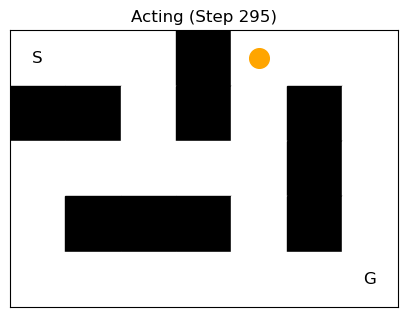

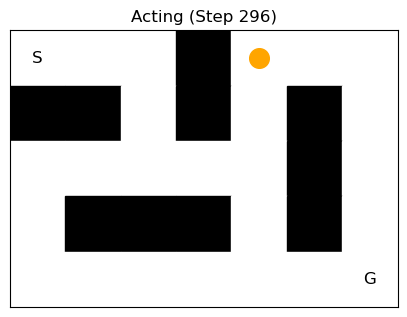

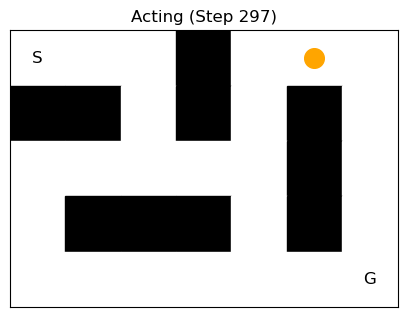

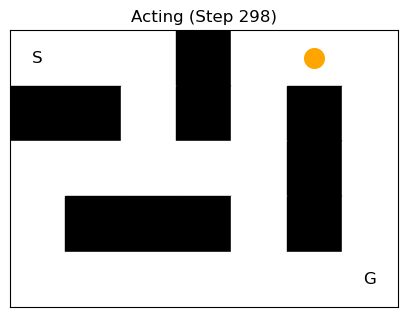

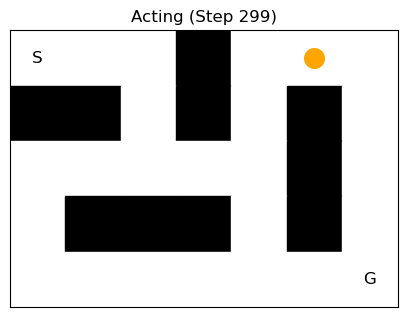

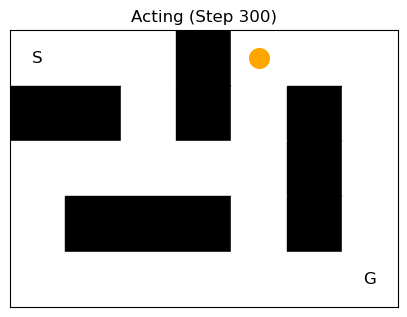

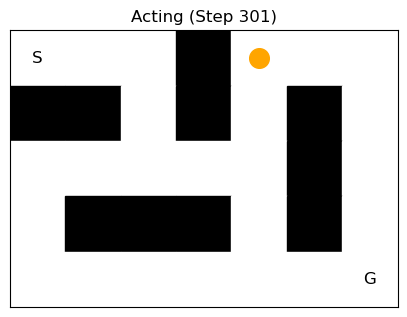

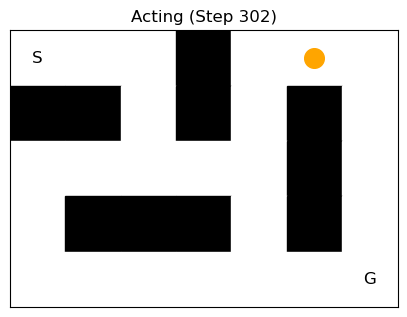

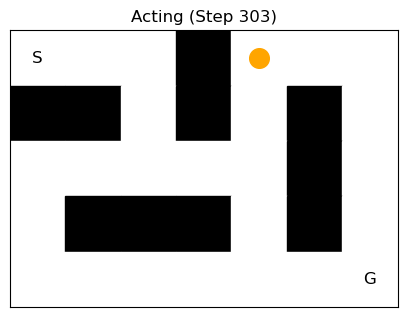

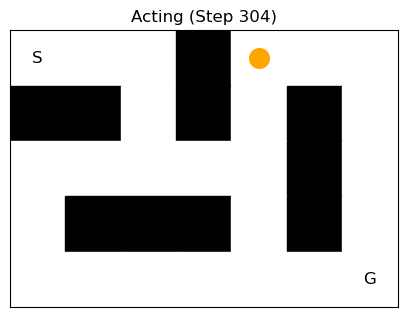

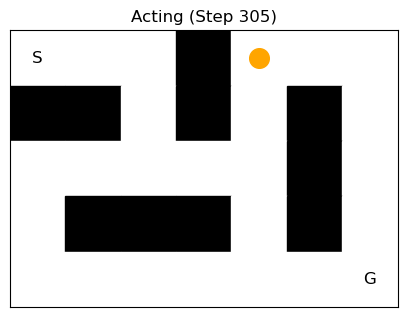

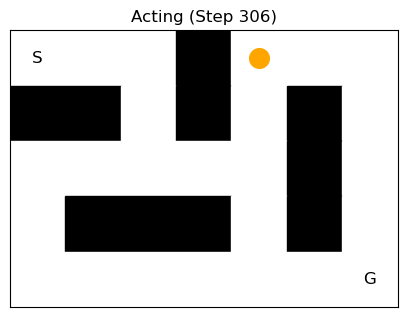

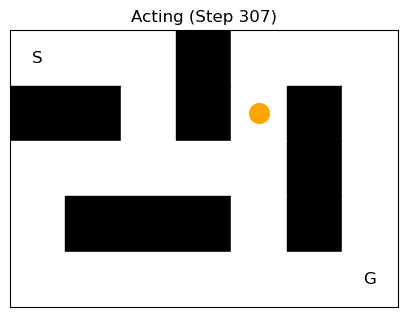

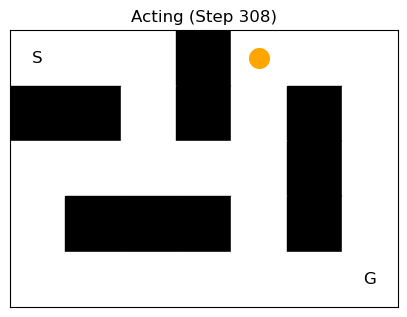

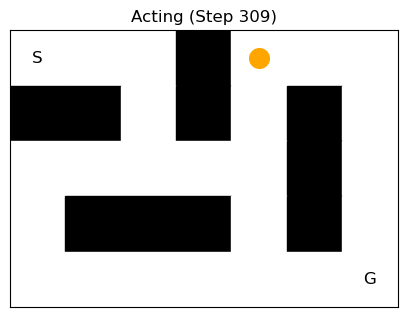

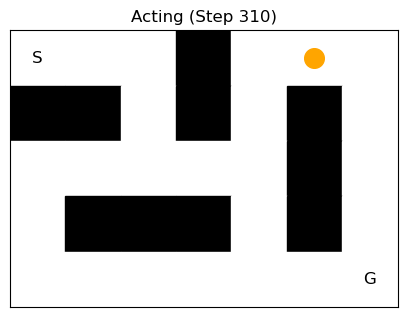

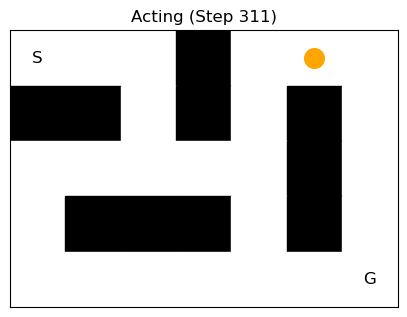

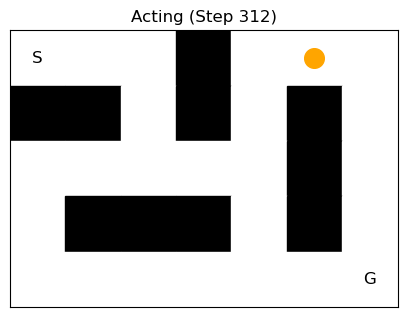

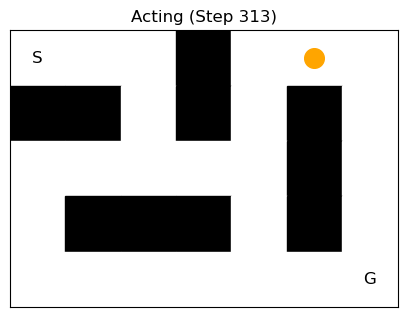

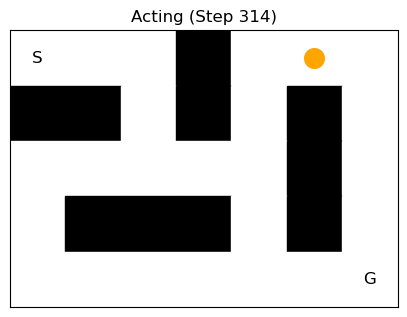

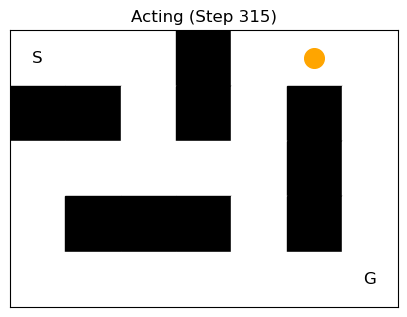

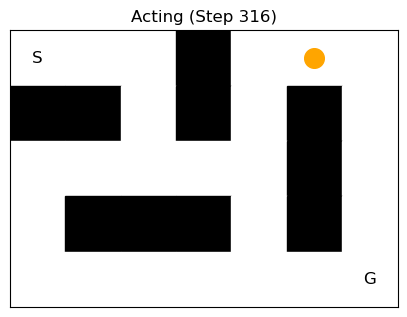

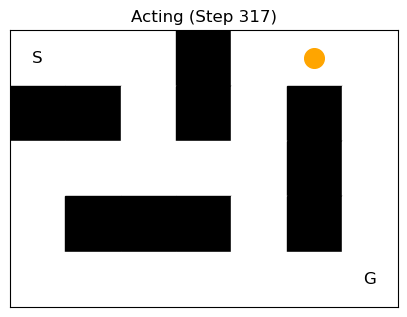

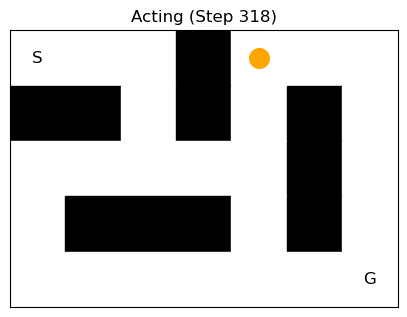

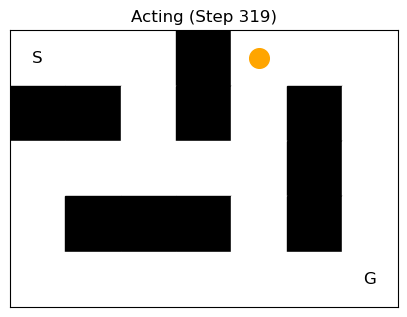

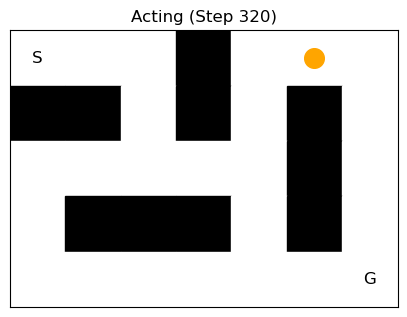

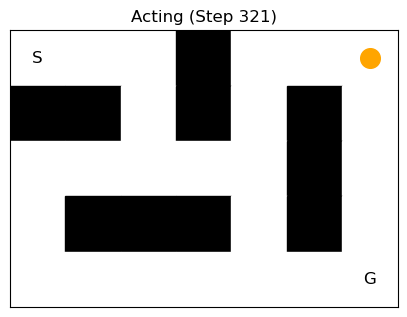

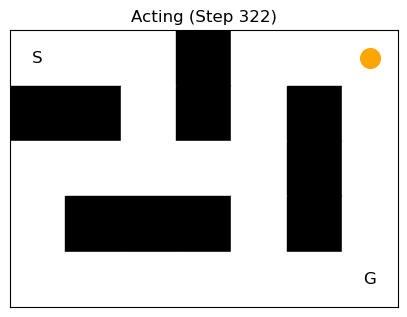

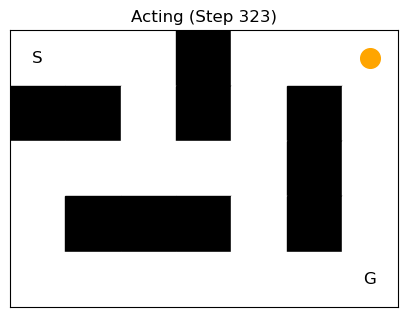

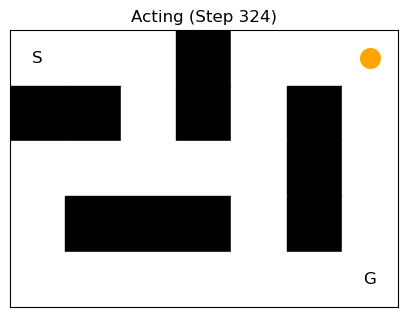

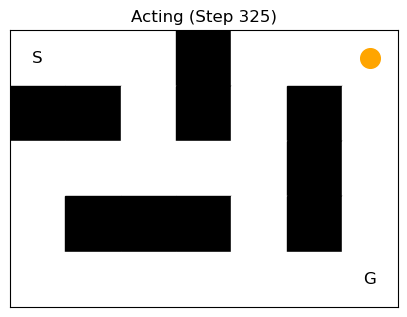

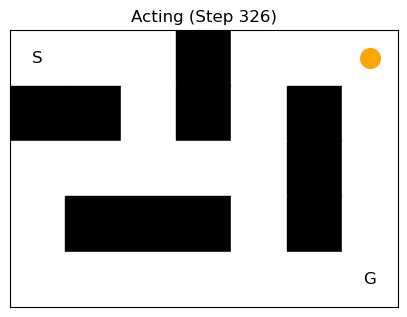

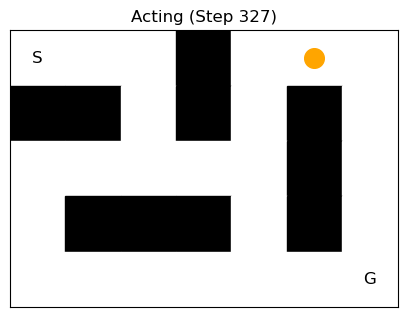

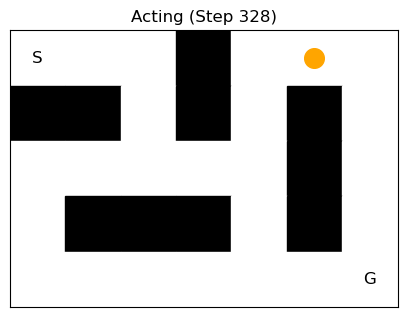

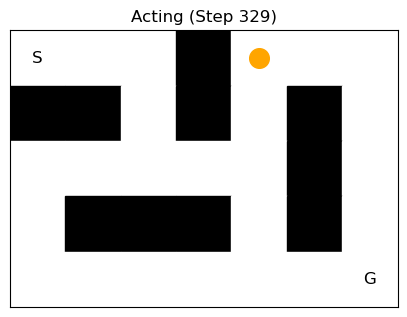

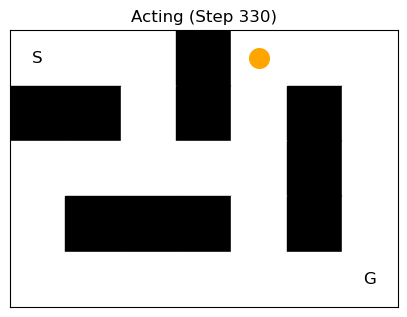

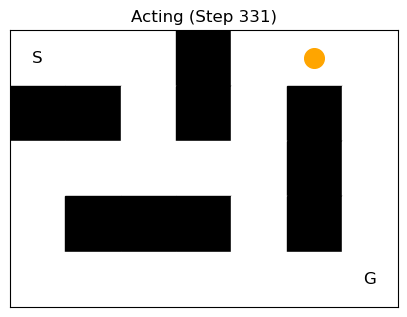

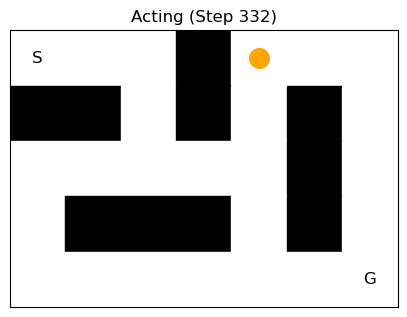

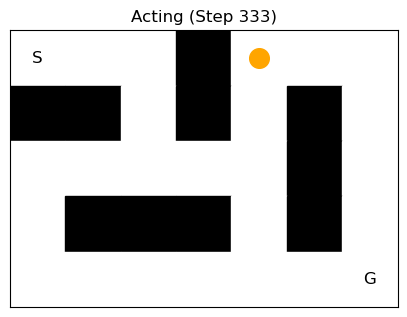

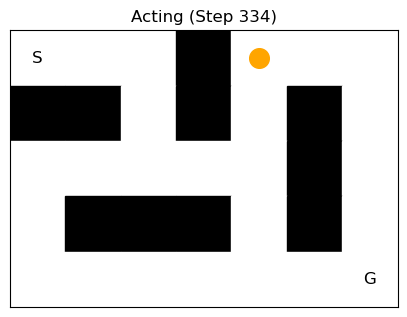

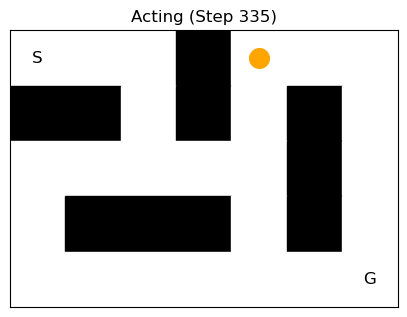

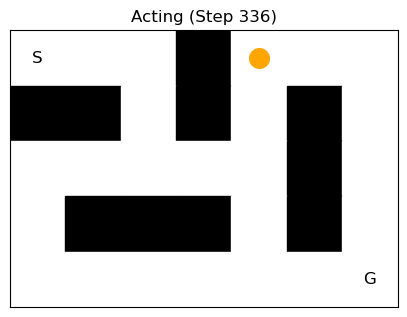

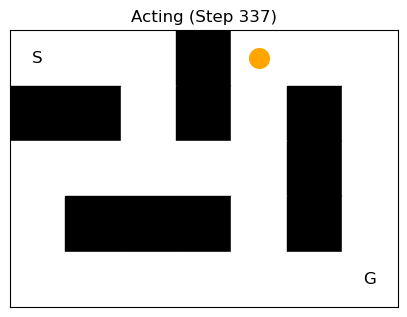

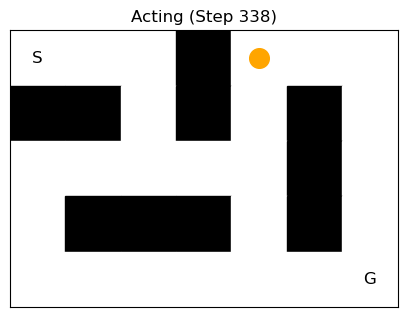

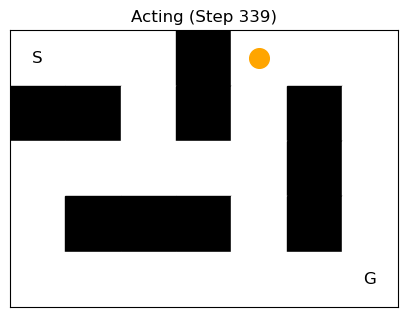

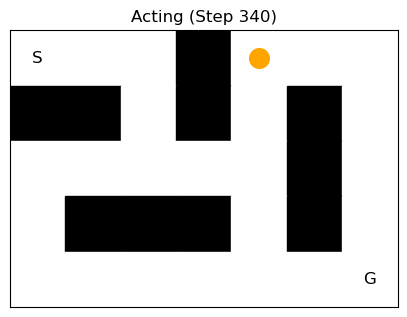

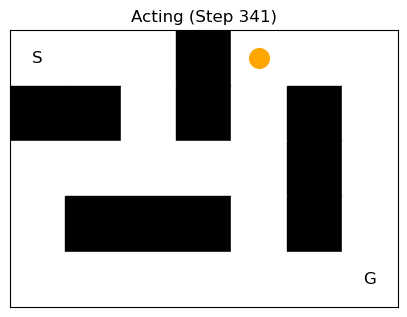

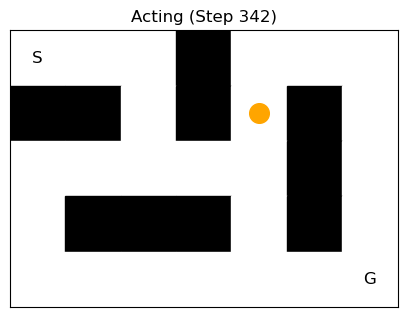

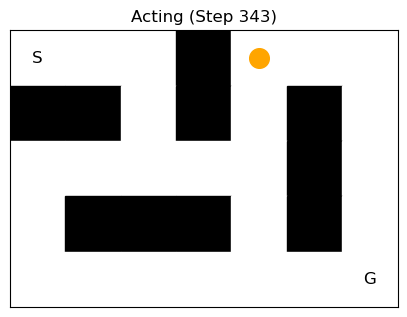

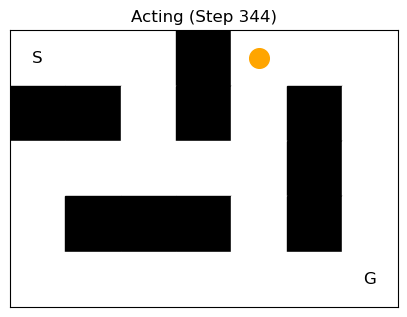

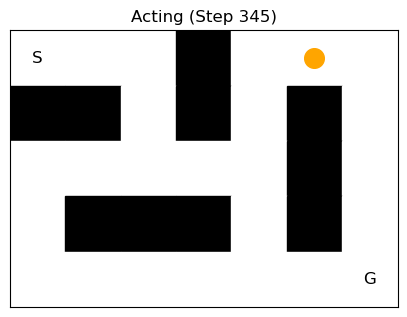

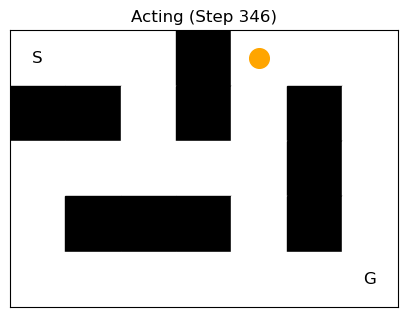

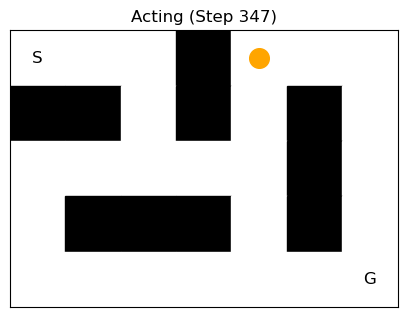

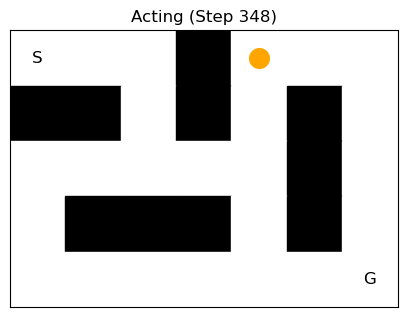

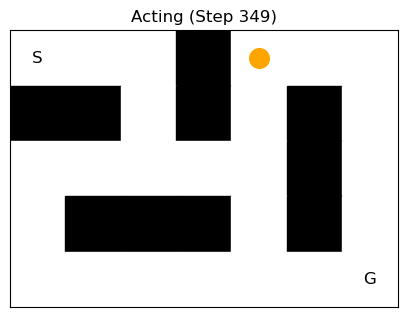

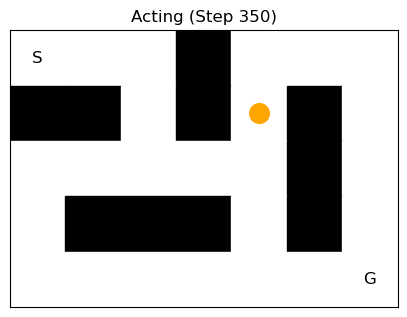

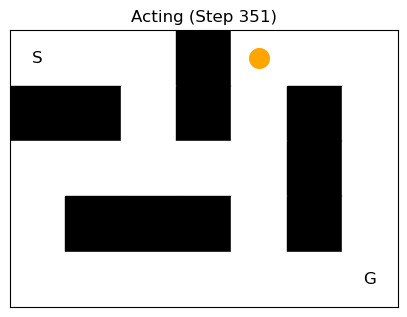

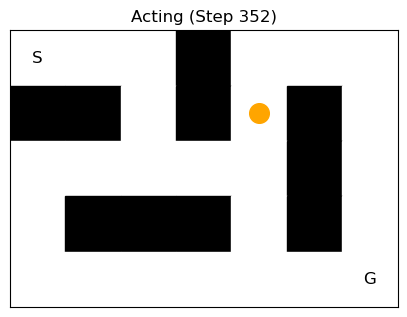

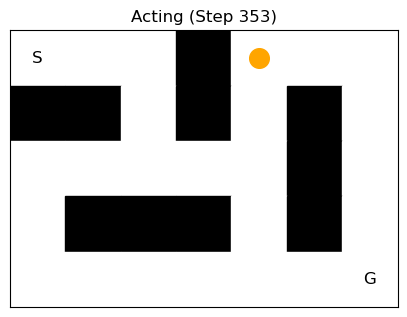

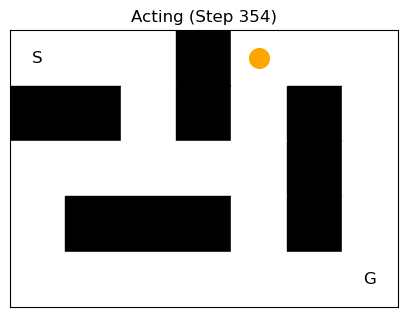

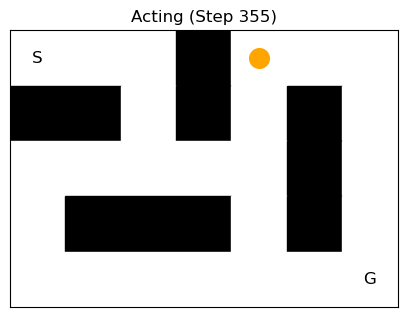

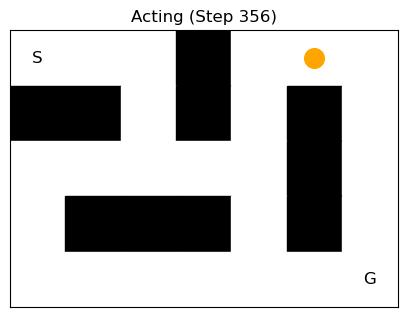

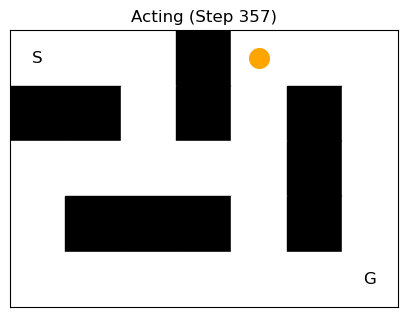

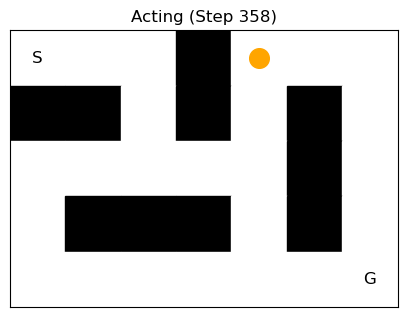

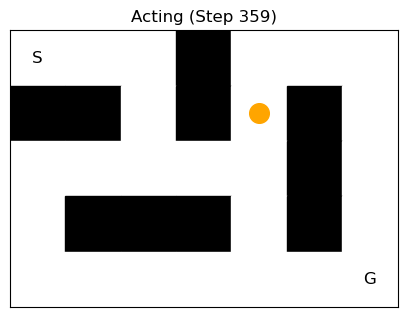

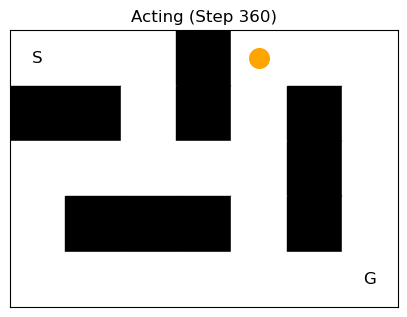

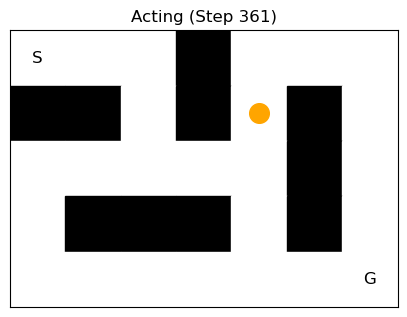

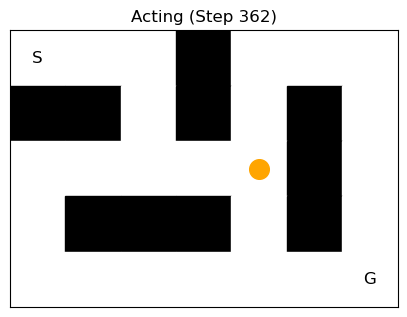

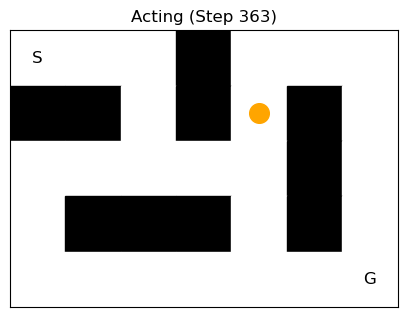

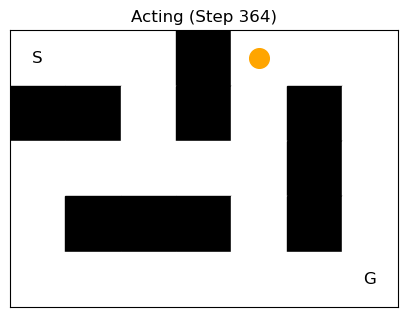

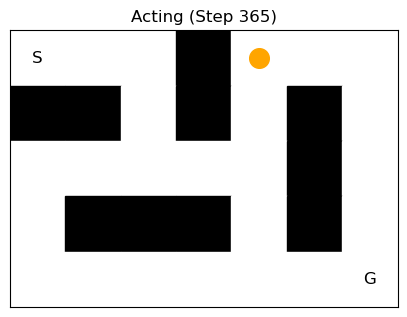

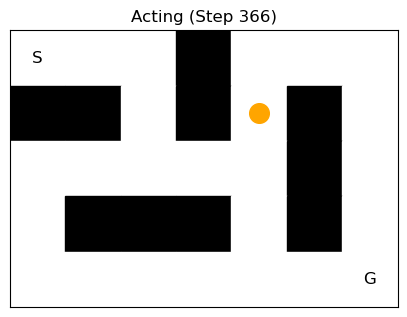

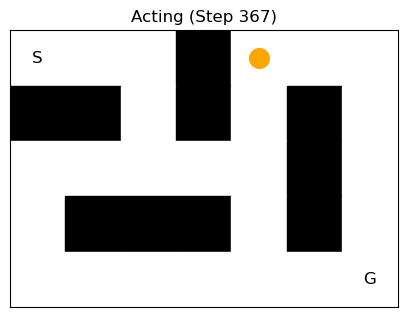

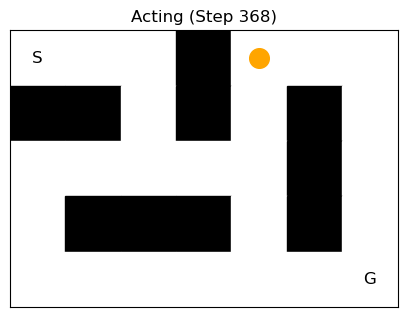

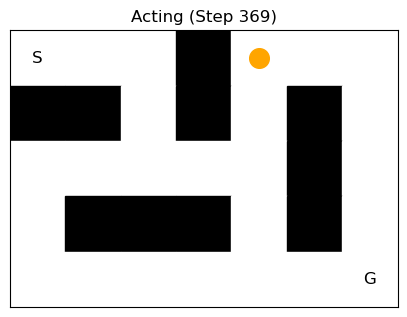

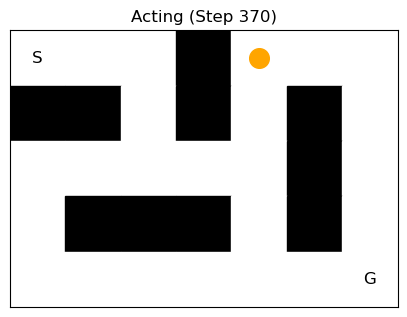

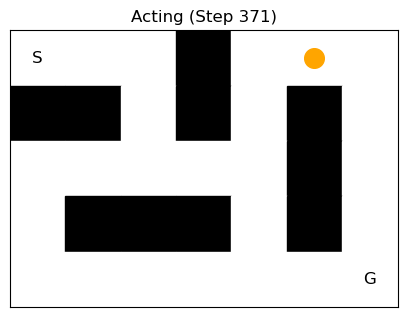

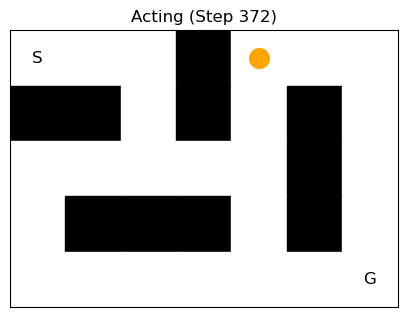

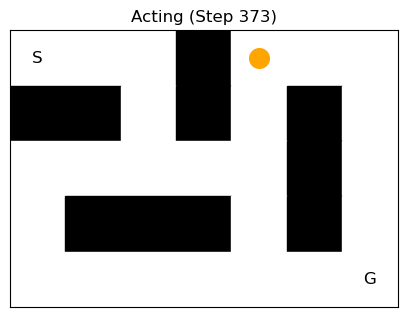

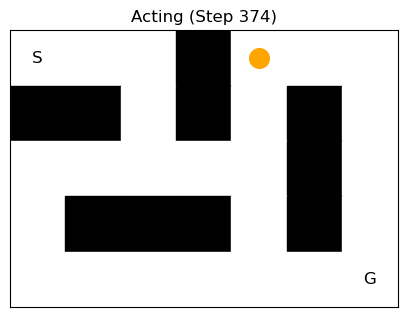

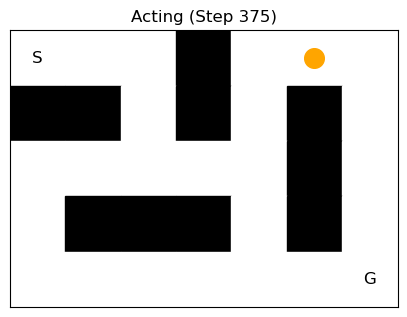

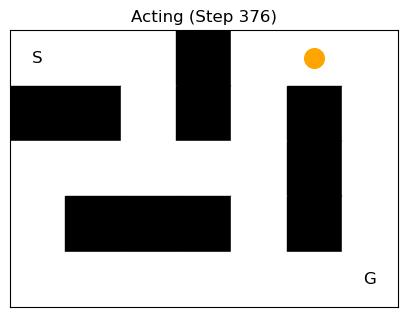

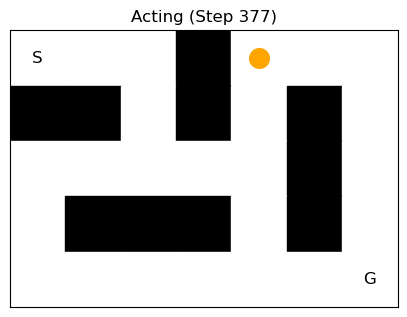

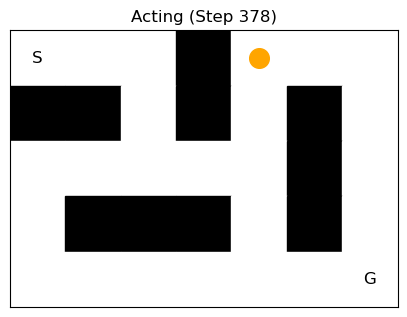

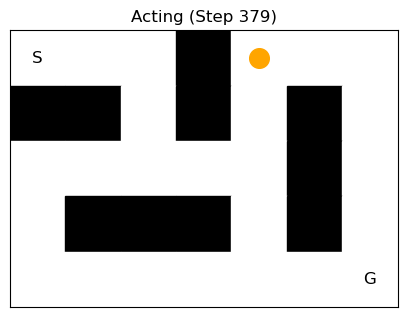

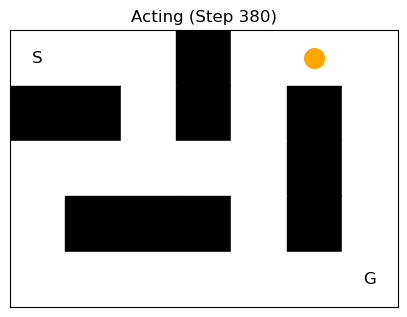

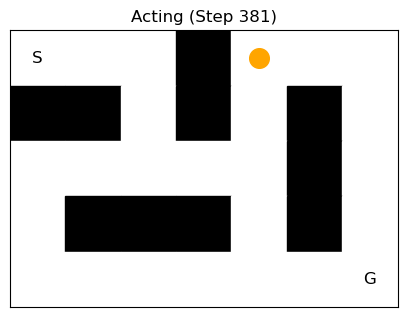

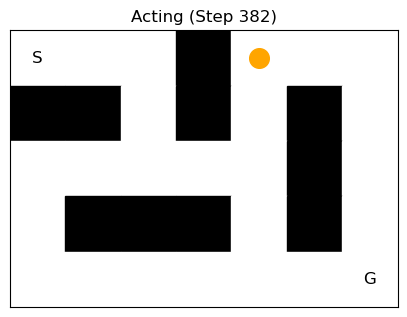

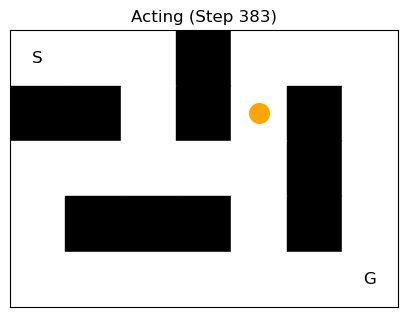

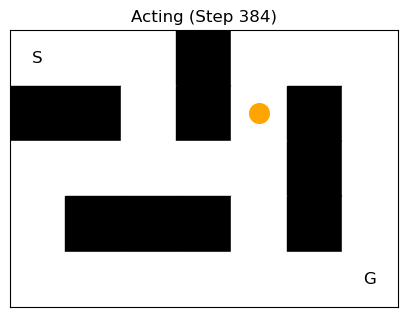

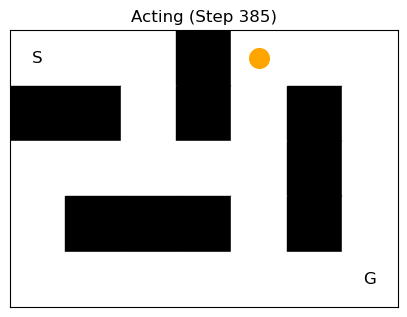

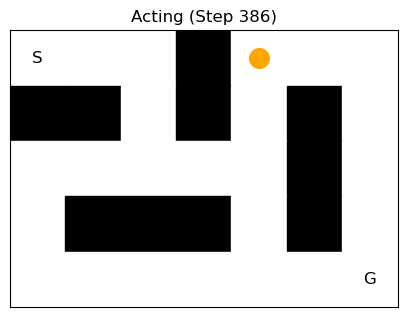

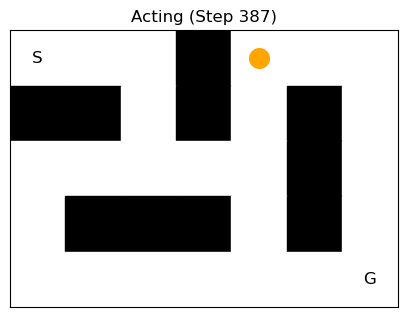

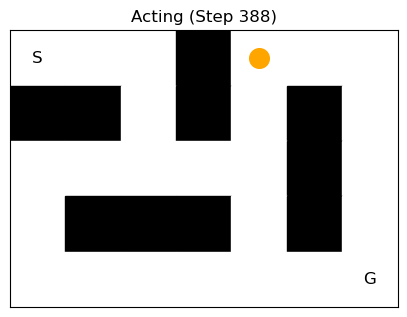

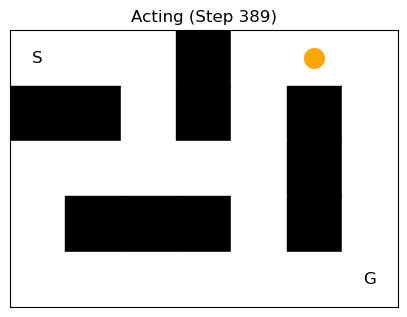

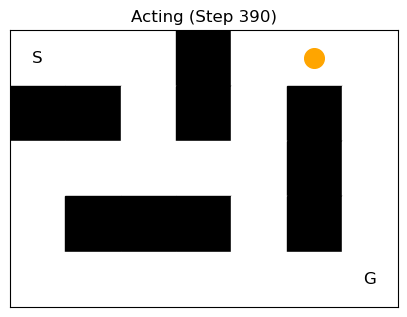

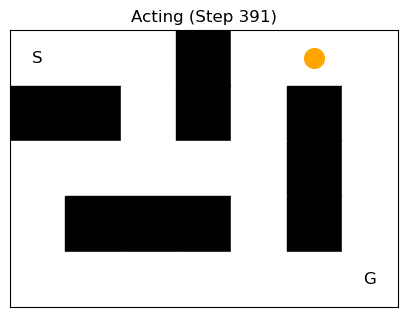

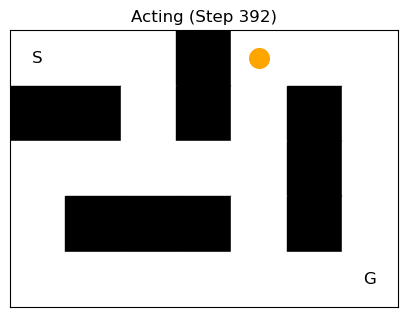

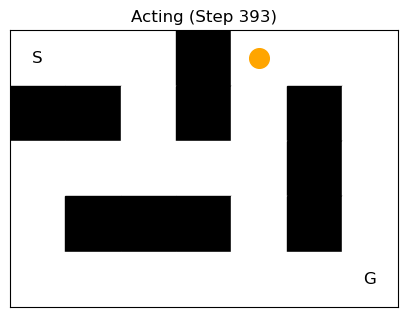

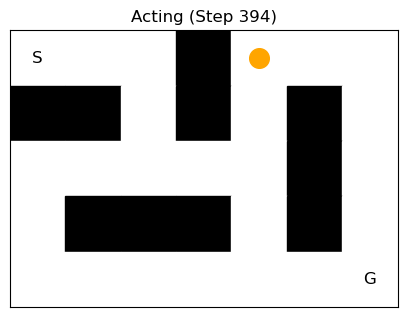

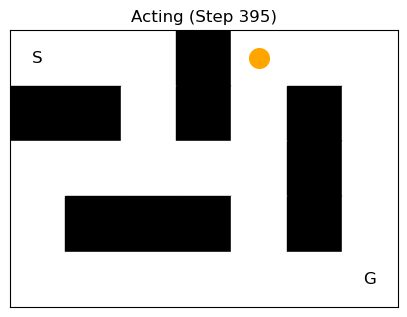

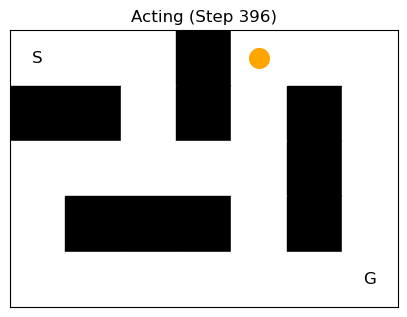

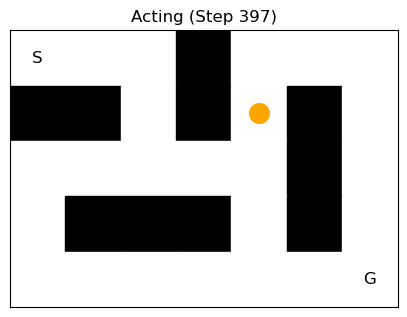

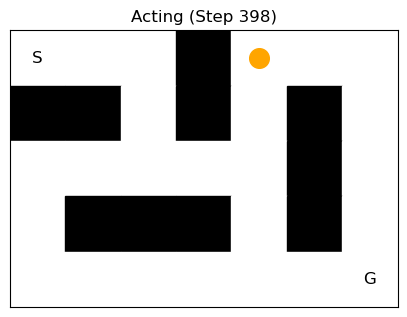

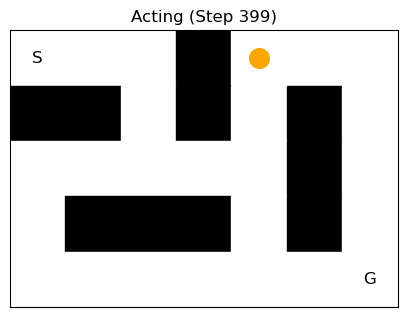

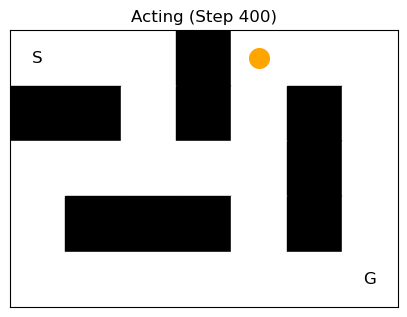

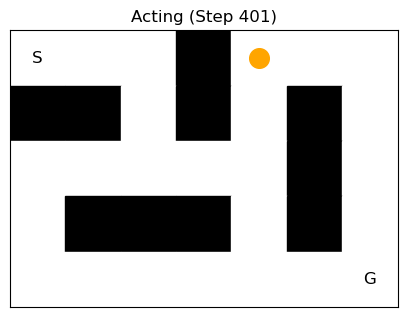

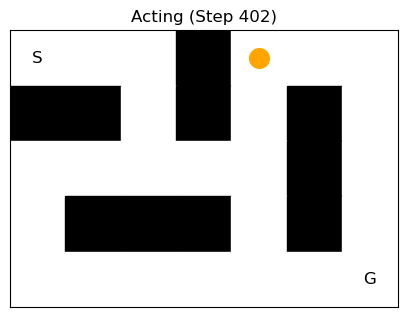

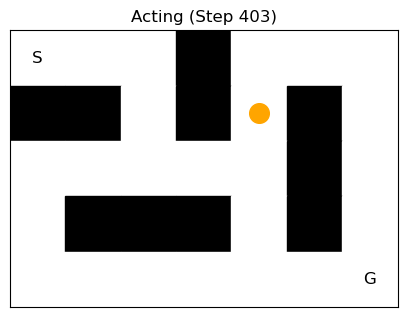

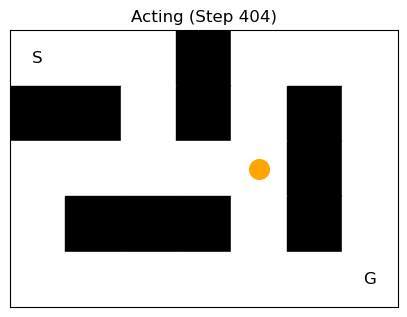

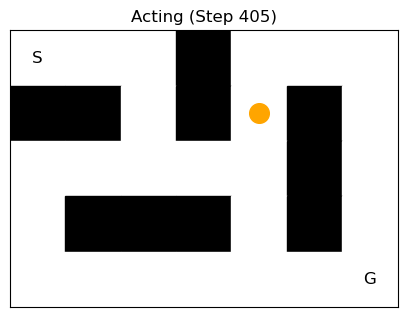

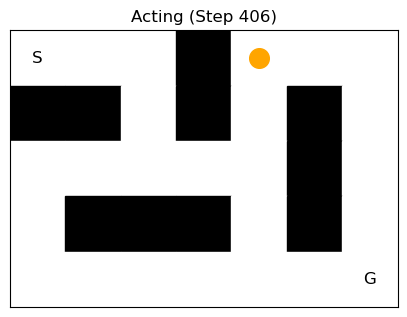

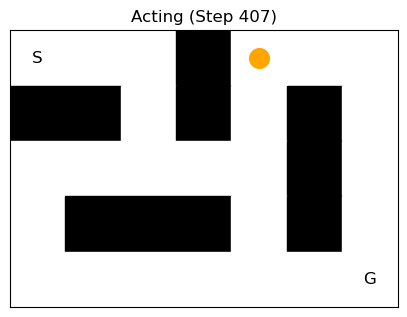

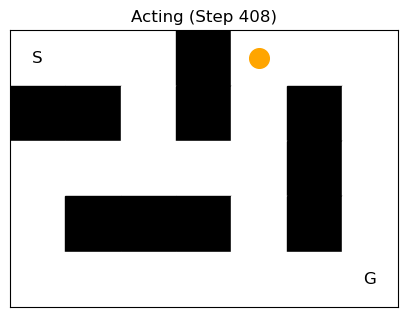

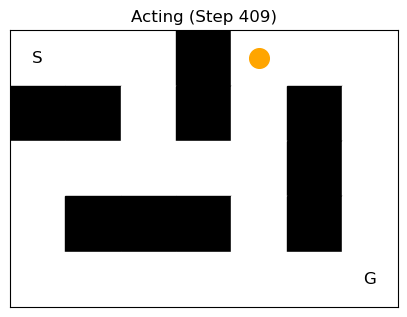

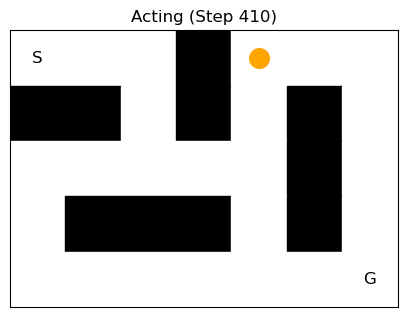

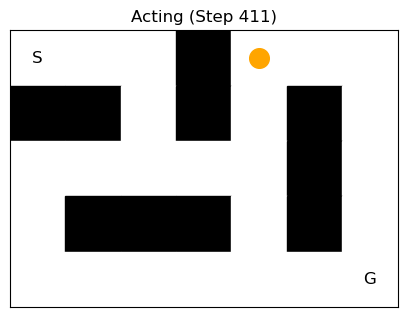

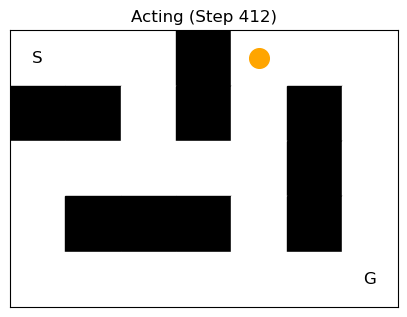

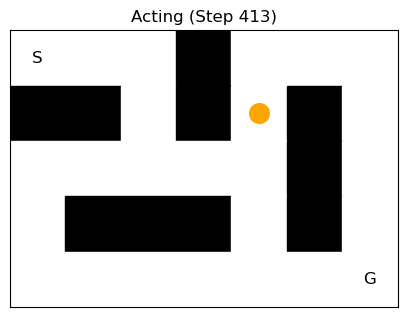

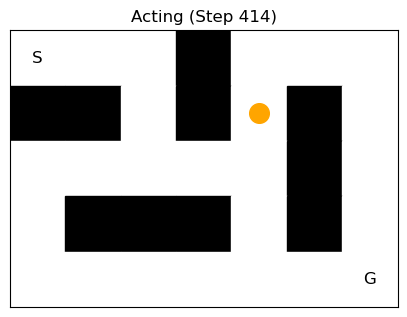

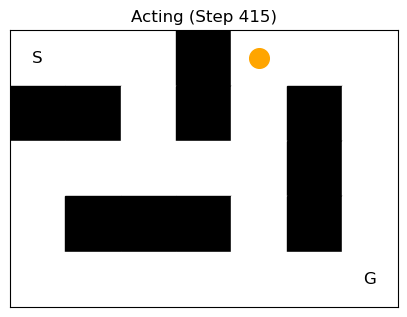

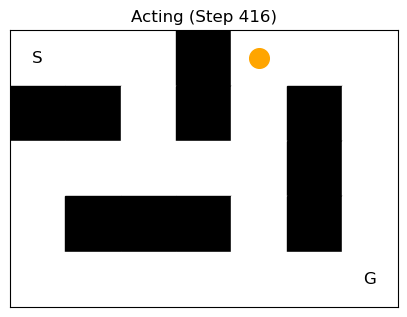

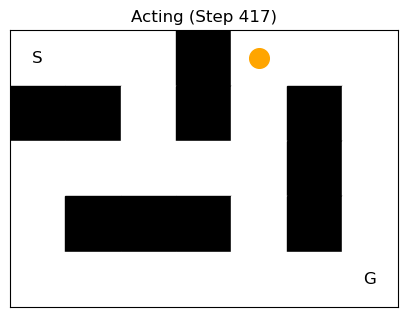

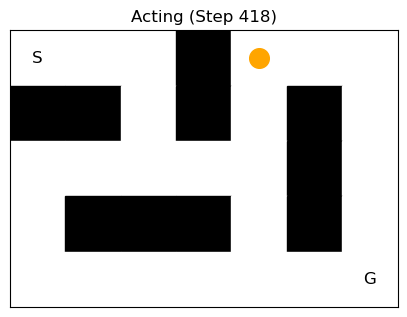

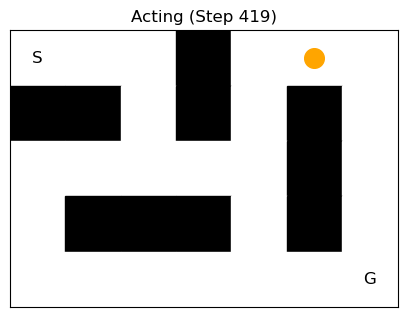

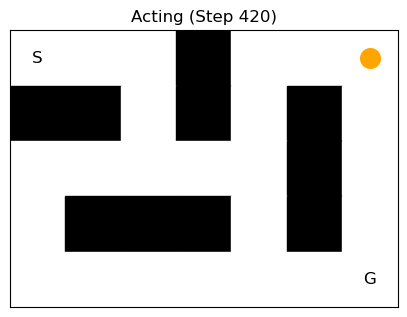

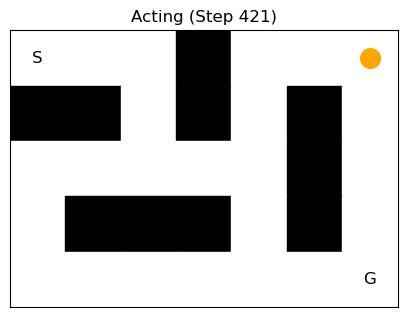

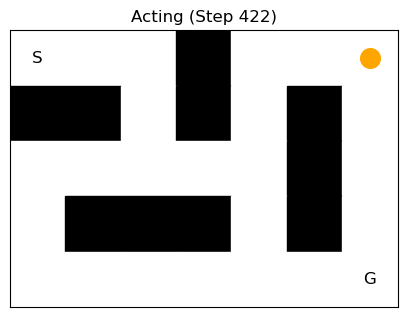

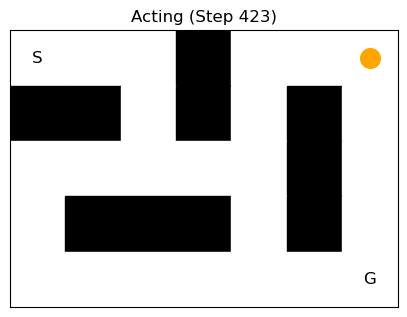

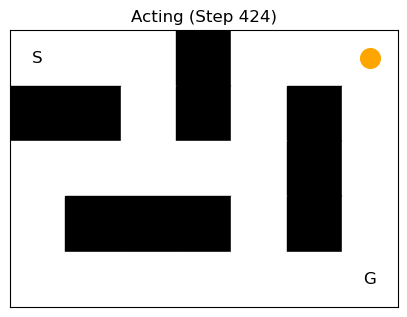

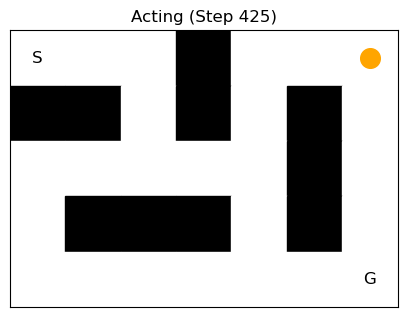

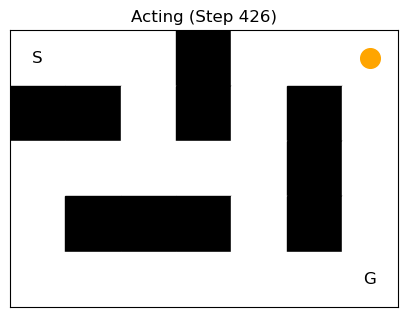

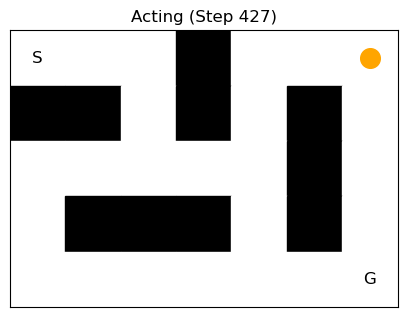

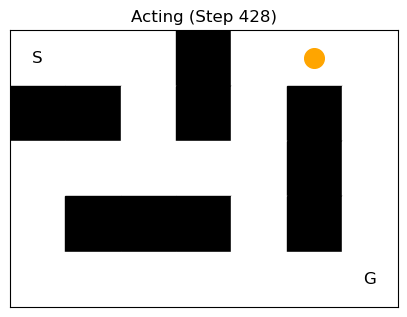

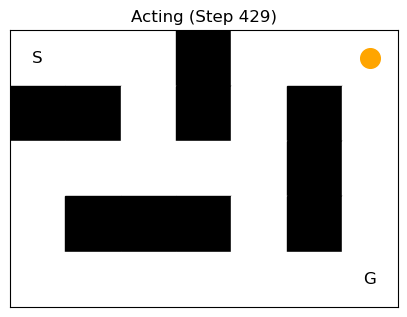

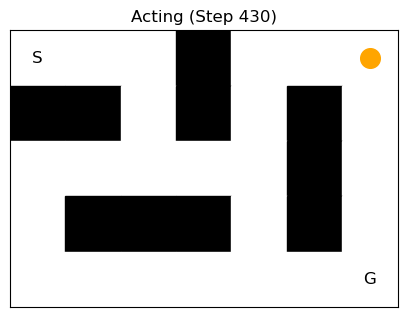

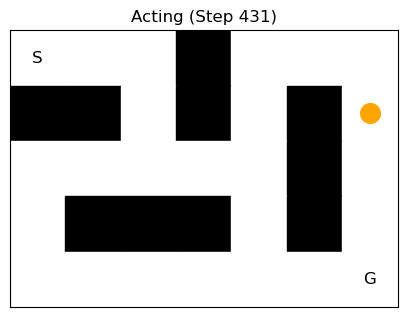

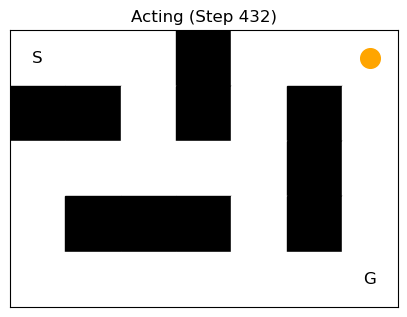

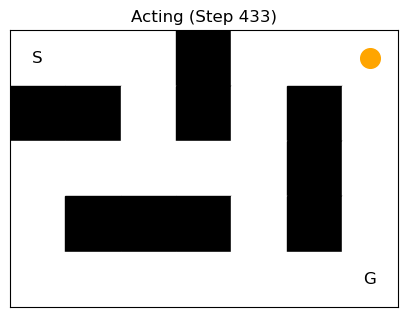

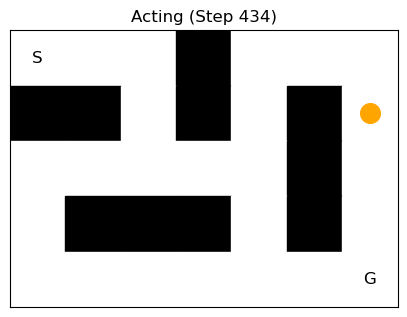

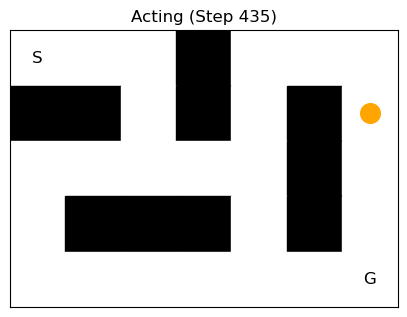

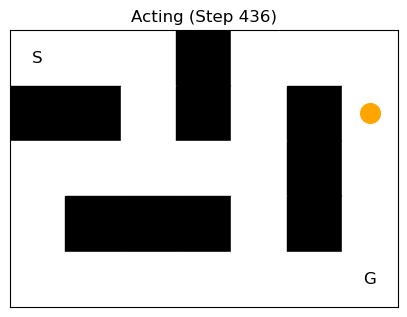

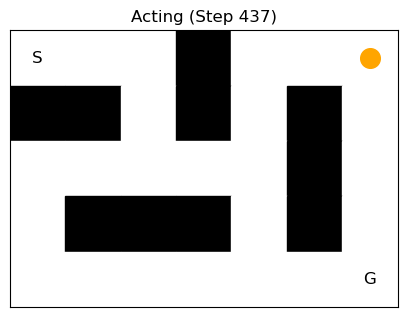

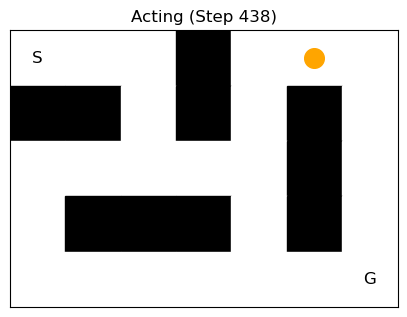

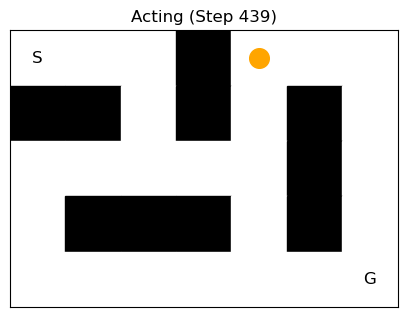

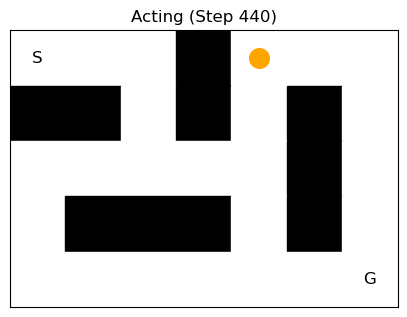

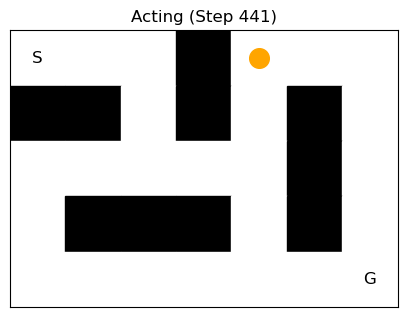

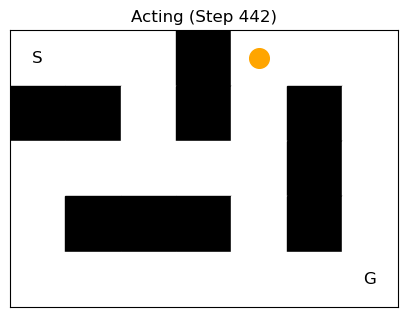

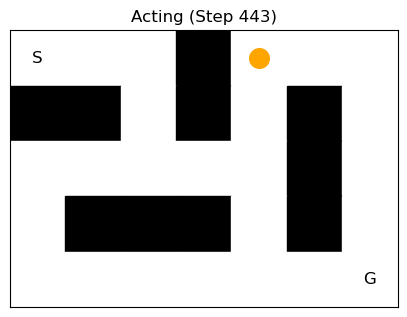

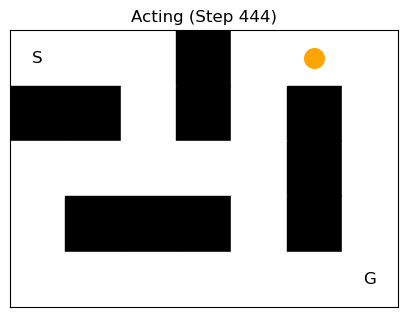

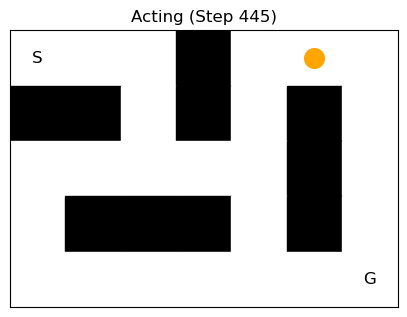

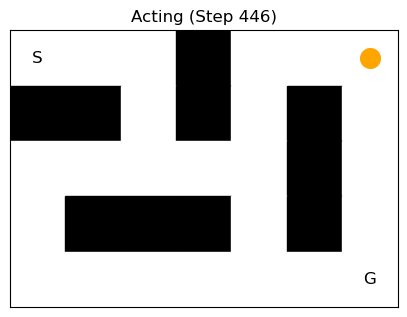

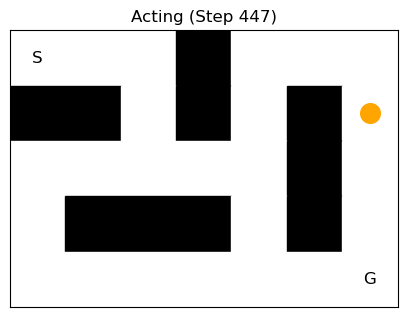

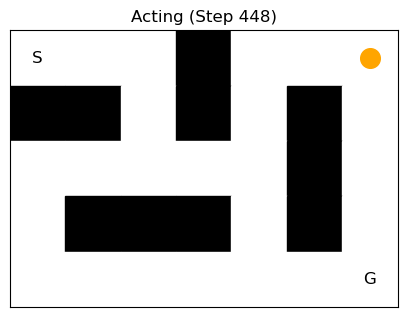

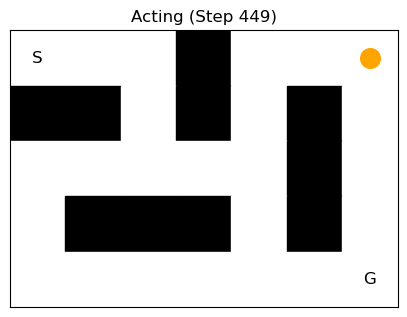

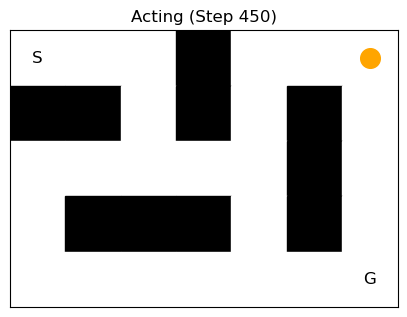

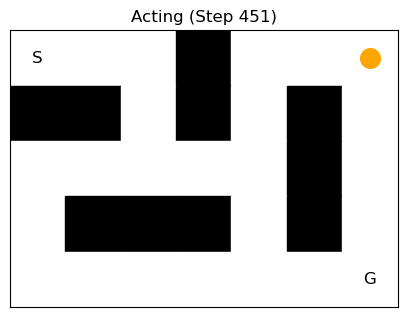

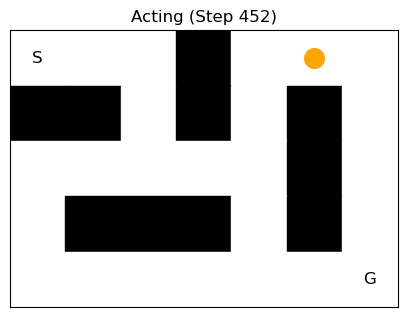

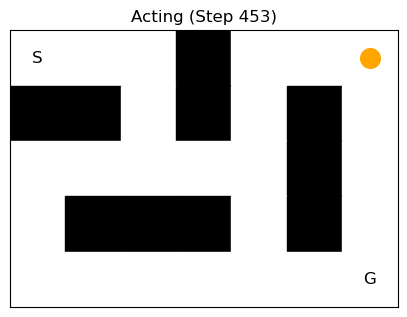

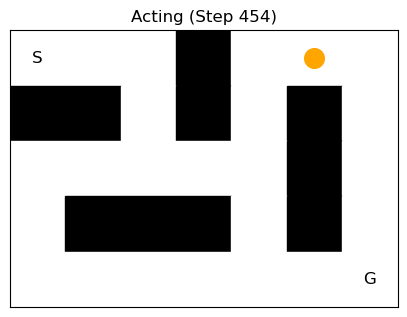

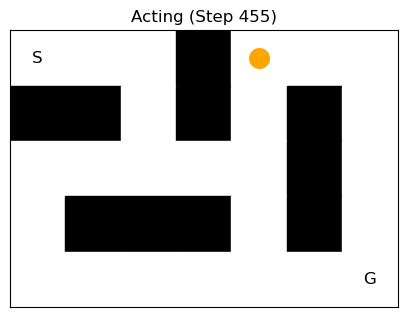

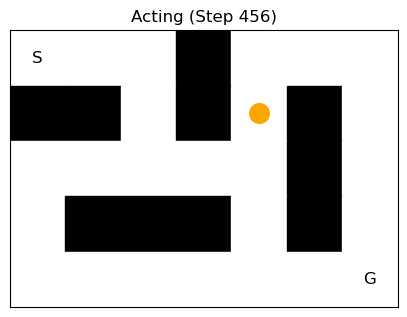

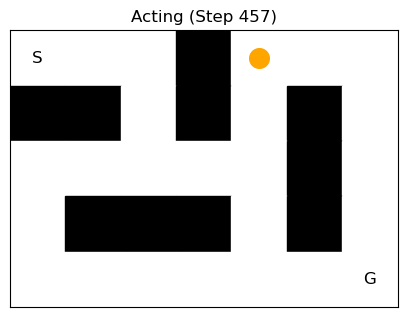

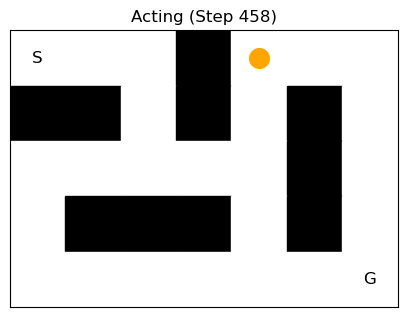

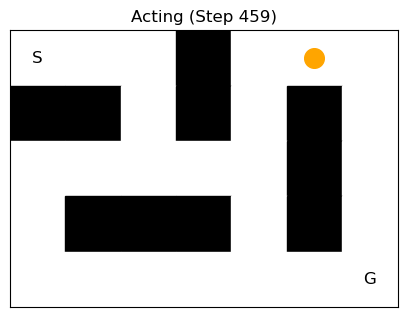

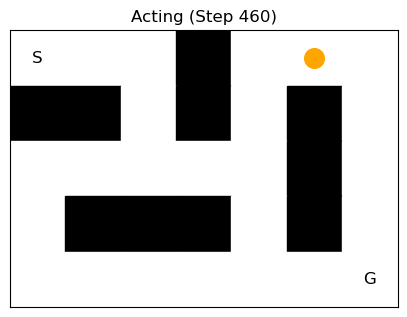

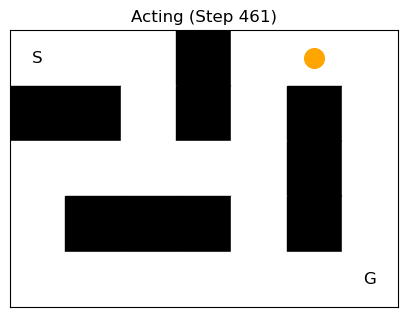

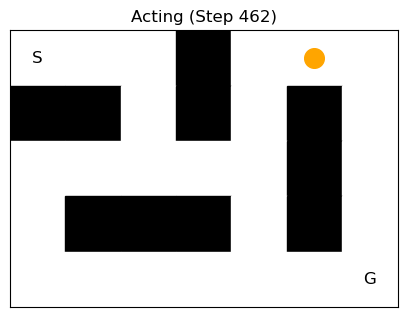

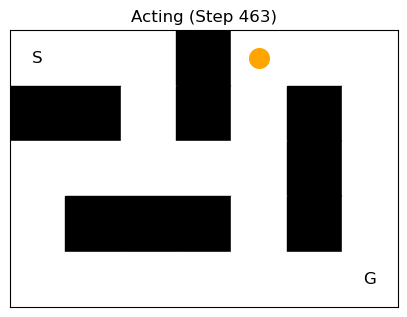

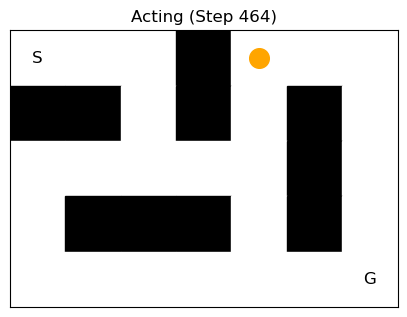

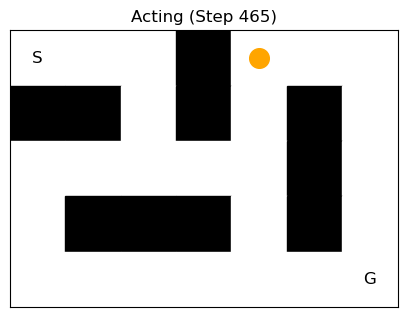

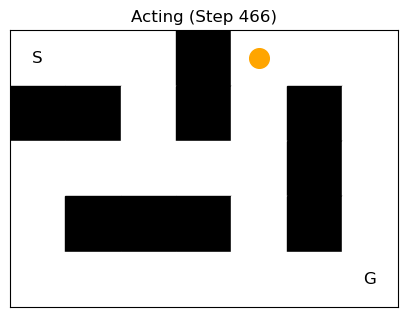

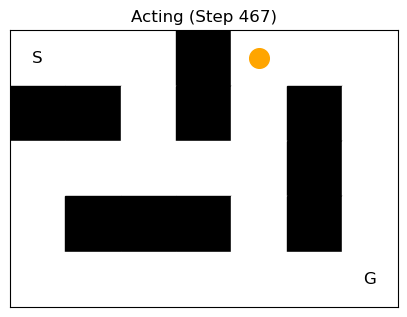

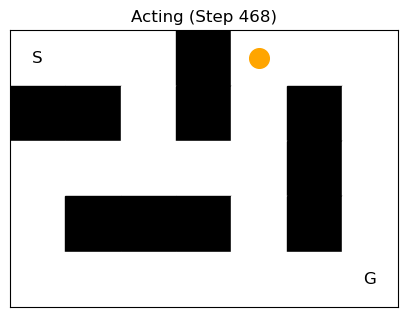

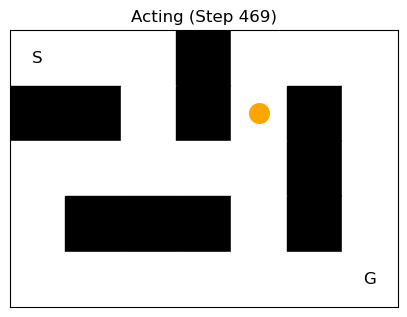

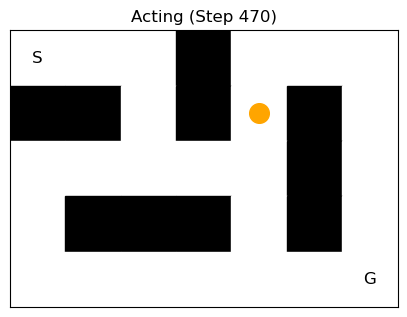

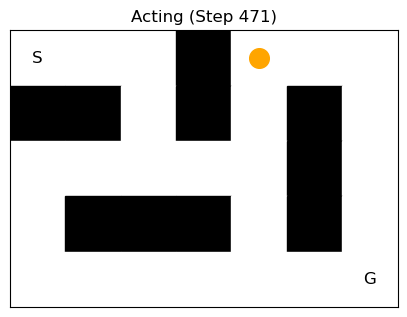

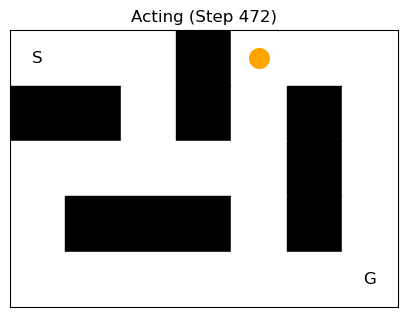

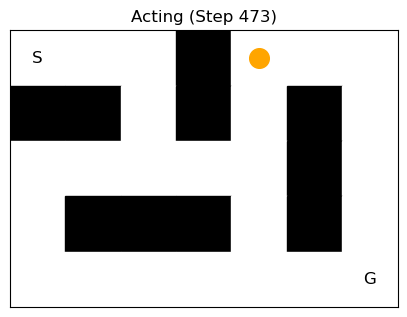

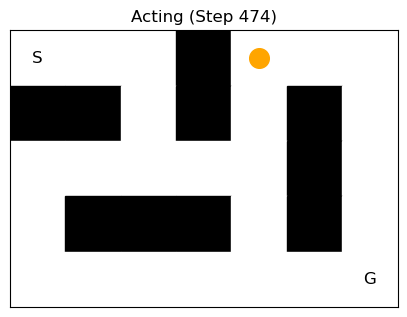

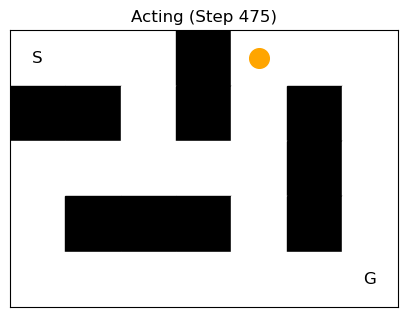

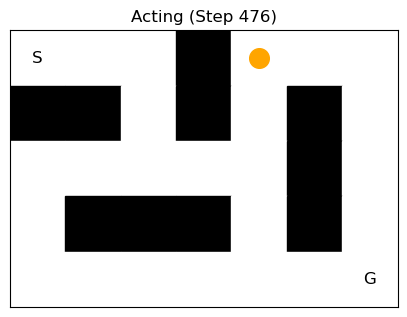

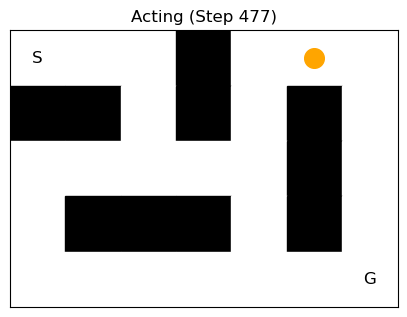

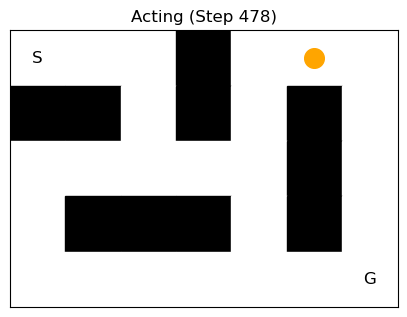

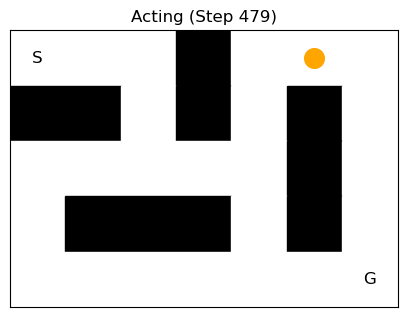

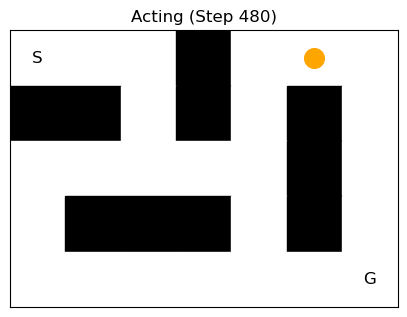

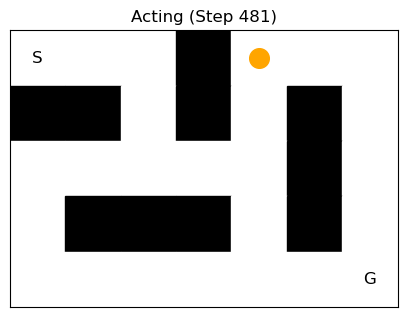

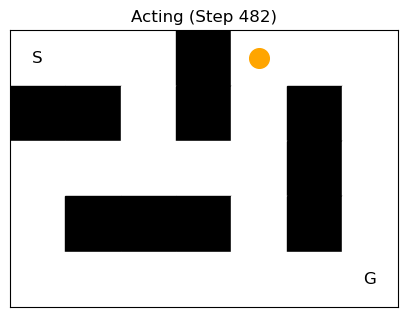

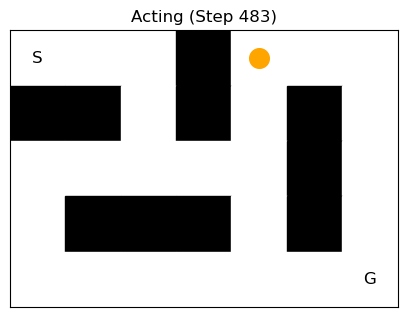

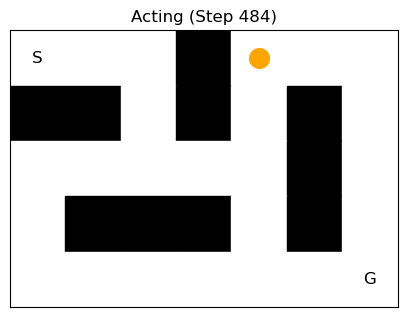

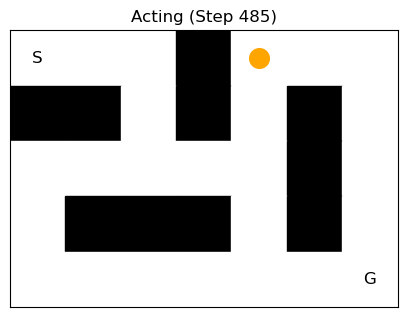

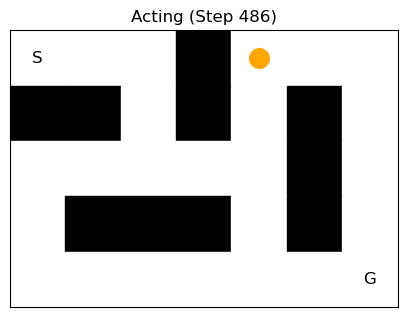

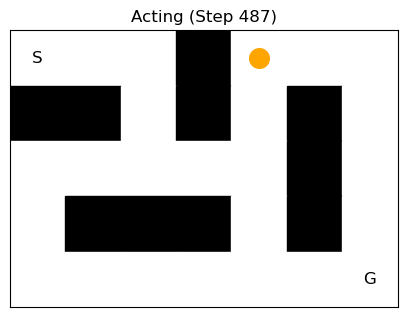

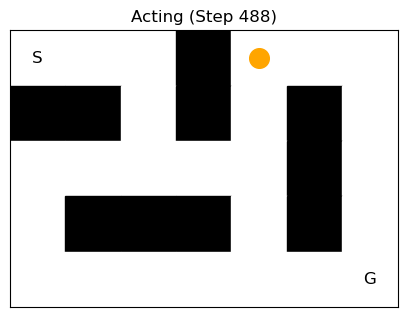

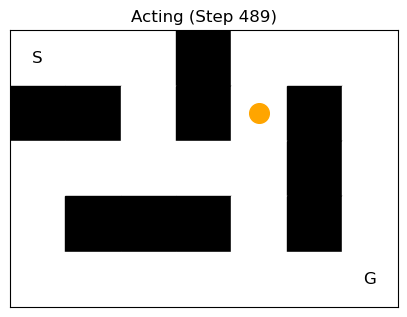

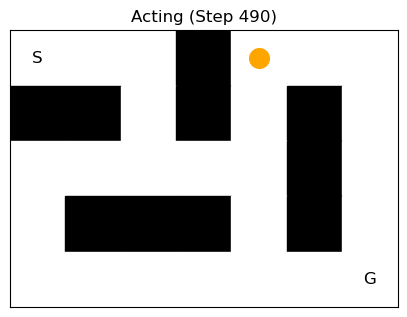

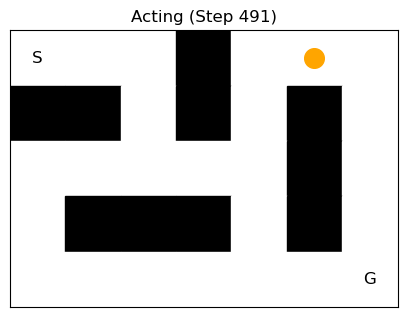

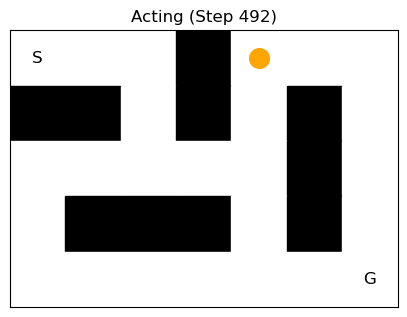

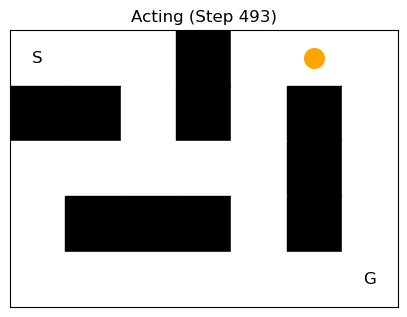

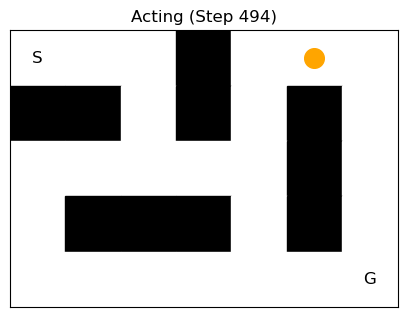

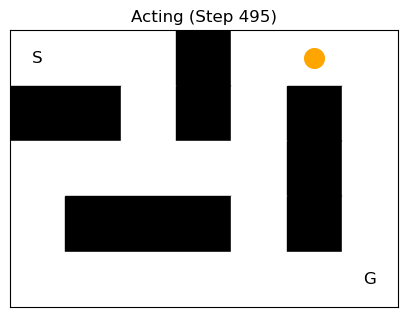

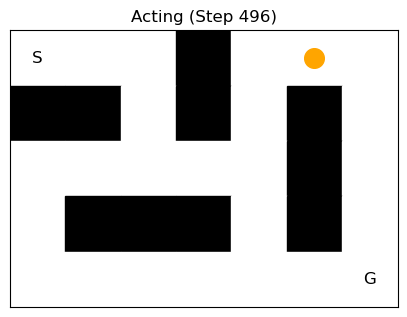

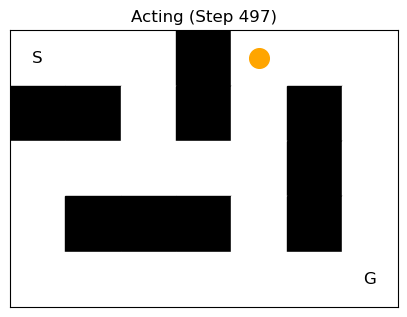

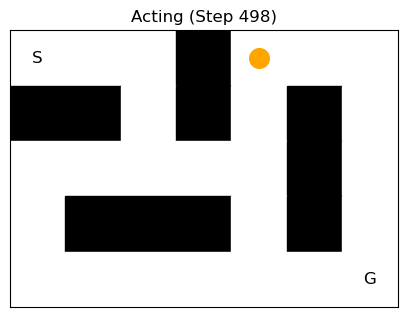

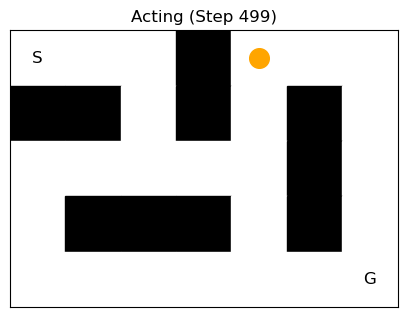

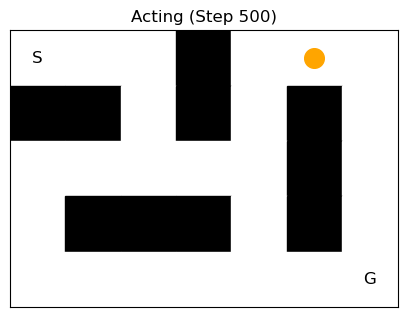

❌ Episode ended without reaching goal


In [18]:
agent = Agent(epsilon=0.7)
run_agent_episode(env, agent, max_steps=500, delay=0.2)

## Breaking the Planning Trap (Curiosity / Uncertainty)

Till now we saw
- ε ≥ 0.8 → succeeds
- ε ≤ 0.7 → fails systematically

This means:

`Exploration is required to correct value bias introduced by imagination.`

So the fix is not more planning.
The fix is directed exploration.

### To deal with this, We add __one counter__.

If the agent has little experience with a state-action pair, it should:

- prefer it occasionally
- even if Q-value is low

This helps:

- escape planning attractors
- correct biased imagination
- reduce ε dependence

In [6]:
# new Agent

import random
from collections import defaultdict

class Agent:
    def __init__(
        self,
        action_space=4,
        epsilon=0.1,
        imagination_horizon=6,
        imagination_rollouts=10,
        alpha=0.1,
        gamma=0.95
    ):
        self.action_space = action_space
        self.epsilon = epsilon

        self.imagination_horizon = imagination_horizon
        self.imagination_rollouts = imagination_rollouts

        self.alpha = alpha
        self.gamma = gamma

        self.visit_count = defaultdict(int)
        self.beta = 0.5  # curiosity strength

        self.world_model = WorldModel()

        # 🧠 VALUE FUNCTION
        self.Q = defaultdict(float)
    def learn_model(self, state, action, next_state, reward):
        # update world model
        self.world_model.update(state, action, next_state, reward)
    
        # 🔑 Q-learning update
        best_next = max(
            self.Q[(next_state, a)] for a in range(self.action_space)
        )
        self.Q[(state, action)] += self.alpha * (
            reward + self.gamma * best_next - self.Q[(state, action)]
        )
        self.visit_count[(state, action)] += 1
        
    def curiosity_bonus(self, state, action):
        return self.beta / (1 + self.visit_count[(state, action)])

    def is_confident(self, state, threshold=0.5):
        q_vals = [self.Q[(state, a)] for a in range(self.action_space)]
        return max(q_vals) - min(q_vals) > threshold


    def plan_and_act(self, state):
        # exploration always allowed
        if random.random() < self.epsilon:
            return random.randint(0, self.action_space - 1), None, None
    
        # 🔒 confidence gate
        if not self.is_confident(state):
            # model-free greedy fallback
            best_a = max(
                range(self.action_space),
                key=lambda a: self.Q[(state, a)] + self.curiosity_bonus(state, a)
            )
            return best_a, None, None
    
        # ✅ planning allowed only if confident
        imagined_paths = []
        action_values = {}
    
        for action in range(self.action_space):
            values = []
            paths = []
    
            for _ in range(self.imagination_rollouts):
                path, val = imagine_rollout(
                    self.world_model,
                    self.Q,
                    state,
                    action,
                    self.imagination_horizon,
                    self.action_space
                )
                if len(path) > 1:
                    values.append(val)
                    paths.append(path)
    
            if values:
                action_values[action] = sum(values) / len(values)
                imagined_paths.extend(paths)
    
        if not action_values:
            return random.randint(0, self.action_space - 1), None, None
    
        best_action = max(action_values, key=action_values.get)
        best_path, _ = imagine_rollout(
            self.world_model,
            self.Q,
            state,
            best_action,
            self.imagination_horizon,
            self.action_space
        )
    
        return best_action, imagined_paths, best_path



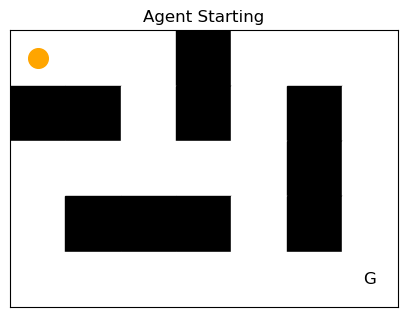

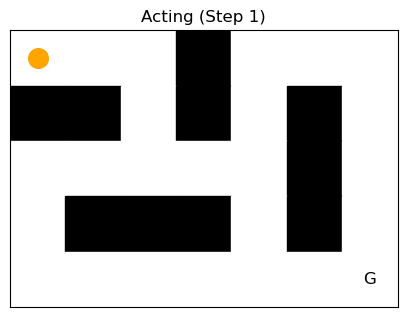

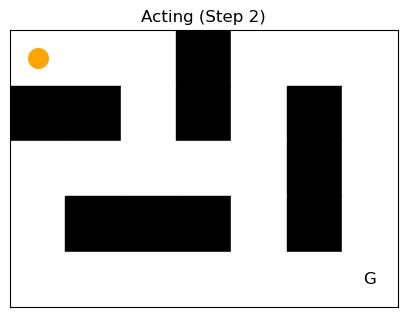

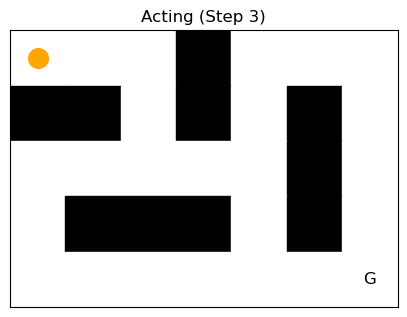

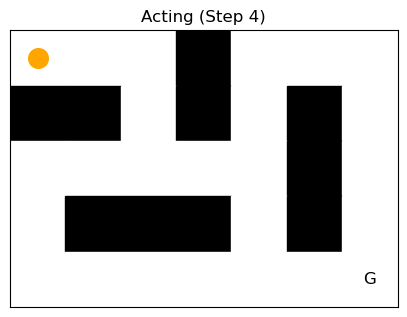

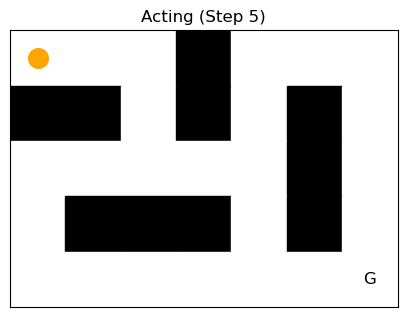

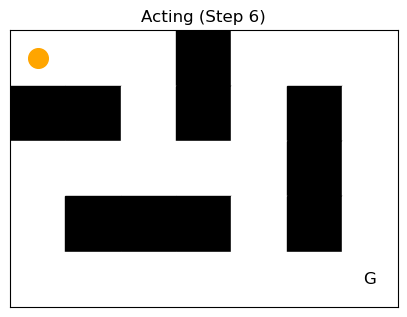

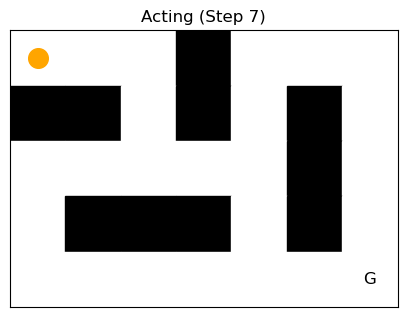

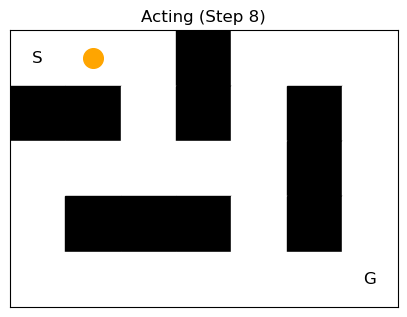

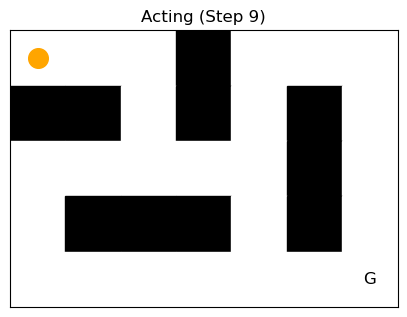

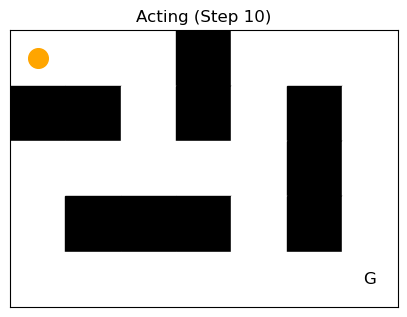

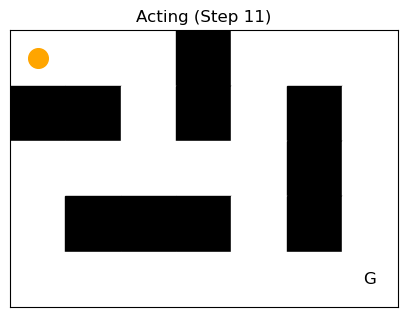

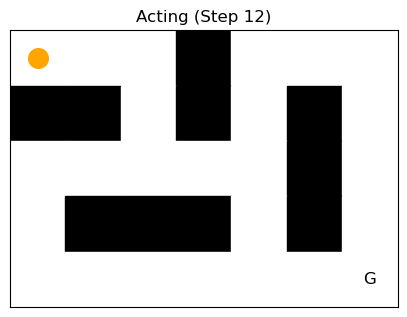

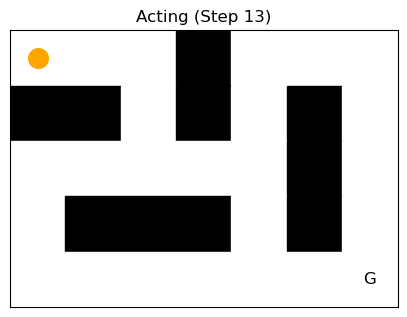

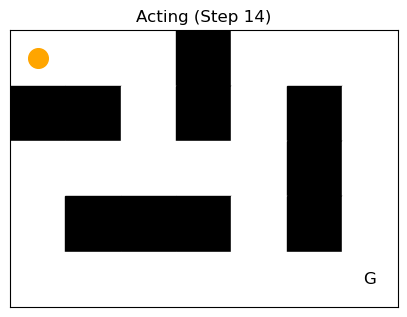

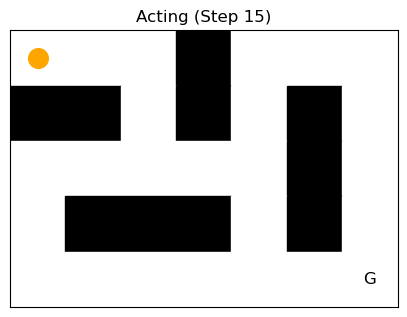

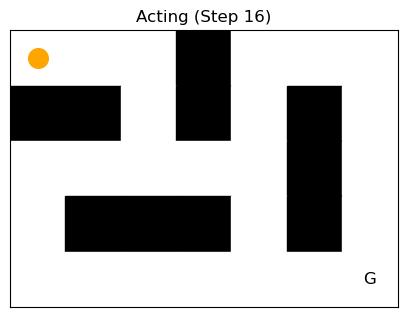

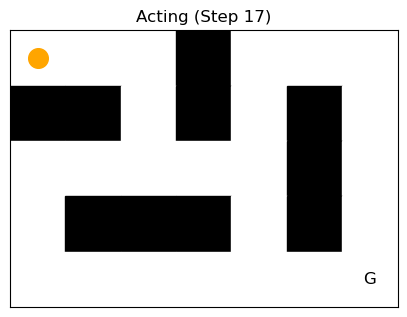

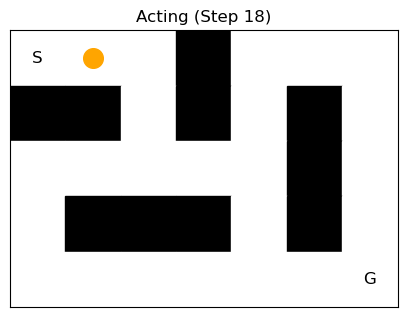

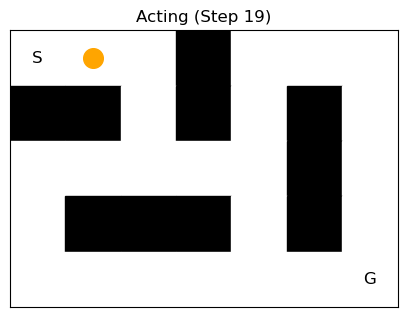

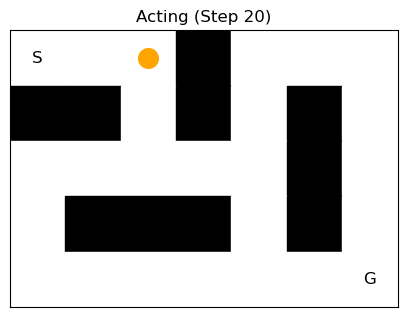

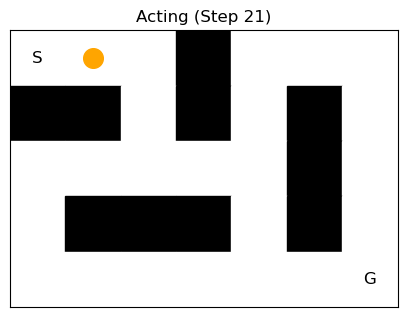

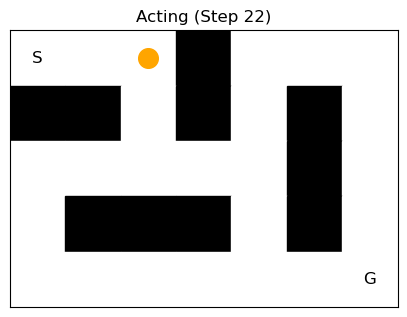

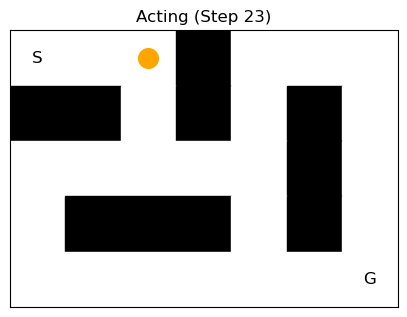

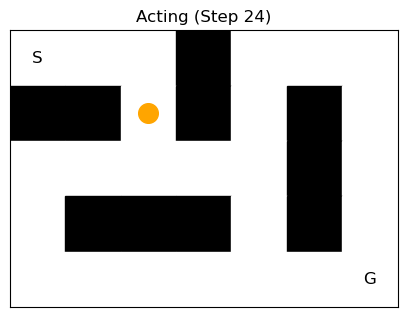

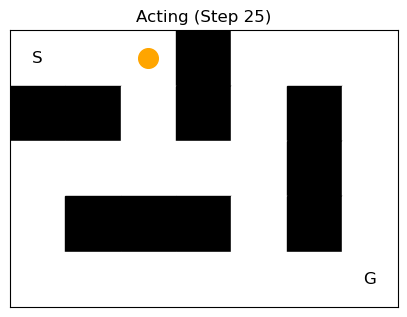

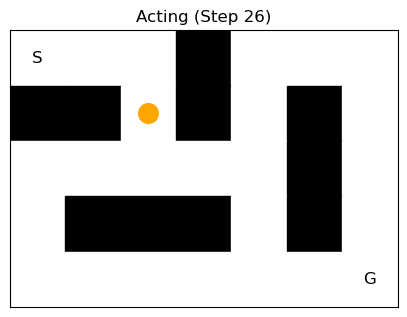

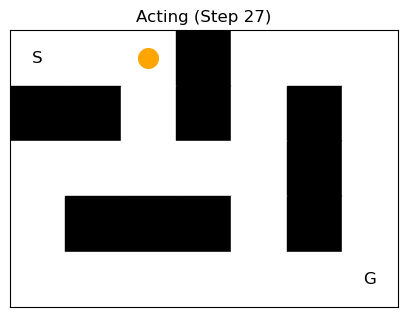

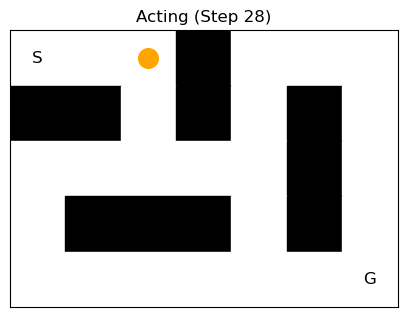

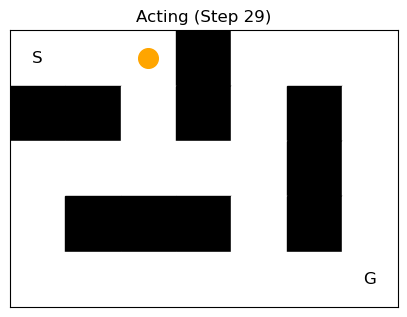

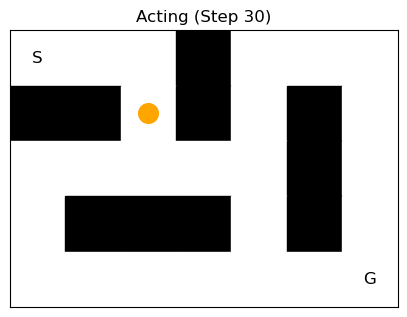

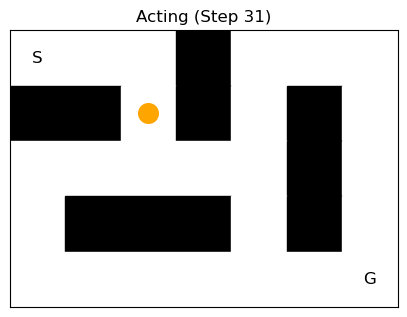

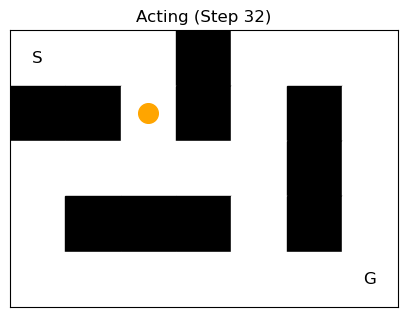

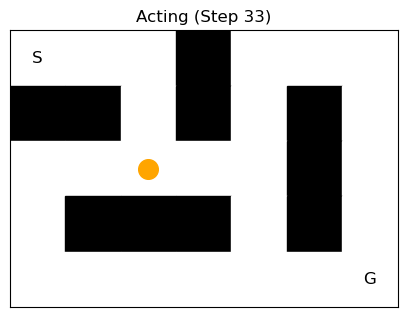

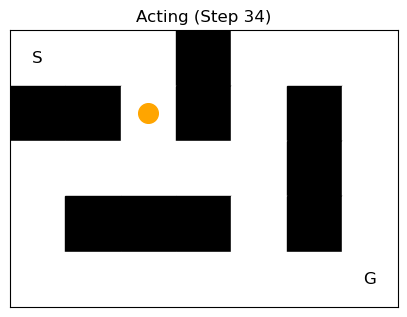

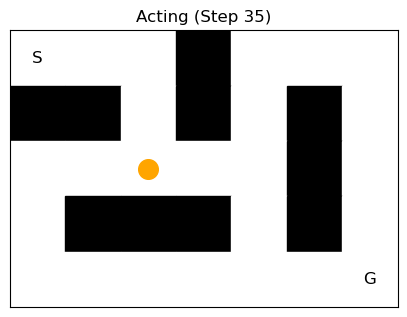

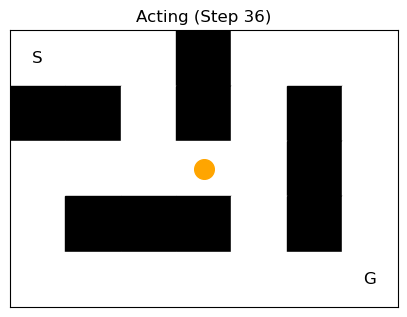

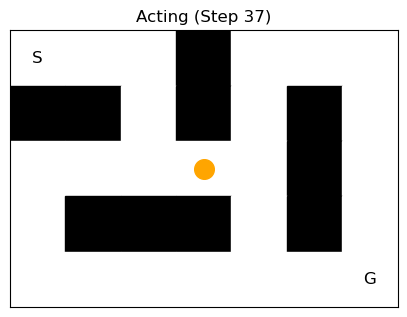

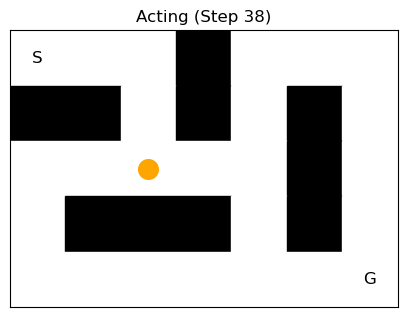

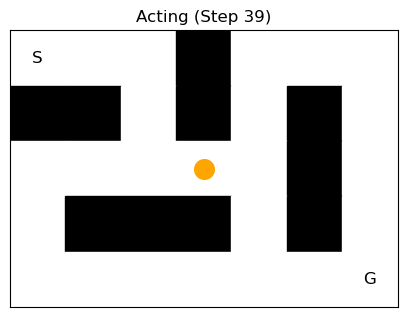

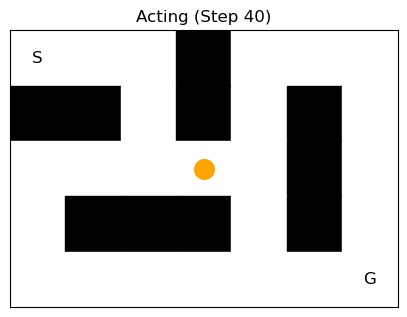

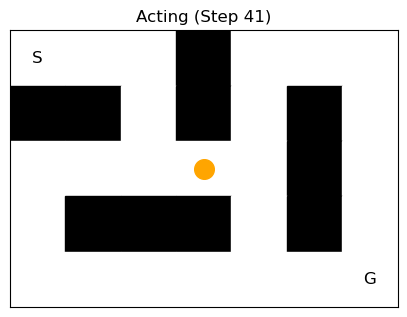

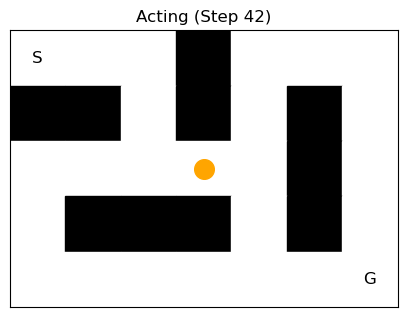

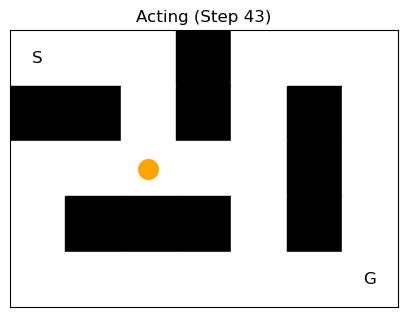

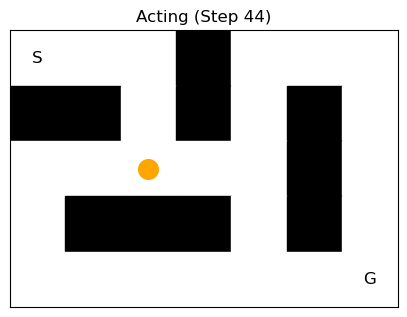

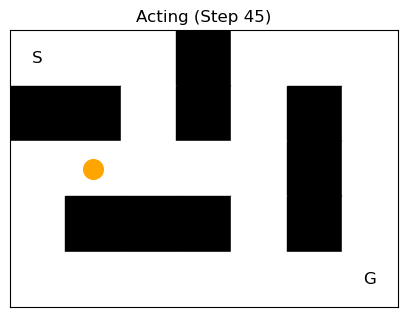

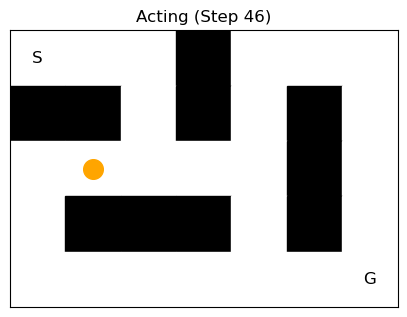

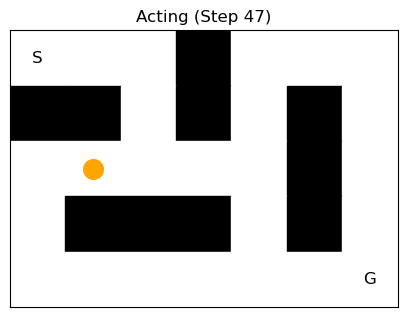

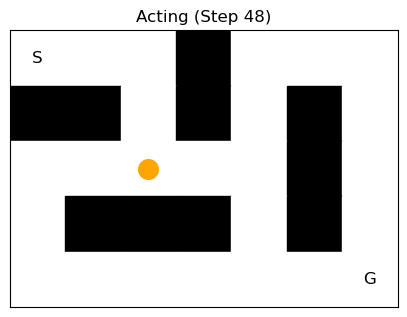

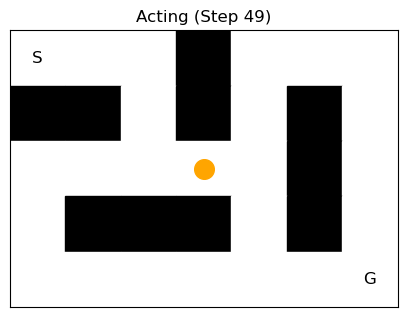

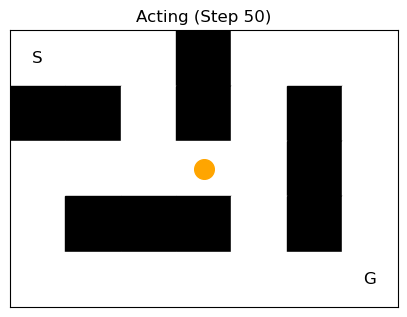

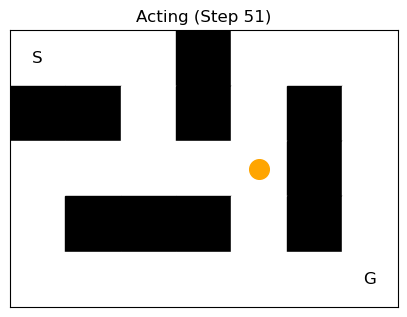

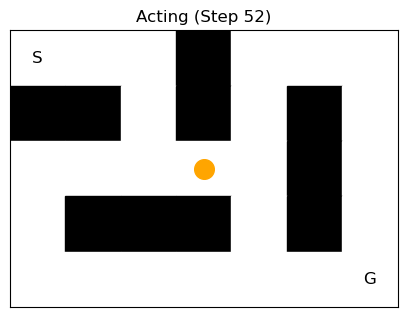

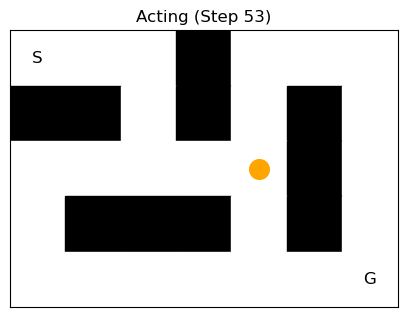

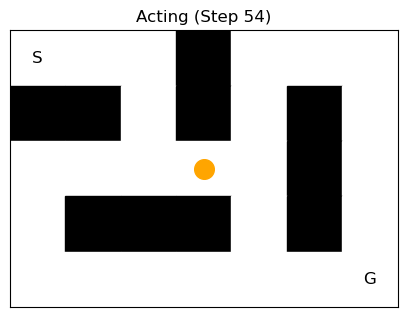

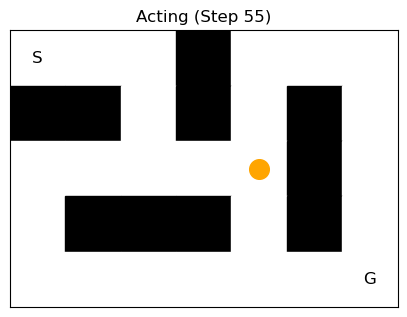

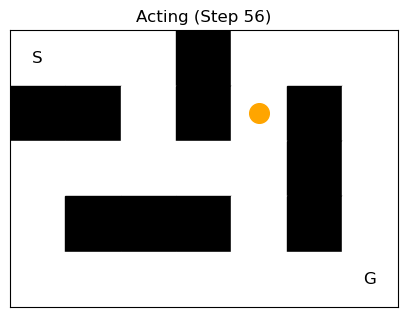

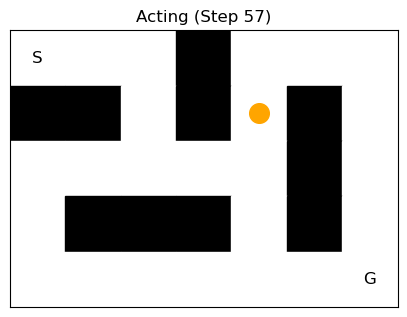

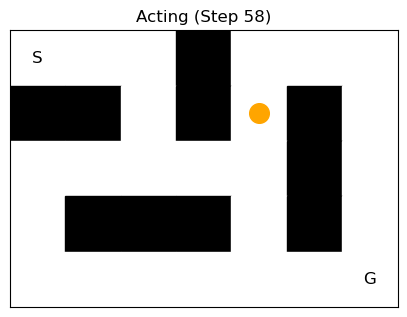

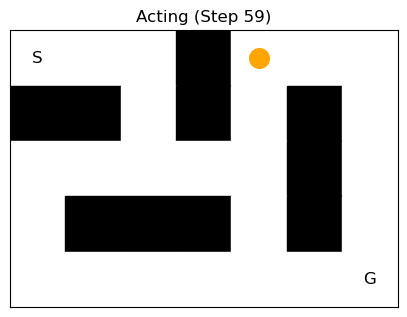

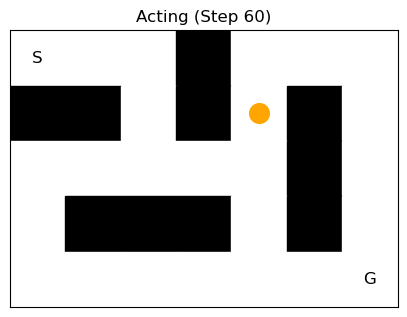

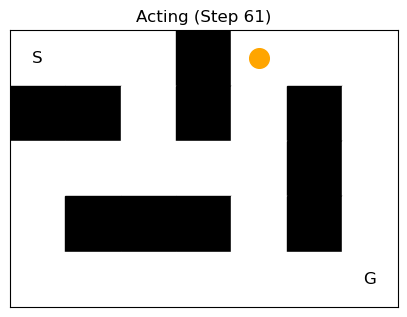

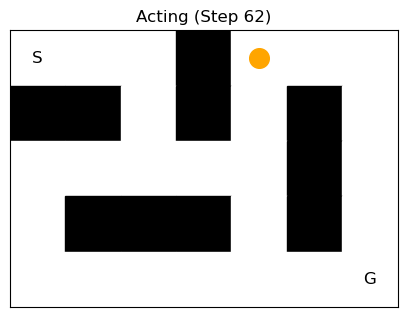

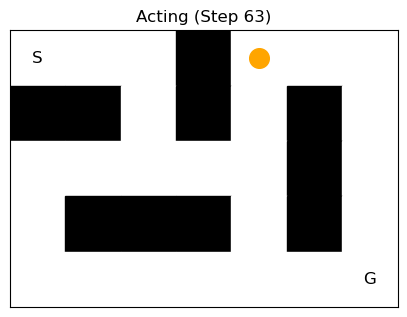

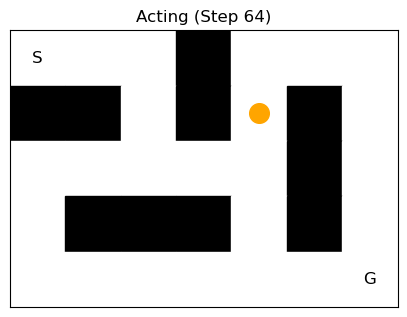

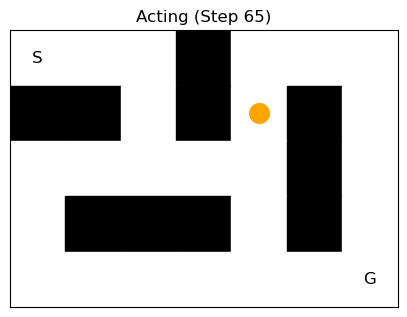

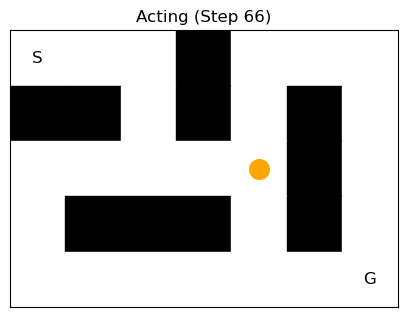

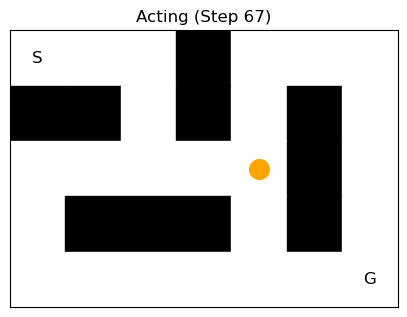

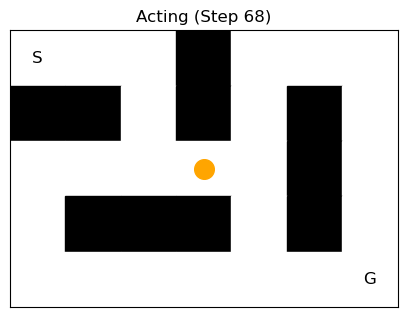

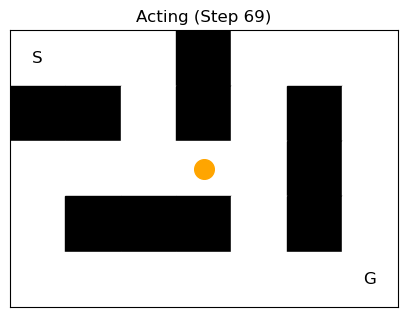

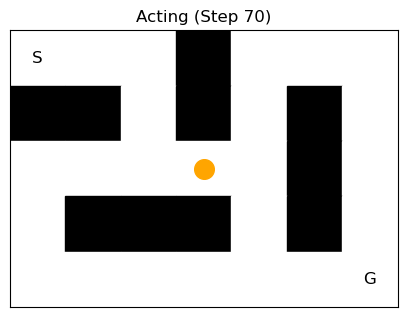

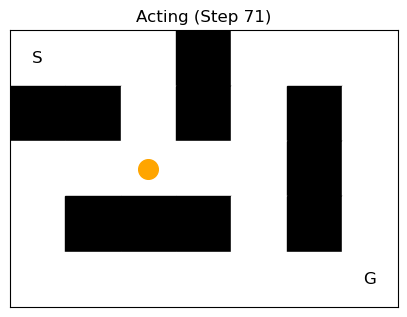

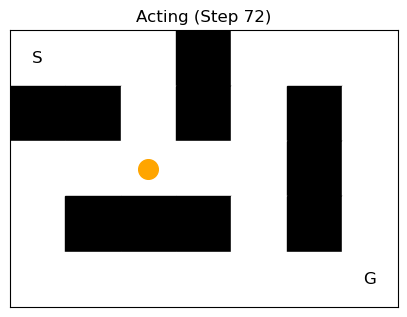

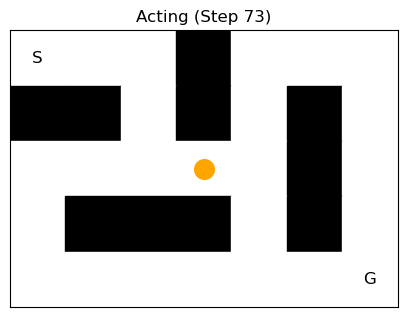

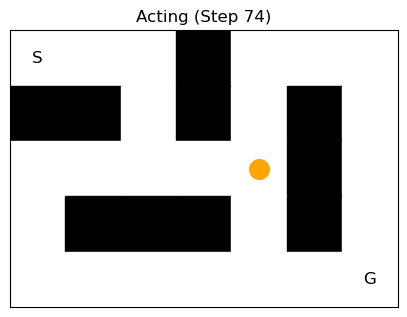

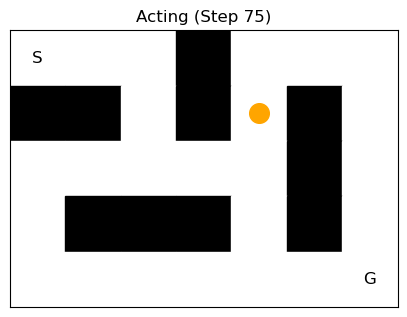

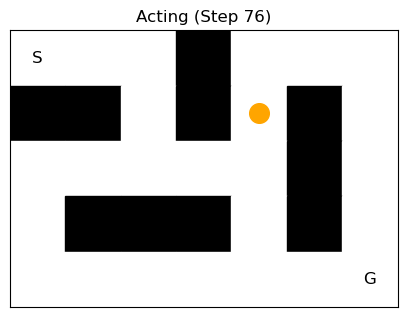

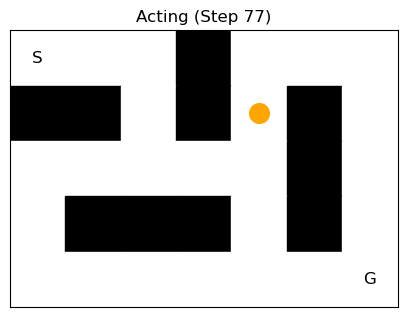

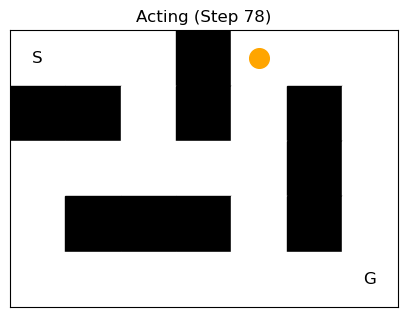

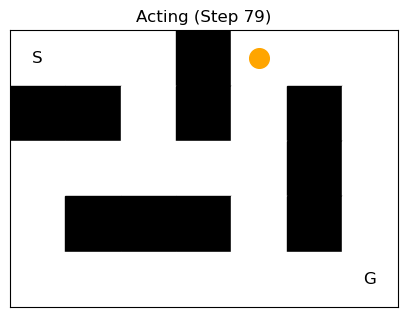

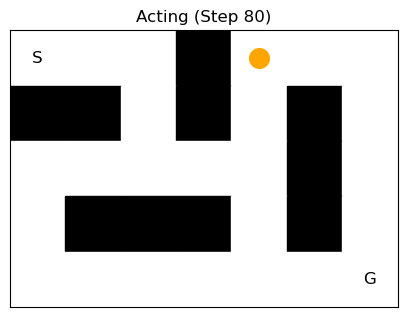

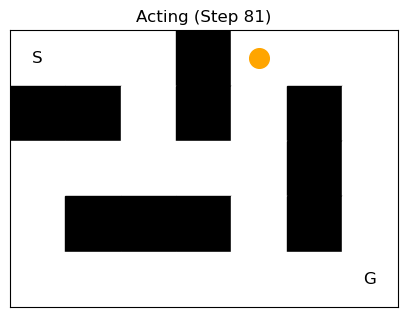

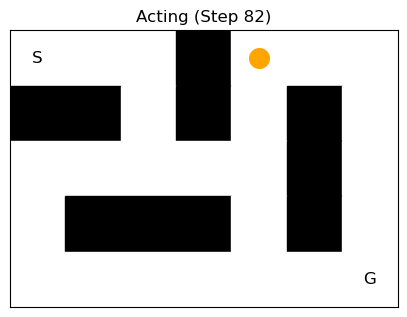

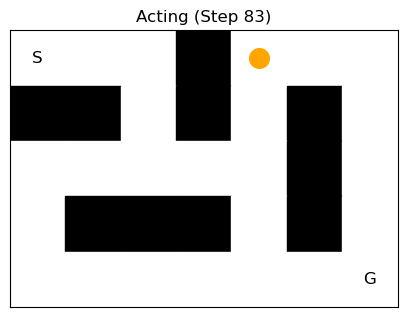

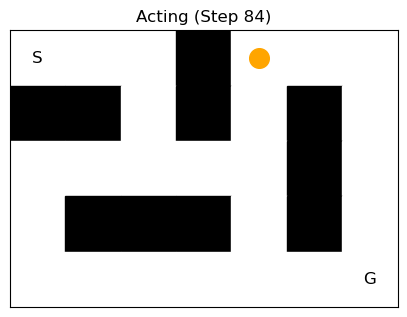

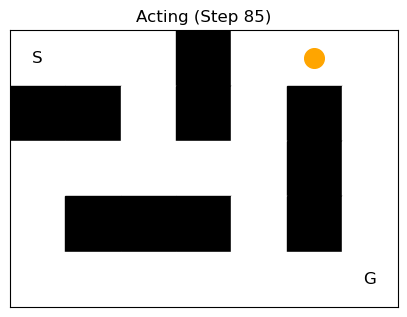

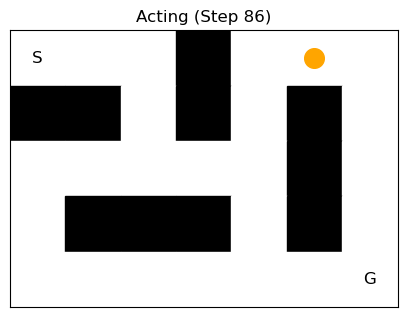

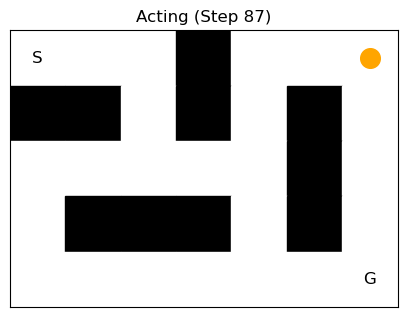

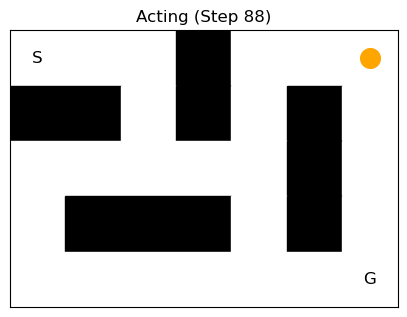

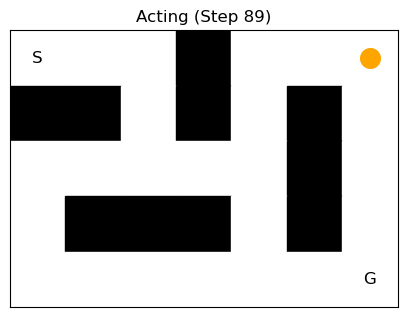

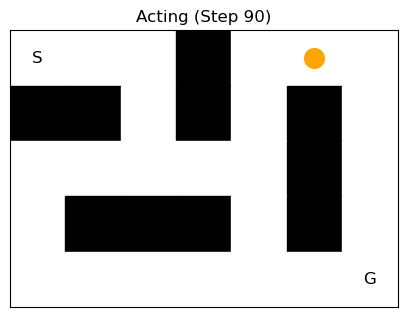

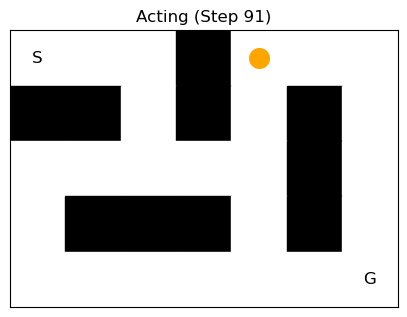

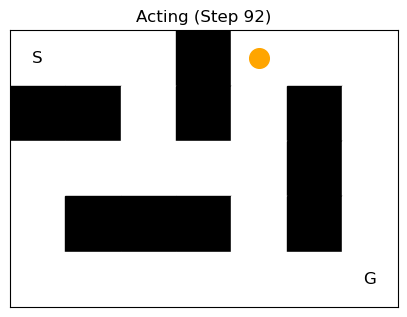

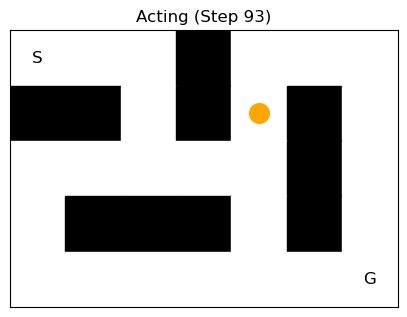

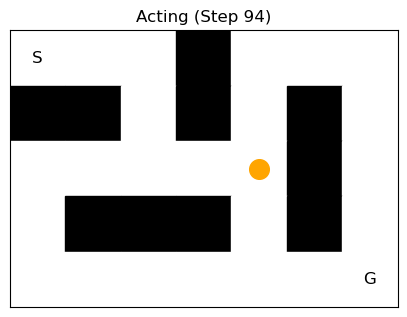

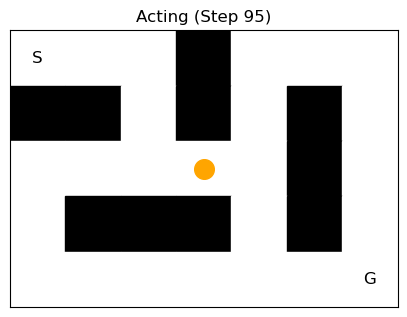

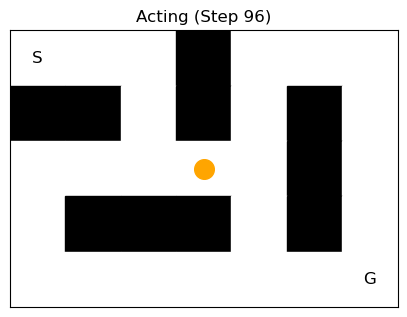

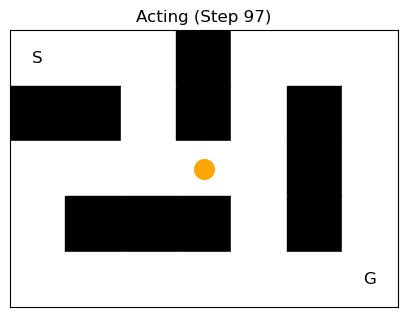

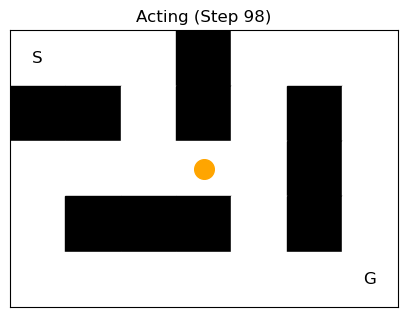

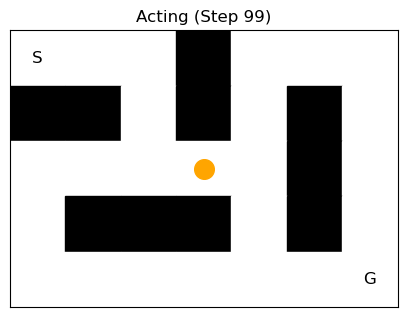

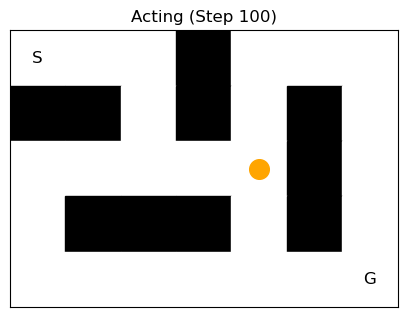

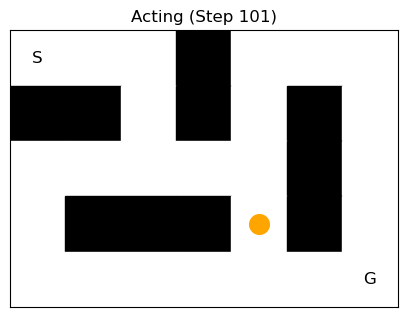

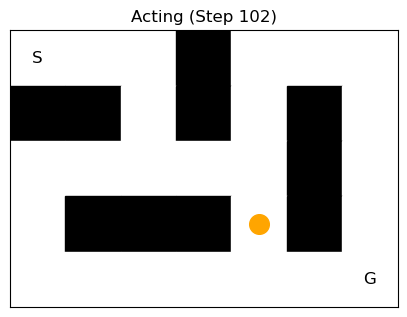

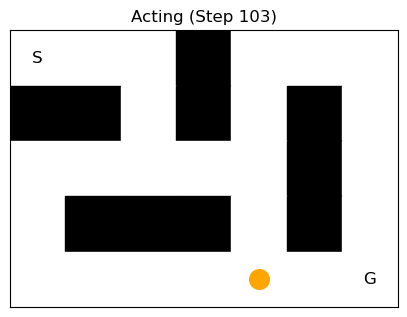

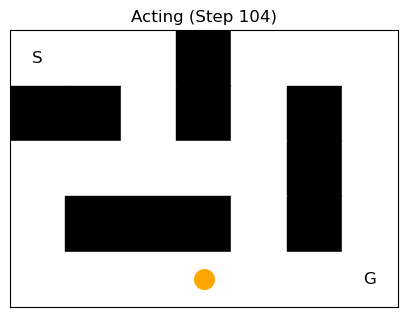

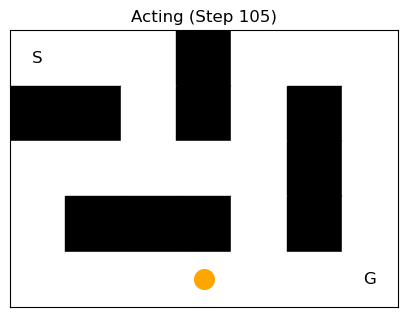

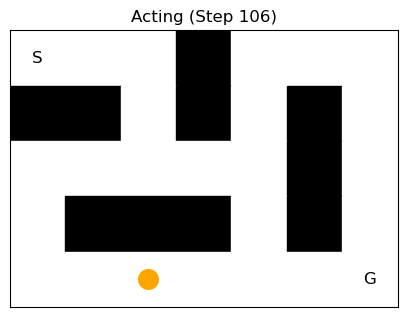

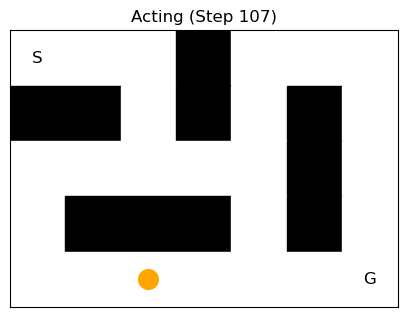

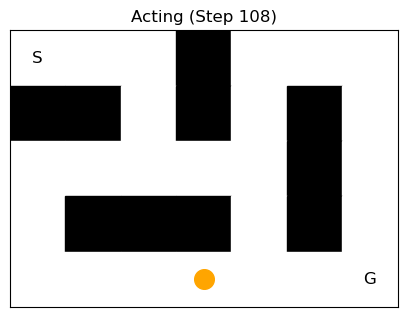

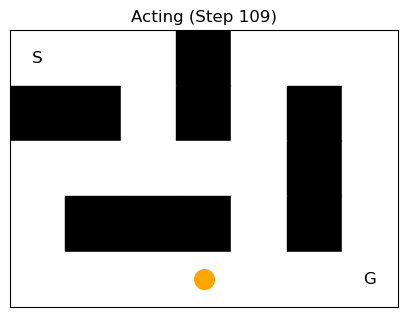

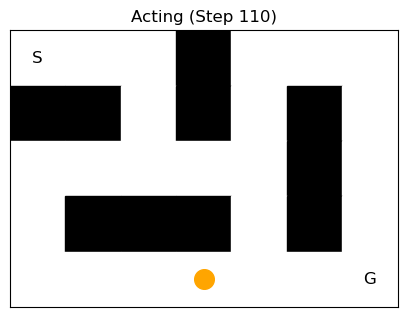

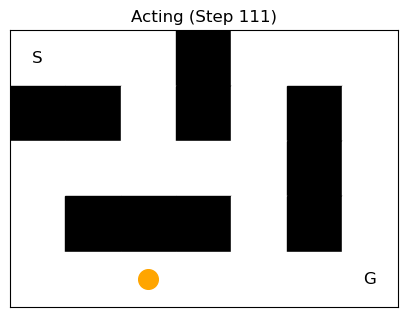

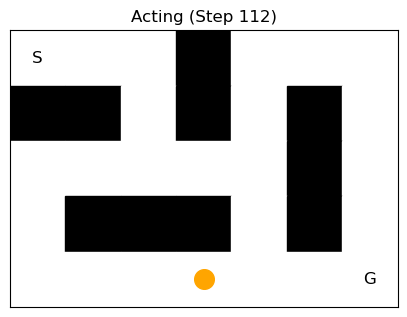

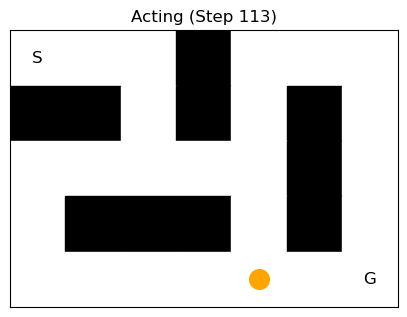

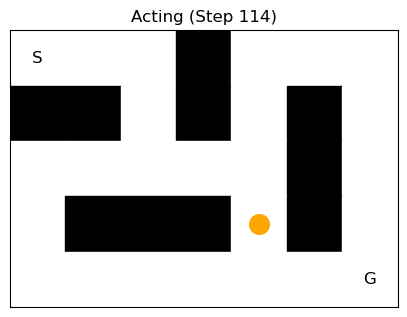

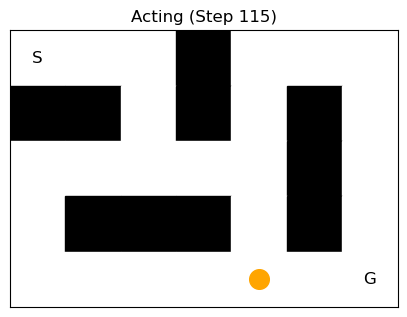

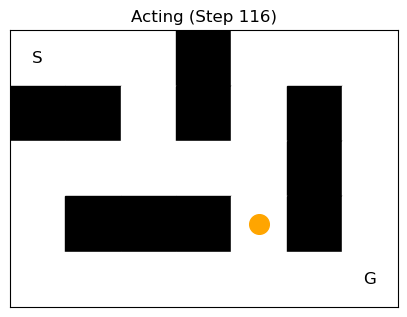

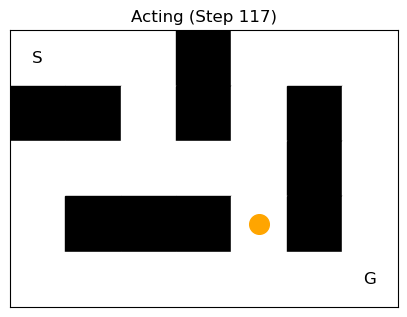

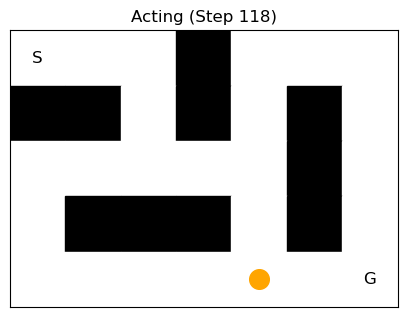

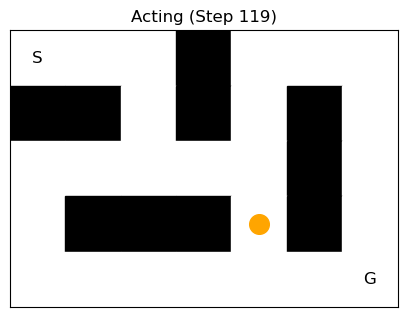

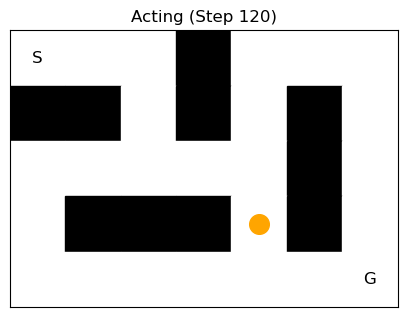

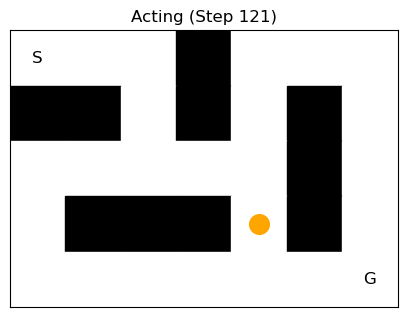

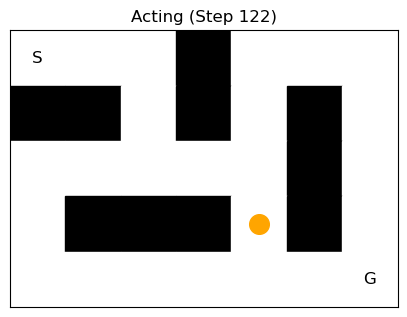

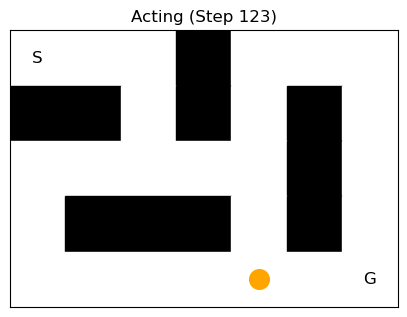

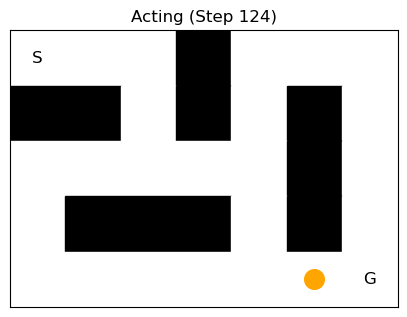

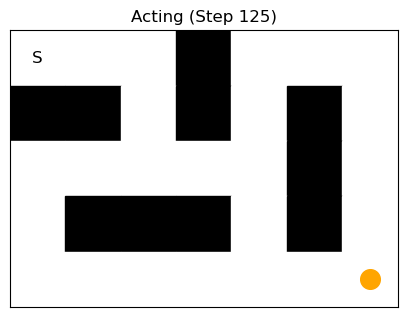

🎯 Reached goal in 125 steps


In [10]:
agent = Agent(epsilon=1.0)
run_agent_episode(env, agent, max_steps=500, delay=0.2)

Core result

Curiosity rescues planning from catastrophic failure at low exploration rates.